# AI-Based Fruit and Vegetable Classification with Nutritional Information

**Group project – Statistical Programming and Machine Learning**

This notebook combines the group's work into one document: exploratory data analysis (EDA), dataset splitting, a logistic regression baseline, a convolutional neural network (CNN), checks of what the CNN has learned, and the Streamlit application.

## Key Results at a Glance

| Model | Test accuracy | Test macro-F1 |
|---|---:|---:|
| Logistic regression on color histograms (baseline) | 74.0% | 0.652 |
| CNN with dropout | 98.5% | 0.986 |

**The CNN is clearly the stronger model on our test set.** The test photos come from the same few photography sessions as the training photos, so this score is an upper bound for new photos:

- Five of the nine classes were photographed on a single day (Section 4.6).
- A model that only sees the four **corners** of each photo reaches 0.652 macro-F1, about the same as the full baseline. Random guessing reaches 0.130 (Section 5.6).
- When photos from the same five-minute capture interval are kept together, the baseline's cross-validated macro-F1 falls from 0.654 to 0.528 (Section 5.6).

Section 7 tests whether the CNN has learned the same shortcut, and evaluates the model on our own photos.

## Contents

1. Introduction and Problem Statement
2. Setup
3. Exploratory Data Analysis (EDA)
4. Dataset Splitting
5. Baseline: Logistic Regression on Color Histograms
6. Convolutional Neural Network (CNN)
7. Does the CNN Look at the Fruit or the Background?
8. Application
9. Conclusions and Method Comparison

## How to Run This Notebook

**Folder structure.** Place this notebook in the `notebooks/` folder of the repository:

```text
group-project/
├── app.py                         Streamlit app
├── best_cnn_model.pth             CNN without dropout (saved weights)
├── best_cnn_dropout_model.pth     CNN with dropout – used by the app
├── data/
│   ├── raw_images/                the image dataset (not in Git, shared via Google Drive)
│   ├── own_photos/                our own test photos, one folder per class (optional)
│   ├── dataset_split.csv          the shared train/validation/test split
│   └── fruit_color_rois.csv       manually selected color regions (EDA)
├── notebooks/
│   └── fruit_classification.ipynb this notebook
├── results/                       saved training histories and results
└── src/                           shared functions (preprocessing, evaluation, model, prediction)
```

**Packages.** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `pillow`, `imagehash`, `opencv-python`, `torch` and `streamlit`.

**Settings.** The first code cell has two switches:

- `TRAIN_CNN = False` loads the saved CNN weights and training histories instead of retraining. Set it to `True` to retrain both CNNs. This overwrites the `.pth` files that the app uses.
- `RUN_CNN_GROUPED_CV = True` runs the cross-validation in Section 7, which trains the CNN ten times. On a laptop CPU this takes a few minutes. With `False`, the notebook loads the saved results from `results/`.

## 1. Introduction and Problem Statement

#### Business question

Can we develop a machine learning model that automatically identifies fruits and vegetables from images and combines the result with reliable nutritional information, to make food information easier to access?

#### Who uses the result?

People who want to look up or compare the nutritional content of fruits and vegetables. Instead of searching a database by name, the user takes a photo and the app shows what the food is and its nutritional values from the Swedish Food Agency (Livsmedelsverket).

#### Why machine learning?

A fruit can be photographed in countless ways: different numbers of pieces, positions, lighting, backgrounds and ripeness. It is not possible to write fixed rules such as "red and round means apple", because plums, nectarines and onions can also be red and round. A machine learning model learns the distinguishing patterns from labelled examples instead. It can then classify photos it has never seen.

#### Data

- **Images:** the fruit and vegetable image dataset provided by the course teacher, 2,633 photos in 15 folders, of which we use 2,003 photos in nine classes.
- **Nutritional information:** Livsmedelsverket's open food database (external data, used in the app).
- **Own photos:** photos we took ourselves, used to test the model outside the original dataset.

#### Target and evaluation

The target is the type of fruit or vegetable, a multi-class classification with nine classes: apple, honeydew melon, kiwi, nectarine, onion, plum, potato, Spanish pear and watermelon. Because the classes have different sizes, we evaluate with **accuracy**, **macro-F1** (every class counts equally) and **confusion matrices**.

## 2. Setup

All libraries and shared project functions are imported once here. Functions that several parts of the project use are kept in the `src/` folder, so the notebook and the app use exactly the same code:

| File | Content |
|---|---|
| `src/preprocess.py` | `load_image()` – resizes a photo to 64 × 48 pixels and scales pixel values to 0–1 |
| `src/evaluate.py` | `evaluate_predictions()` – accuracy, macro-F1 and confusion matrix for any model |
| `src/cnn_model.py` | `FruitCNNDropout` – the final CNN architecture |
| `src/predict.py` | `load_cnn_model()` and `predict_image()` – used by the app |

In [ ]:
# --- Settings -------------------------------------------------------------
TRAIN_CNN = False           # True = retrain both CNNs (overwrites the saved .pth files)
RUN_CNN_GROUPED_CV = True   # True = run the CNN cross-validation in the CNN check section
SEED = 42

# --- Standard library -----------------------------------------------------
import sys
import json
import random
from pathlib import Path

# --- Data analysis and visualization ---------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display

# --- Machine learning ------------------------------------------------------
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import f1_score

# --- Project folders ---------------------------------------------------------
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

project_folder = project_root          # name used in the baseline section
data_path = project_root / "data"
results_path = project_root / "results"
results_path.mkdir(exist_ok=True)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# --- Shared project functions ----------------------------------------------
from src.preprocess import load_image
from src.evaluate import evaluate_predictions

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Project root:", project_root)
print("Data folder exists:", data_path.is_dir())

## 3. Exploratory Data Analysis (EDA)

The EDA examines the folder structure, class distribution, image properties, possible duplicates, colors, brightness and sharpness. Its main purpose is to find problems that could affect the models, such as class imbalance, near-duplicate photos and differences in background between classes.

### 3.1 Inspect the Data Directory

This step examines the contents of the `data` directory to understand how the dataset and related files are organized.

The code lists all files and subdirectories in alphabetical order and distinguishes between folders and files.

This helps verify the expected project structure before accessing the image dataset.

In [ ]:
# Check the contents of the data folder

if data_path.exists():

    print("Contents of the data folder:\n")

    for item in sorted(data_path.iterdir()):
        if item.is_dir():
            print(f"Folder: {item.name}")
        else:
            print(f"File: {item.name}")

else:
    print("Data folder not found!")

Contents of the data folder:

File: data.txt
File: fruit_color_rois.csv
Folder: raw_images


### 3.2 Locate and Inspect the Raw Image Dataset

We locate the `raw_images` directory and check that it exists.

The code lists its subfolders alphabetically to identify the original dataset categories before selecting and mapping classes for classification.

In [ ]:
# Define the folder containing the raw images
raw_images_path = data_path / "raw_images"

print("Raw images folder:", raw_images_path)
print("\nOriginal dataset categories:\n")

if raw_images_path.is_dir():
    for item in sorted(raw_images_path.iterdir()):
        if item.is_dir():
            print(f"Folder: {item.name}")
else:
    print("Raw images folder not found!")

Raw images folder: c:\Users\JRD\GroupProjectGrupp1BI25\group-project\data\raw_images

Original dataset categories:

Folder: agata_potato
Folder: asterix_potato
Folder: cashew
Folder: diamond_peach
Folder: fuji_apple
Folder: granny_smith_apple
Folder: honneydew_melon
Folder: kiwi
Folder: nectarine
Folder: onion
Folder: orange
Folder: plum
Folder: spanish_pear
Folder: taiti_lime
Folder: watermelon


### 3.3 Identify and Count Image Files

This step identifies all image files in the original dataset, including images stored in class subfolders.

The code searches for supported image formats, counts the total number of image files, and displays five example file paths.

This provides an initial overview of the dataset size and verifies that images can be located within the expected folder structure.

In [ ]:
# Supported image file formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find all image files, including images in subfolders
image_files = sorted(
    file
    for file in raw_images_path.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
)

print("Total number of images:", len(image_files))

# Show a few example file paths
print("\nExample image files:")

for file in image_files[:5]:
    print(file.relative_to(raw_images_path))

Total number of images: 2633

Example image files:
agata_potato\agata_potato_001.jpg
agata_potato\agata_potato_002.jpg
agata_potato\agata_potato_003.jpg
agata_potato\agata_potato_004.jpg
agata_potato\agata_potato_005.jpg


### 3.4 Image Dimensions and File Integrity

This step examines the dimensions and readability of images in the original dataset before class selection.

The code attempts to open each image, records its width and height, and identifies any files that cannot be opened.

This helps us understand whether the dataset has consistent image dimensions and detect potential file integrity issues before further analysis.

In [ ]:
from PIL import Image
from collections import Counter

# Store image dimensions
image_dimensions = []

# Track images that cannot be opened
invalid_images = []

for image_path in image_files:
    try:
        with Image.open(image_path) as img:
            image_dimensions.append(img.size)

    except Exception as e:
        invalid_images.append((image_path, str(e)))

# Count the most common image dimensions
dimension_counts = Counter(image_dimensions)

print("Most common image dimensions:\n")

for dimension, count in dimension_counts.most_common(10):
    print(f"{dimension}: {count} images")

print("\nUnique image dimensions:", len(dimension_counts))
print("Successfully opened images:", len(image_dimensions))
print("Images that could not be opened:", len(invalid_images))

Most common image dimensions:

(1024, 768): 2633 images

Unique image dimensions: 1
Successfully opened images: 2633
Images that could not be opened: 0


#### 3.4.1 Image Dimensions and File Integrity – Findings

The original dataset contains 2,633 images, all with identical dimensions of 1024 × 768 pixels.

All 2,633 images were successfully opened using Pillow, and no unreadable files were identified during this check.

The consistent image dimensions simplify the initial dataset analysis. However, image resizing may still be required during preprocessing to meet the input requirements of the classification models.

This check confirms that the images can be opened and their dimensions read, but does not guarantee that every image file is completely free from corruption.

**Pillow (PIL)**

Pillow is a Python library used for image processing. It allows images to be opened, converted, modified, and saved. In this project, Pillow was used to read images, convert them to RGB or grayscale, and prepare pixel data for color and brightness analysis.

### 3.5 Image Formats and Color Modes

This step examines the image formats and color modes in the original dataset before class selection.

The code reads the format and color mode of each image and summarizes how frequently each value occurs.

This helps determine whether the dataset has a consistent image representation and whether format conversion may be needed during preprocessing.

**RGB Values (Red, Green, Blue)**

RGB values represent the color of a pixel using three color channels: red, green, and blue. Each channel has an intensity ranging from 0 to 255.

In this project, RGB values were used to analyze the colors of selected fruit and vegetable regions. The mean RGB values describe the average color intensity within each selected region.

**Why Red, Green, and Blue?**

RGB is used because human color vision relies on three types of cone cells sensitive to different wavelengths of light. By combining red, green, and blue light at different intensities, digital displays can reproduce a wide range of colors. This makes RGB a standard color representation for digital images.

In [ ]:
import pandas as pd

image_metadata = []

for image_path in image_files:
    with Image.open(image_path) as img:
        image_metadata.append({
            "image_format": img.format,
            "color_mode": img.mode
        })

image_metadata_df = pd.DataFrame(image_metadata)

print("Image formats:")
display(
    image_metadata_df["image_format"]
    .value_counts()
    .rename_axis("format")
    .reset_index(name="image_count")
)

print("Color modes:")
display(
    image_metadata_df["color_mode"]
    .value_counts()
    .rename_axis("mode")
    .reset_index(name="image_count")
)

Image formats:


,format,image_count
0,JPEG,2633


Color modes:


,mode,image_count
0,RGB,2633


#### 3.5.1 Image Formats and Color Modes – Findings

All 2,633 images in the original dataset are stored in JPEG format and use the RGB color mode (red, green and blue).

This indicates that the dataset has a consistent image format and color representation. No conversion between different color modes is required based on these findings.

However, additional preprocessing, such as resizing and pixel value normalization, may still be necessary before model training.

### 3.6 Dataset Selection and Class Mapping

The original dataset contains 15 fruit and vegetable classes.

To align the dataset with the project objectives, four classes are excluded from the analysis:

- Cashew
- Diamond peach
- Orange
- Tahiti lime

Additionally, different varieties of apples and potatoes are combined into broader categories:

- Fuji apple and Granny Smith apple are mapped to `apple`.
- Agata potato and Asterix potato are mapped to `potato`.

This results in 9 target classes.

The original image files are preserved. Filtering and class mapping are performed in Python without modifying the raw dataset.

In [ ]:
# Classes excluded from the analysis
excluded_classes = {
    "cashew",
    "diamond_peach",
    "orange",
    "taiti_lime"
}

# Mapping of original classes to broader categories
class_mapping = {
    "fuji_apple": "apple",
    "granny_smith_apple": "apple",
    "agata_potato": "potato",
    "asterix_potato": "potato"
}

# Create a list of image paths and their target labels
dataset = []

for image_path in image_files:
    original_class = image_path.parent.name

    # Skip excluded classes
    if original_class in excluded_classes:
        continue

    # Map apple and potato varieties to broader categories
    target_class = class_mapping.get(
        original_class,
        original_class
    )

    dataset.append({
        "image_path": image_path,
        "original_class": original_class,
        "target_class": target_class
    })

# Display dataset information
print("Original number of images:", len(image_files))
print("Filtered number of images:", len(dataset))

# Display the remaining target classes
target_classes = sorted({
    item["target_class"] for item in dataset
})

print("\nNumber of target classes:", len(target_classes))
print("\nTarget classes:")

for class_name in target_classes:
    print("-", class_name)

Original number of images: 2633
Filtered number of images: 2003

Number of target classes: 9

Target classes:
- apple
- honneydew_melon
- kiwi
- nectarine
- onion
- plum
- potato
- spanish_pear
- watermelon


#### 3.6.1 Dataset Selection and Class Mapping – Findings

The original dataset contains 2,633 images across 15 classes.

After excluding four original classes and combining different apple and potato varieties into broader categories, the dataset contains 2,003 images across 9 target classes.

A total of 630 images were excluded from the classification task.

The class mapping was performed in Python without modifying the original image files. This preserves the raw dataset while allowing subsequent analyses to focus on the selected target classes.

### 3.7 Class Distribution Analysis

This step examines how the 2,003 selected images are distributed across the nine target classes.

The code converts the filtered dataset into a pandas DataFrame, counts the images in each class, and calculates each class's percentage of the dataset.

The resulting table helps identify class imbalance, which may influence model training and evaluation.

In [ ]:
# Convert the filtered dataset into a DataFrame
df = pd.DataFrame(dataset)

# Count images per target class
class_counts = df["target_class"].value_counts().sort_index()

# Calculate percentage distribution
class_percentages = (class_counts / len(df) * 100).round(1)

# Create a summary table
class_distribution = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage (%)": class_percentages
})

# Add a total row
class_distribution.loc["Total"] = [
    class_counts.sum(),
    100.0
]

# Display the results
print("Class Distribution:\n")
display(class_distribution)

print("\nTotal images:", len(df))
print("Total classes:", df["target_class"].nunique())

Class Distribution:



,Number of Images,Percentage (%)
target_class,,
apple,367,18.3
honneydew_melon,145,7.2
kiwi,171,8.5
nectarine,247,12.3
onion,75,3.7
plum,264,13.2
potato,383,19.1
spanish_pear,159,7.9
watermelon,192,9.6



Total images: 2003
Total classes: 9


#### 3.7.1 Class Distribution – Findings

The dataset contains 2,003 images across nine classes, with an uneven class distribution.

Potato is the largest class with 383 images (19.1%), while onion is the smallest with 75 images (3.7%). This means potato has about five times as many images as onion.

This imbalance may make smaller classes harder to learn. Therefore, we will evaluate the models using both overall accuracy and macro-F1, which gives equal importance to each class.

**Overall Accuracy and Macro-F1**

- **Overall Accuracy:** The proportion of all images correctly classified by the model.
- **Macro-F1:** The average F1-score across all classes, giving each class equal importance regardless of its size. F1-score combines precision and recall.

Both metrics are used because the dataset is imbalanced. Accuracy measures overall performance, while Macro-F1 helps evaluate whether the model performs well across all fruit and vegetable classes.


******** OBS! OBS! OBS! ********

Overall Accuracy: Andelen bilder som modellen klassificerar korrekt av alla bilder. Om modellen klassificerar 90 av 100 bilder rätt är accuracy 90 %.

Macro-F1: Beräknar F1-score för varje klass och tar sedan medelvärdet. F1 kombinerar precision (hur många av modellens förutsägelser för en klass som är korrekta) och recall (hur många av klassens faktiska bilder som modellen hittar). Alla klasser får lika stor vikt, oavsett hur många bilder de innehåller. 

Eftersom vårt dataset är obalanserat kan modellen få hög accuracy genom att vara bra på de större klasserna, men ändå prestera dåligt på exempelvis onion, som har färre bilder. Macro-F1 hjälper oss att upptäcka det.

#### 3.7.2 Class Distribution Visualization

This step visualizes the number of images in each of the nine target classes using a bar chart.

The chart makes it easier to compare class sizes and identify differences in the number of available images.

This provides a visual overview of the class imbalance identified in the previous analysis.

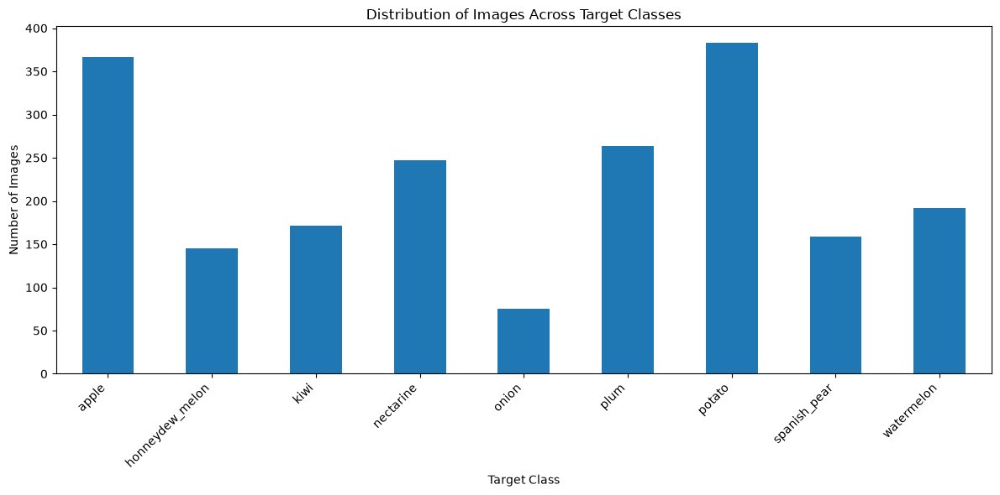

In [ ]:
import matplotlib.pyplot as plt

# Create a bar chart showing the class distribution
plt.figure(figsize=(12, 6))

class_counts.plot(kind="bar")

plt.title("Distribution of Images Across Target Classes")
plt.xlabel("Target Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

#### 3.7.3 Class Distribution Visualization – Findings

The bar chart confirms that the selected dataset is unevenly distributed across the nine target classes.

Potato and apple have the highest image counts, while onion has substantially fewer images than the other classes.

The visualization highlights the class imbalance and reinforces the importance of evaluating model performance across individual classes, rather than relying only on overall accuracy.

### 3.8 Visual Inspection of the Dataset

This step examines example images from each of the nine target classes to better understand their visual characteristics.

One image from each class is displayed in a 3 × 3 grid, allowing an initial comparison of object appearance, backgrounds, lighting conditions, and image quality.

Visual inspection can help identify potential classification challenges, such as similarities between classes. However, one image per class is not sufficient to assess the full variation within each class.

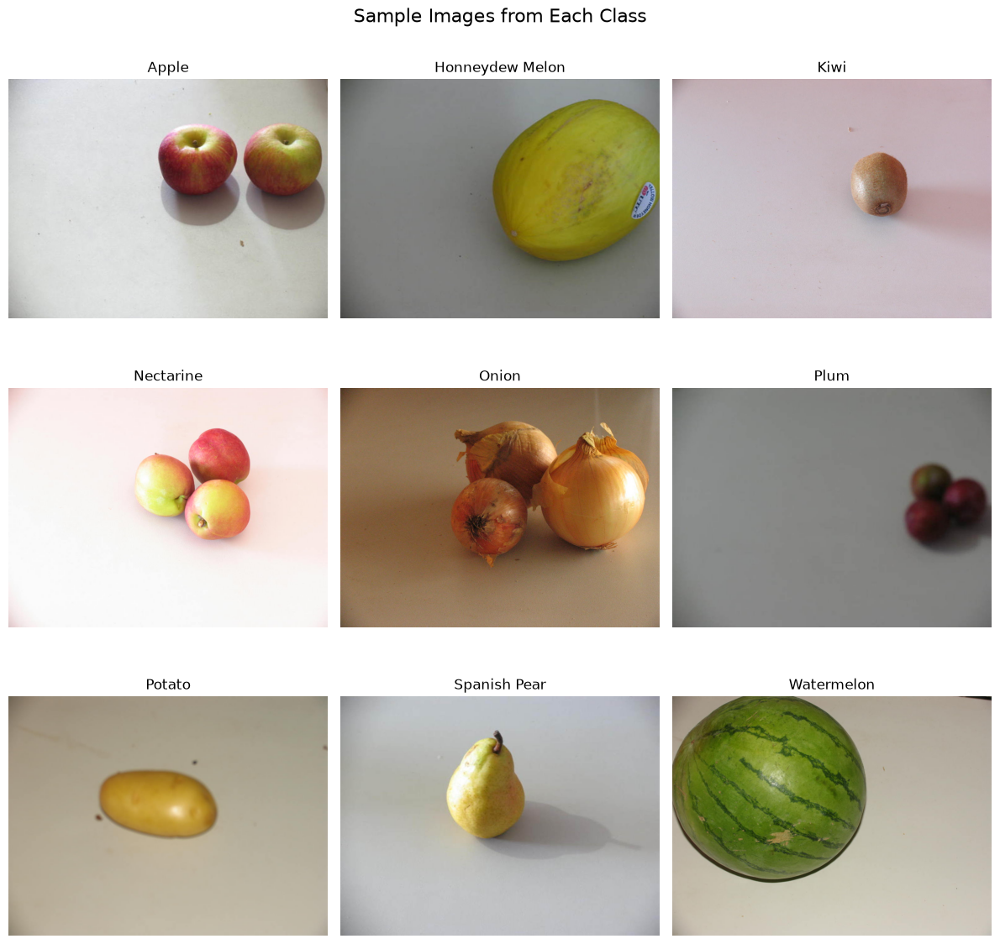

In [ ]:
# Get all target classes
classes = sorted(df["target_class"].unique())

# Create a figure with 3 rows and 3 columns
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

# Display one example image from each class
for ax, class_name in zip(axes.flat, classes):

    # Select the first image from the class
    sample = df[df["target_class"] == class_name].iloc[0]

    # Open the image
    with Image.open(sample["image_path"]) as img:
        image = img.convert("RGB")

    # Display the image
    ax.imshow(image)
    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Sample Images from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

#### 3.8.1 Visual Inspection – Findings

The sample images show differences in backgrounds, lighting, sharpness, and object size across the nine classes.

Background colors range from white and gray to pink and brown. Some images are darker or less sharp than others, particularly examples of plum and potato.

Images also vary in the number and size of objects, and some contain shadows, surface markings, or labels.

These differences may affect classification and suggest that the models need to handle varied image conditions.

**Note:** These observations are based on only one image per class, so they may not represent the entire dataset.

### 3.9 Intra-Class Visual Variation

This step explores visual variation within a target class using six randomly selected images from the apple class as an illustrative example.

The apple class was selected because two original categories, fuji_apple and granny_smith_apple, were merged into one target class. This makes it particularly useful for examining differences in color, shape, lighting, and appearance within the same category.

The purpose is to demonstrate that images belonging to the same class can look different, which creates an additional challenge for classification models.

Limitation: This visualization only examines the apple class and does not provide a complete assessment of intra-class variation across all nine target classes.

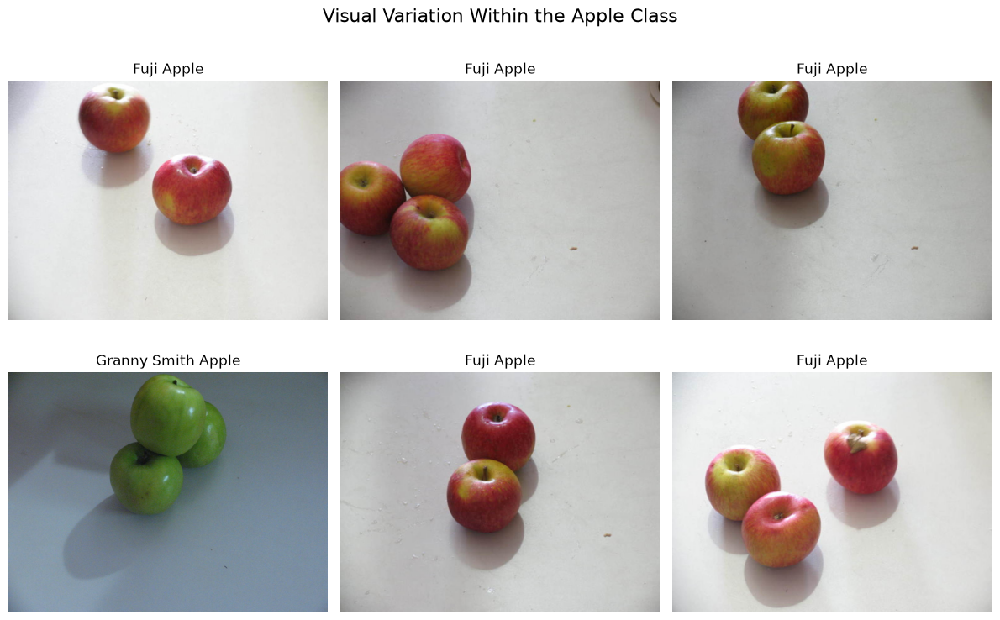

In [ ]:
# Select the class to examine
selected_class = "apple"

# Get all images belonging to the selected class
class_images = df[df["target_class"] == selected_class]

# Select 6 random images for visual inspection
sample_images = class_images.sample(
    n=min(6, len(class_images)),
    random_state=42
)

# Create a figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Display the selected images
for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):

    with Image.open(row["image_path"]) as img:
        image = img.convert("RGB")

    ax.imshow(image)
    ax.set_title(row["original_class"].replace("_", " ").title())
    ax.axis("off")

# Hide unused axes if fewer than 6 images are available
for ax in axes.flat[len(sample_images):]:
    ax.axis("off")

plt.suptitle(
    f"Visual Variation Within the {selected_class.title()} Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

#### 3.9.1 Intra-Class Visual Variation – Findings

The six sampled apple images show variation within the same target class.

Five images contain Fuji apples with red, yellow, and green tones, while one contains predominantly green Granny Smith apples. Lighting, shadows, positioning, and the number of apples also vary.

This highlights a classification challenge: the model must recognize different apple varieties as the same class, rather than relying only on color.

These observations are based on six randomly selected images and may not represent the entire apple class.

### 3.10 Exact Duplicate Detection Using SHA-256

This step checks whether the selected dataset contains exact duplicate image files.

A SHA-256 hash is calculated for each of the 2,003 image files. Files with identical content produce the same hash value, allowing exact duplicates to be identified.

Exact duplicates could cause data leakage if identical images appear in both the training and evaluation datasets, potentially leading to overly optimistic model performance.

This analysis detects files with identical binary content. Visually similar images saved as different files may have different hashes and will be investigated separately using perceptual hashing.

In [ ]:
import hashlib
from collections import defaultdict

# Function to calculate SHA-256 hash
def calculate_hash(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Store image paths grouped by hash
hash_groups = defaultdict(list)

# Calculate hashes for all images
for image_path in df["image_path"]:
    image_hash = calculate_hash(image_path)
    hash_groups[image_hash].append(image_path)


# Identify duplicate groups
duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}

# Count duplicate files beyond the first copy
duplicate_count = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

# Display results
print("Total images:", len(df))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_count)

# Display examples if duplicates exist
if duplicate_groups:
    print("\nExamples of duplicate images:\n")

    for image_hash, paths in list(duplicate_groups.items())[:5]:
        print("Duplicate group:")

        for path in paths:
            print(" -", path)

        print()

else:
    print("\nNo exact file duplicates detected.")

Total images: 2003
Unique file hashes: 2003
Duplicate groups: 0
Extra duplicate files: 0

No exact file duplicates detected.


#### 3.10.1 Exact Duplicate Detection – Findings

The SHA-256 analysis identified 2,003 unique file hashes among the 2,003 selected images.

No exact duplicate files were detected, and no duplicate groups were found.

This indicates that the selected dataset does not contain files with identical binary content, reducing one potential source of data leakage.

However, SHA-256 cannot detect visually similar images with different file contents. Therefore, perceptual hashing (pHash) will be used in the next step to investigate potential near-duplicates.

Identifying near-duplicates is important before splitting the dataset into training, validation, and test sets, as highly similar images across these sets could lead to overly optimistic evaluation results.

### 3.11 Near-Duplicate Detection Using Perceptual Hashing (pHash)

This step calculates a perceptual hash (pHash) for each of the 2,003 selected images.

Unlike SHA-256, which compares file contents, pHash creates a fingerprint based on an image's visual characteristics.

Images with identical or similar perceptual hashes may be visually similar, even when their file contents differ.

The calculated hashes are stored in the DataFrame for further analysis of potential near-duplicates and data leakage risks.

In [ ]:
import imagehash

# Store perceptual hashes
phashes = []

# Calculate pHash for each image
for image_path in df["image_path"]:

    with Image.open(image_path) as img:
        phash = imagehash.phash(img.convert("RGB"))

    phashes.append(phash)

# Add hashes to the DataFrame
df["phash"] = phashes

# Display results
print("Total images:", len(df))
print("Calculated perceptual hashes:", len(phashes))
print("Unique perceptual hashes:", df["phash"].nunique())

Total images: 2003
Calculated perceptual hashes: 2003
Unique perceptual hashes: 1998


#### 3.11.1 Perceptual Hash Calculation – Findings

Perceptual hashes were successfully calculated for all 2,003 selected images.

The analysis identified 1,998 unique pHash values, meaning that some images share the same perceptual fingerprint.

In contrast, the earlier SHA-256 analysis found no files with identical binary content.

This suggests that the dataset may contain visually similar images that cannot be detected through exact file hashing.

However, identical pHash values do not necessarily mean that images are duplicates. Further analysis is required to identify the matching groups and visually inspect the images.

#### 3.11.2 Identical Perceptual Hash Groups

We identify images with identical perceptual hash (pHash) values and display them side by side for visual inspection.

The code reports how many matching groups were found and how many images they contain.

Matching pHash values suggest visual similarity but do not guarantee identical images. We therefore inspect the groups to assess whether they contain potential duplicates.

Number of groups with identical pHash values: 4
Number of images involved: 9


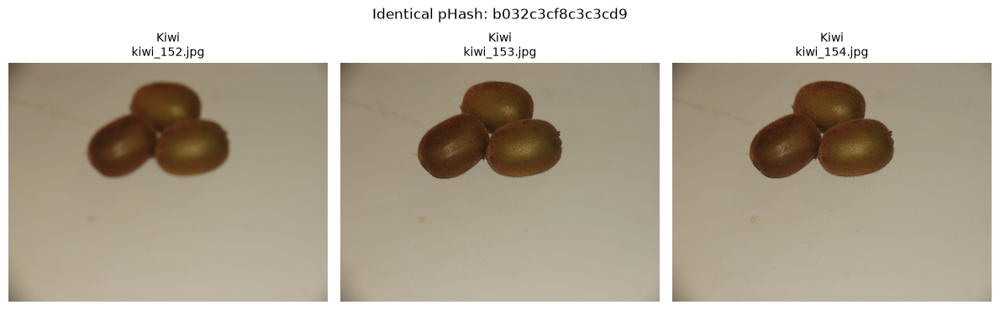

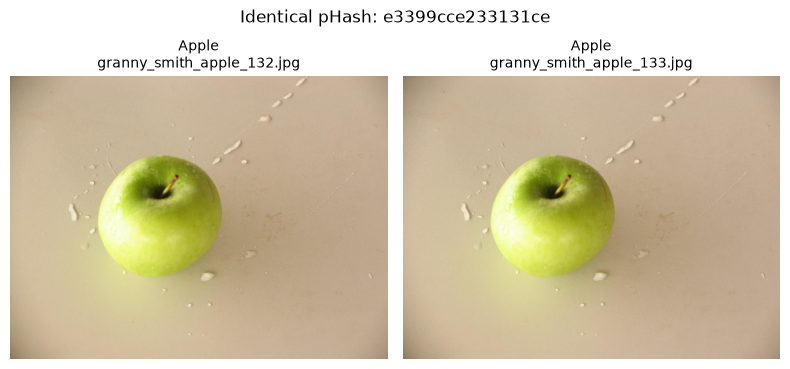

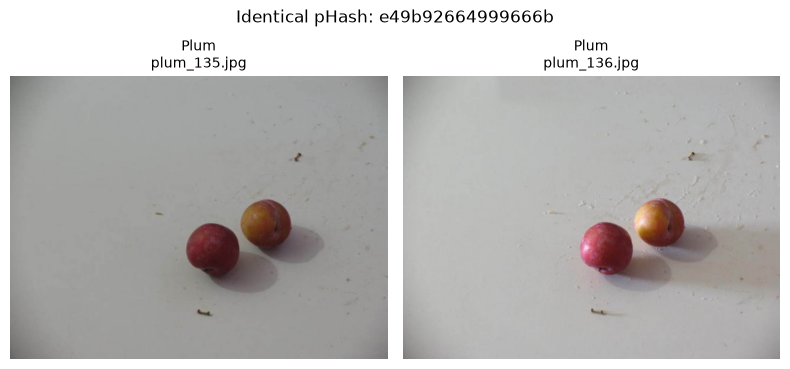

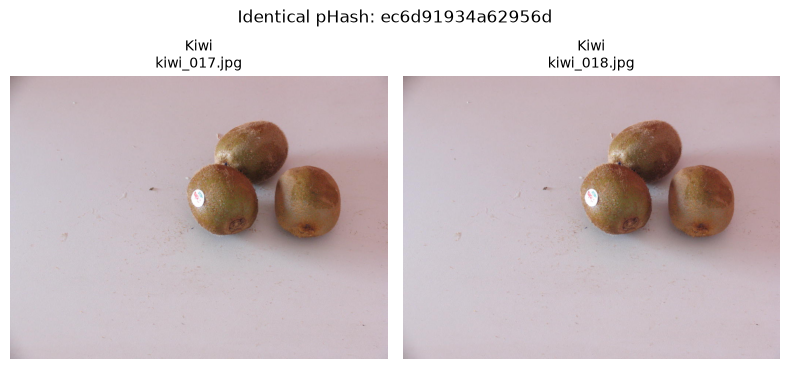

In [ ]:
# Convert perceptual hashes to strings for grouping
df["phash_string"] = df["phash"].astype(str)

# Find images with identical perceptual hashes
duplicate_phash = df[
    df.duplicated(subset="phash_string", keep=False)
].copy()

# Group images by perceptual hash
phash_groups = duplicate_phash.groupby("phash_string")

print("Number of groups with identical pHash values:", len(phash_groups))
print("Number of images involved:", len(duplicate_phash))

# Visualize each group
for phash_value, group in phash_groups:

    fig, axes = plt.subplots(
        1,
        len(group),
        figsize=(4 * len(group), 4),
        squeeze=False
    )

    for ax, (_, row) in zip(axes.flat, group.iterrows()):

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        ax.imshow(image)

        # Display the target class and filename
        class_name = row["target_class"].replace("_", " ").title()
        filename = row["image_path"].name

        ax.set_title(f"{class_name}\n{filename}", fontsize=10)
        ax.axis("off")

    plt.suptitle(f"Identical pHash: {phash_value}")
    plt.tight_layout()
    plt.show()

#### 3.11.3 Identical Perceptual Hash Groups – Findings

We found four groups with identical pHash values, involving nine images: two groups of kiwi, one of apple, and one of plum.

Visual inspection showed that images within each group were highly similar, with small differences in lighting, sharpness, or appearance. However, the earlier SHA-256 analysis confirmed that they were not exact file duplicates.

**Implications for model evaluation**

Highly similar images can cause data leakage if they appear in different dataset splits.

We therefore included these images in our near-duplicate analysis and later reserved the identified near-duplicate images for training to reduce this risk.

### 3.12 Perceptual Hash Distance Analysis

This step investigates potential near-duplicate images using the Hamming distance between perceptual hashes.

Hamming distance measures the number of differing bits between two hash values. A distance of 0 indicates identical perceptual hashes, while a low distance suggests that the images may be visually similar.

The analysis compares all possible image pairs within each target class and identifies pairs with a Hamming distance of 5 or less.

The threshold of 5 is used as an exploratory criterion for identifying potentially similar images. It does not guarantee that the images are duplicates.

The results are stored for further visualization and visual inspection, helping us investigate potential data leakage risks before splitting the dataset.

In [ ]:
from itertools import combinations

# Maximum Hamming distance
threshold = 5

# Store potentially similar image pairs
similar_pairs = []

# Compare images within each target class
for class_name, group in df.groupby("target_class"):

    # Generate all possible image pairs within the class
    for (idx1, row1), (idx2, row2) in combinations(
        group.iterrows(), 2
    ):

        # Calculate Hamming distance between pHashes
        distance = row1["phash"] - row2["phash"]

        # Keep pairs with low Hamming distance
        if distance <= threshold:

            similar_pairs.append({
                "class": class_name,
                "image_1": row1["image_path"],
                "image_2": row2["image_path"],
                "distance": distance
            })

# Convert results to DataFrame
similar_pairs_df = pd.DataFrame(
    similar_pairs,
    columns=["class", "image_1", "image_2", "distance"]
)

# Sort by similarity
similar_pairs_df = similar_pairs_df.sort_values(
    by="distance"
).reset_index(drop=True)

# Display results
print("Hamming distance threshold:", threshold)
print("Total similar image pairs:", len(similar_pairs_df))

print("\nSimilar pairs per class:")

if not similar_pairs_df.empty:
    print(similar_pairs_df["class"].value_counts().sort_index())
else:
    print("No similar image pairs found.")

Hamming distance threshold: 5
Total similar image pairs: 36

Similar pairs per class:
class
apple               7
honneydew_melon     5
kiwi               15
nectarine           4
plum                4
potato              1
Name: count, dtype: int64


#### 3.12.1 Perceptual Hash Distance Analysis – Findings

Using a Hamming distance threshold of 5, we identified 36 potentially similar image pairs, involving 58 unique images.

Kiwi had the most matching pairs (15), followed by apple (7), honeydew melon (5), nectarine (4), plum (4), and potato (1). No matching pairs were found within onion, Spanish pear, or watermelon.

The analysis included identical pHash values and only compared images within the same target class. The threshold of 5 was exploratory, so other visually similar images may have been missed.

**Implications for model evaluation**

To reduce the risk of data leakage, we later reserved all 58 identified images for the training set rather than distributing them across the dataset splits.

#### 3.12.2 Hamming Distance Distribution

We examine how the identified image pairs are distributed across Hamming distances from 0 to 5.

The results are shown in a table and bar chart. A distance of 0 means identical pHash values, while higher distances indicate greater differences between the hashes.

This helps us see how similar the potential near-duplicates are according to pHash. However, Hamming distance alone cannot confirm whether images are duplicates.

Number of image pairs by Hamming distance:



,Number of Pairs
distance,
0,6
1,0
2,14
3,0
4,16
5,0


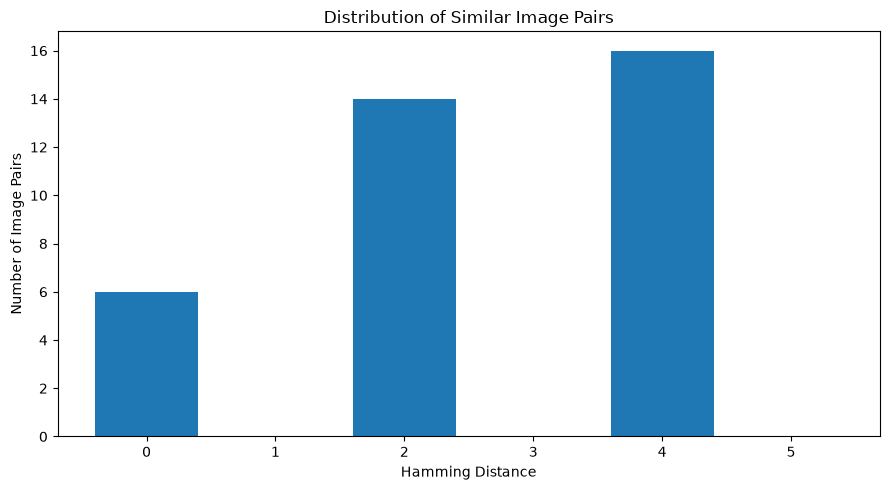

In [ ]:
# Count similar image pairs by Hamming distance
distance_counts = (
    similar_pairs_df["distance"]
    .value_counts()
    .reindex(range(threshold + 1), fill_value=0)
    .sort_index()
)

# Display table
print("Number of image pairs by Hamming distance:\n")
display(distance_counts.to_frame(name="Number of Pairs"))

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    distance_counts.index,
    distance_counts.values
)

plt.title("Distribution of Similar Image Pairs")
plt.xlabel("Hamming Distance")
plt.ylabel("Number of Image Pairs")
plt.xticks(range(threshold + 1))

plt.tight_layout()
plt.show()

#### 3.12.3 Hamming Distance Distribution – Findings

The 36 potentially similar image pairs were distributed across three Hamming distances:

- Distance 0: 6 pairs
- Distance 2: 14 pairs
- Distance 4: 16 pairs

No image pairs were identified at distances 1, 3, or 5.

The six pairs with a distance of 0 correspond to images with identical perceptual hashes, as investigated in the previous analysis.

The remaining 30 pairs have slightly different perceptual hashes but still fall within the selected similarity threshold of 5.

The results indicate that the dataset contains several image pairs with closely related perceptual fingerprints.

However, Hamming distance alone cannot determine whether the images are actual duplicates. Visual inspection is required to assess their similarity and potential implications for data leakage.

#### 3.12.4 Unique Images Involved in Potential Near-Duplicates

This step calculates how many unique images are involved in the potentially similar image pairs identified through perceptual hashing.

Since one image may appear in multiple pairs, the number of similar pairs does not directly indicate how many individual images are affected.

The code collects all image paths from the identified pairs, removes repeated paths, and calculates the percentage of the selected dataset involved.

This provides a clearer estimate of how widespread potential near-duplicates are within the dataset.

In [ ]:
# Collect all image paths involved in similar pairs
similar_images = set(similar_pairs_df["image_1"]).union(
    set(similar_pairs_df["image_2"])
)

# Count unique images
unique_similar_images = len(similar_images)

# Calculate percentage of the dataset
percentage_similar = (
    unique_similar_images / len(df)
) * 100

print("Total images in dataset:", len(df))

print("Total similar image pairs:", len(similar_pairs_df))

print("Unique images involved:", unique_similar_images)

print(f"Percentage of dataset involved: {percentage_similar:.2f}%")

Total images in dataset: 2003
Total similar image pairs: 36
Unique images involved: 58
Percentage of dataset involved: 2.90%


#### 3.12.5 Unique Images Involved in Potential Near-Duplicates – Findings

The analysis identified 58 unique images involved in the 36 potentially similar image pairs.

These images represent approximately 2.90% of the selected dataset of 2,003 images.

The difference between the number of pairs and the number of unique images confirms that some images appear in multiple similar pairs.

Although the affected proportion is relatively small, these images may still pose a risk of data leakage if highly similar examples are assigned to different training, validation, or test sets.

The results are based on a Hamming distance threshold of 5 and comparisons within the same target class. Therefore, the 58 images should be considered candidates for further inspection rather than confirmed duplicates.

No images are removed at this stage. The findings will instead inform decisions about dataset splitting and preprocessing.

### 3.13 Visual Inspection of Potential Near-Duplicates

This step visually examines image pairs identified as potentially similar through perceptual hashing.

Up to six image pairs with a Hamming distance of 2 are displayed side by side. The class names and filenames are included to make the images easier to identify.

The purpose is to investigate whether low Hamming distances correspond to visible similarities in object arrangement, background, lighting, and image composition.

This inspection provides additional evidence for assessing potential data leakage risks.

The selected pairs represent only a subset of the identified near-duplicate candidates and should not be interpreted as a complete assessment of all similar images.

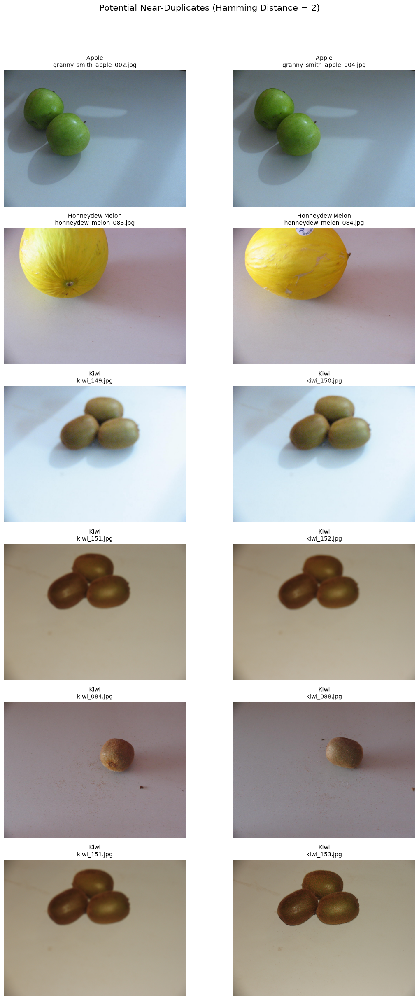

In [ ]:
# Select image pairs with Hamming distance = 2
pairs_to_inspect = similar_pairs_df[
    similar_pairs_df["distance"] == 2
]

# Display up to 6 image pairs
n_pairs = min(6, len(pairs_to_inspect))

fig, axes = plt.subplots(
    n_pairs, 2,
    figsize=(12, 4 * n_pairs),
    squeeze=False
)

for i, (_, row) in enumerate(
    pairs_to_inspect.head(n_pairs).iterrows()
):

    # Open and convert both images
    with Image.open(row["image_1"]) as img:
        img1 = img.convert("RGB")

    with Image.open(row["image_2"]) as img:
        img2 = img.convert("RGB")

    # Display images side by side
    axes[i, 0].imshow(img1)
    axes[i, 1].imshow(img2)

    # Display class names and filenames
    class_name = row["class"].replace("_", " ").title()
    filename1 = row["image_1"].name
    filename2 = row["image_2"].name

    axes[i, 0].set_title(
        f"{class_name}\n{filename1}",
        fontsize=10
    )

    axes[i, 1].set_title(
        f"{class_name}\n{filename2}",
        fontsize=10
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle(
    "Potential Near-Duplicates (Hamming Distance = 2)",
    fontsize=15,
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

#### 3.13.1 Visual Inspection of Potential Near-Duplicates – Findings

Visual inspection of six image pairs with a Hamming distance of 2 showed that several images were highly similar.

The Granny Smith apple and kiwi pairs had nearly identical backgrounds, object arrangements, and camera angles. Other pairs, including honeydew melon, showed differences in object positioning despite having the same Hamming distance.

This shows that pHash can identify both nearly identical images and images with some visual differences.

**Implications for data leakage**

Similar images appearing in different dataset splits could lead to overly optimistic model results. We therefore reserved the 58 identified potential near-duplicate images for training.

Only six of the 36 pairs were visually inspected in this step, so we cannot assume that all pairs are equally similar.

### 3.14 Investigation of Image File Naming

This step examines filename patterns in the original image dataset.

The code displays the first ten filenames from each original class folder and counts the number of image files in each folder.

The purpose is to investigate whether images follow a consistent naming convention and whether numerical filename sequences could indicate related photographs.

This analysis may help explain why some visually similar images have neighboring filenames.

However, filename patterns alone cannot establish whether images were captured consecutively or contain the same objects.

In [ ]:
# Display example filenames from each original image folder
print("Example filenames from each image folder:\n")

for folder in sorted(raw_images_path.iterdir()):

    if folder.is_dir():

        # Find image files in the current folder
        folder_image_files = sorted([
            file.name
            for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])

        # Display folder name
        print(f"\n{folder.name}")
        print("-" * 40)

        # Display the first 3 filenames
        for filename in folder_image_files[:3]:
            print(filename)

        # Display total number of images in the folder
        print(f"Total images: {len(folder_image_files)}")

Example filenames from each image folder:


agata_potato
----------------------------------------
agata_potato_001.jpg
agata_potato_002.jpg
agata_potato_003.jpg
Total images: 201

asterix_potato
----------------------------------------
asterix_potato_001.jpg
asterix_potato_002.jpg
asterix_potato_003.jpg
Total images: 182

cashew
----------------------------------------
cashew_001.jpg
cashew_002.jpg
cashew_003.jpg
Total images: 210

diamond_peach
----------------------------------------
diamond_peach_001.jpg
diamond_peach_002.jpg
diamond_peach_003.jpg
Total images: 211

fuji_apple
----------------------------------------
fuji_apple_001.jpg
fuji_apple_002.jpg
fuji_apple_003.jpg
Total images: 212

granny_smith_apple
----------------------------------------
granny_smith_apple_001.jpg
granny_smith_apple_002.jpg
granny_smith_apple_003.jpg
Total images: 155

honneydew_melon
----------------------------------------
honneydew_melon_001.jpg
honneydew_melon_002.jpg
honneydew_melon_003.jpg
Total i

#### 3.14.1 Image File Naming – Findings

The inspected filenames follow a structured naming pattern consisting of the original class name and a three-digit numerical suffix.

For example, the `agata_potato` folder contains filenames such as `agata_potato_001.jpg`, `agata_potato_002.jpg`, and `agata_potato_003.jpg`.

The numerical suffixes suggest that images are organized in numbered sequences within their original class folders.

This naming convention allows us to investigate whether images with neighboring file numbers also have similar visual characteristics.

However, filename numbering alone does not confirm that images were captured consecutively or represent the same objects.

### 3.15 Filename Patterns Among Similar Images

We investigate whether potentially similar images also have neighboring filename numbers.

The code compares the numerical parts of filenames within the same original class folder and displays the differences alongside their Hamming distances.

This helps us explore whether nearby filenames may indicate related photographs. However, consecutive filenames do not guarantee that images were taken together or show the same objects.

In [ ]:
import re

# Extract the numerical suffix from an image filename
def extract_image_number(path):
    filename = Path(path).stem

    match = re.search(r"_(\d+)$", filename)

    if match:
        return int(match.group(1))

    return None


# Create a copy of the similar image pairs
filename_analysis = similar_pairs_df.copy()

# Extract filenames
filename_analysis["filename_1"] = filename_analysis["image_1"].apply(
    lambda x: Path(x).name
)

filename_analysis["filename_2"] = filename_analysis["image_2"].apply(
    lambda x: Path(x).name
)

# Extract image numbers
filename_analysis["number_1"] = filename_analysis["image_1"].apply(
    extract_image_number
)

filename_analysis["number_2"] = filename_analysis["image_2"].apply(
    extract_image_number
)

# Check whether images belong to the same original folder
filename_analysis["same_folder"] = filename_analysis.apply(
    lambda row: Path(row["image_1"]).parent
    == Path(row["image_2"]).parent,
    axis=1
)

# Calculate numerical distance
filename_analysis["number_difference"] = (
    filename_analysis["number_1"]
    - filename_analysis["number_2"]
).abs()

# Only retain numerical differences for images in the same folder
filename_analysis.loc[
    ~filename_analysis["same_folder"],
    "number_difference"
] = pd.NA

# Display results
display(
    filename_analysis[
        [
            "class",
            "filename_1",
            "filename_2",
            "distance",
            "same_folder",
            "number_difference"
        ]
    ]
    .sort_values(by=["distance", "number_difference"])
    .reset_index(drop=True)
)

,class,filename_1,filename_2,distance,same_folder,number_difference
0,apple,granny_smith_apple_132.jpg,granny_smith_apple_133.jpg,0,True,1.0
1,kiwi,kiwi_017.jpg,kiwi_018.jpg,0,True,1.0
2,kiwi,kiwi_153.jpg,kiwi_154.jpg,0,True,1.0
3,kiwi,kiwi_152.jpg,kiwi_153.jpg,0,True,1.0
4,plum,plum_135.jpg,plum_136.jpg,0,True,1.0
5,kiwi,kiwi_152.jpg,kiwi_154.jpg,0,True,2.0
6,honneydew_melon,honneydew_melon_083.jpg,honneydew_melon_084.jpg,2,True,1.0
7,kiwi,kiwi_149.jpg,kiwi_150.jpg,2,True,1.0
8,kiwi,kiwi_151.jpg,kiwi_152.jpg,2,True,1.0
9,apple,granny_smith_apple_002.jpg,granny_smith_apple_003.jpg,2,True,1.0


#### 3.15.1 Filename Patterns Among Similar Images – Findings

All 36 potentially similar image pairs belonged to the same original class folder. Of these, 23 pairs (64%) had filename numbers that differed by 2 or less.

Some highly similar images had consecutive filenames, such as `kiwi_152.jpg` and `kiwi_153.jpg`. However, other similar pairs had much larger filename differences.

**Implications**

Neighboring filenames may help identify related photographs, but they cannot reliably confirm near-duplicates.

Since we only examined pairs already identified by pHash, we cannot conclude that neighboring filenames generally indicate visual similarity across the dataset.

### 3.16 Sequential Image Similarity Analysis

We investigate whether images with consecutive filename numbers are visually similar.

Unlike the previous analysis, this step examines all consecutive image pairs within the same original class folder, not just those already identified as potential near-duplicates.

For each pair, we calculate the pHash Hamming distance and summarize how many pairs have a distance of 5 or less.

This helps us understand whether neighboring filenames generally indicate visual similarity. However, filename order does not necessarily reflect the order in which photographs were taken.

In [ ]:
# Create a copy of the dataset
sequential_df = df.copy()

# Extract original source folder
sequential_df["source_folder"] = sequential_df["image_path"].apply(
    lambda x: Path(x).parent.name
)

# Extract image number using the function from section 3.15
sequential_df["image_number"] = sequential_df["image_path"].apply(
    extract_image_number
)

# Store consecutive image pairs
sequential_pairs = []

# Group images by original source folder
for folder_name, group in sequential_df.groupby("source_folder"):

    group = group.dropna(
        subset=["image_number", "phash"]
    ).sort_values("image_number")

    records = group.to_dict("records")

    for i in range(len(records) - 1):

        img1 = records[i]
        img2 = records[i + 1]

        # Only compare consecutive file numbers
        if img2["image_number"] - img1["image_number"] == 1:

            distance = img1["phash"] - img2["phash"]

            sequential_pairs.append({
                "source_folder": folder_name,
                "image_1": Path(img1["image_path"]).name,
                "image_2": Path(img2["image_path"]).name,
                "distance": distance
            })

# Convert results into a DataFrame
sequential_pairs_df = pd.DataFrame(
    sequential_pairs,
    columns=[
        "source_folder",
        "image_1",
        "image_2",
        "distance"
    ]
)

print("Total consecutive image pairs:", len(sequential_pairs_df))

print("\nHamming distance statistics:")
print(sequential_pairs_df["distance"].describe())

print("\nConsecutive pairs with Hamming distance <= 5:")
print((sequential_pairs_df["distance"] <= 5).sum())

Total consecutive image pairs: 1992

Hamming distance statistics:
count    1992.000000
mean       25.332329
std         6.849608
min         0.000000
25%        22.000000
50%        26.000000
75%        30.000000
max        42.000000
Name: distance, dtype: float64

Consecutive pairs with Hamming distance <= 5:
18


#### 3.16.1 Sequential Image Similarity Analysis – Findings

We identified 1,992 image pairs with consecutive filename numbers.

The average Hamming distance was 25.33 (median: 26), and only 18 pairs (0.9%) had a distance of 5 or less.

This shows that most images with neighboring filenames do not have highly similar pHash values, although a few pairs may represent closely related photographs.

**Implications for dataset preparation**

Filename proximity alone is not a reliable way to detect near-duplicates. Perceptual hashing is more useful for identifying potential matches.

However, this analysis only examined consecutive filenames, and filename order does not necessarily reflect the actual photography sequence.

### 3.17 Background Color Analysis

We investigate whether background colors differ between the nine target classes.

For each image, we estimate the background color by calculating the average RGB values from four 50 × 50 pixel corner regions. We then compare the average values across classes.

The purpose is to explore whether background colors could become shortcuts for the model, causing it to learn background patterns instead of recognizing the objects.

**Limitations**

The corners may also contain parts of the objects or shadows, so the results are only estimates of background color.

Differences between classes do not necessarily mean that a model will rely on these patterns.

In [ ]:
# Function to estimate background color from image corners
def estimate_background_color(image_path, corner_size=50):

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        image = np.array(img)

    height, width, _ = image.shape

    # Extract four corner regions
    corners = [
        image[:corner_size, :corner_size],
        image[:corner_size, width-corner_size:],
        image[height-corner_size:, :corner_size],
        image[height-corner_size:, width-corner_size:]
    ]

    # Combine all corner pixels
    corner_pixels = np.concatenate(
        [corner.reshape(-1, 3) for corner in corners],
        axis=0
    )

    # Calculate average RGB values
    mean_rgb = corner_pixels.mean(axis=0)

    return mean_rgb


# Calculate background colors for all images
background_results = []

for _, row in df.iterrows():

    image_path = row["image_path"]

    mean_rgb = estimate_background_color(image_path)

    background_results.append({
        "target_class": row["target_class"],
        "red": mean_rgb[0],
        "green": mean_rgb[1],
        "blue": mean_rgb[2]
    })


# Convert results into a DataFrame
background_df = pd.DataFrame(background_results)

# Calculate average RGB values per class
background_summary = (
    background_df
    .groupby("target_class")[["red", "green", "blue"]]
    .mean()
    .round(2)
)

print("Average estimated background RGB values per class:\n")

display(background_summary)

Average estimated background RGB values per class:



,red,green,blue
target_class,,,
apple,150.94,151.69,149.73
honneydew_melon,139.53,133.76,141.15
kiwi,147.34,143.31,146.96
nectarine,180.82,162.91,171.20
onion,146.56,116.56,88.43
plum,122.17,123.27,121.85
potato,119.90,99.66,77.18
spanish_pear,108.20,110.19,108.70
watermelon,150.61,134.20,111.47


#### 3.17.1 Background Color Analysis – Findings

The estimated background colors differed between the nine classes.

Nectarine had relatively light corner regions, while potato and onion showed warmer tones with lower blue-channel values. Spanish pear had darker, more balanced RGB values.

**Implications for model training**

These differences suggest that background colors could act as shortcuts, allowing models to associate certain backgrounds with specific classes instead of recognizing the objects.

However, this analysis does not show whether a trained model actually uses background information. The values are also class averages, so they do not capture variation between individual images.

#### 3.17.2 Visualization of Average Estimated Background Colors

This step visualizes the average estimated background color for each of the nine target classes.

The previously calculated mean RGB values are converted into color patches, allowing the estimated corner colors to be compared visually.

The purpose is to make differences in the average color characteristics of image corners easier to interpret than through numerical values alone.

Each color patch represents the class average rather than the background of an individual image.

**Limitation:** The visualization does not show variation within classes, and the estimated colors may be influenced by objects or shadows appearing in the image corners.

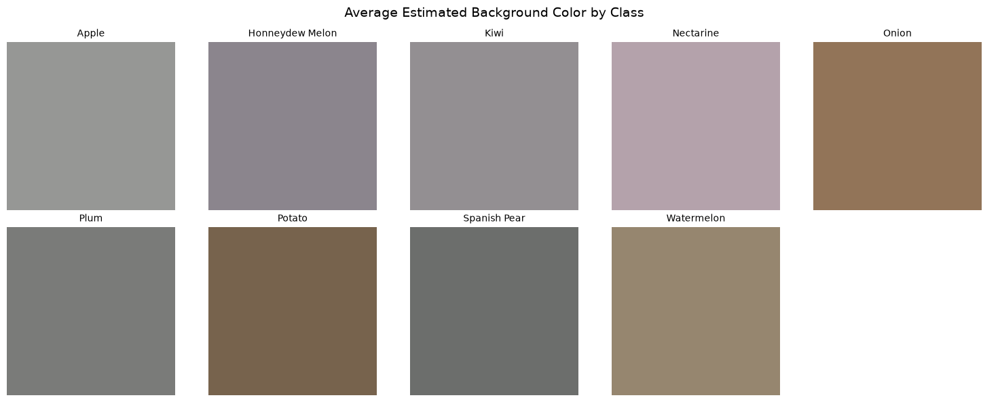

In [ ]:
# Create a grid for the nine target classes
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Display the average estimated corner color for each class
for ax, (class_name, row) in zip(
    axes.flat,
    background_summary.iterrows()
):

    # Convert RGB values from 0–255 to 0–1
    rgb = row[["red", "green", "blue"]].to_numpy(dtype=float) / 255

    # Create a solid color patch
    color_patch = np.ones((100, 100, 3)) * rgb

    ax.imshow(color_patch)
    ax.set_title(class_name.replace("_", " ").title(), fontsize=10)
    ax.axis("off")

# Hide the unused subplot
for ax in axes.flat[len(background_summary):]:
    ax.axis("off")

plt.suptitle(
    "Average Estimated Background Color by Class",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### 3.17.3 Background Color Visualization – Findings

The visualization shows differences in average corner colors between classes.

Nectarine has a light pinkish tone, potato and onion have warmer brown tones, while apple, kiwi, and plum appear more grayish. Watermelon has a muted beige-brown tone.

These patterns suggest that background colors may be associated with certain classes, potentially creating shortcuts for classification.

However, the visualization only shows class averages, not variation between individual images. It also cannot confirm whether a trained model relies on background colors.

#### 3.17.4 Background Color Variation Within Classes

We examine how much the estimated corner colors vary between images within each class.

The code calculates the standard deviation of the red, green, and blue (RGB) values for each class.

A low standard deviation means the corner colors are relatively similar, while a high value indicates greater variation.

This helps us understand whether the class averages hide differences between individual images.

**Limitation:** Corner regions may also contain objects or shadows, so they do not always represent the background accurately.

In [ ]:
# Calculate standard deviation of estimated corner RGB values
background_std = (
    background_df
    .groupby("target_class")[["red", "green", "blue"]]
    .std()
    .round(2)
)

print("Standard deviation of estimated corner RGB values per class:\n")

display(background_std)

Standard deviation of estimated corner RGB values per class:



,red,green,blue
target_class,,,
apple,39.28,33.29,30.65
honneydew_melon,30.35,25.44,31.96
kiwi,47.14,38.25,38.71
nectarine,28.57,26.42,24.19
onion,17.67,14.18,11.35
plum,23.77,24.31,23.86
potato,31.79,30.86,29.28
spanish_pear,37.27,37.31,39.15
watermelon,18.01,19.18,22.69


#### 3.17.5 Background Color Variation – Findings

The estimated corner colors varied differently across the nine classes.

Kiwi and Spanish pear showed relatively high variation in RGB values, while onion had the lowest variation. Watermelon also showed relatively consistent corner colors.

This means that some classes have more consistent background characteristics than others. The average colors shown earlier therefore do not tell the whole story.

**Implications**

Classes with consistent corner colors may provide background-related clues to a classification model. However, variation in corner colors does not prove that a model uses these features, and the measurements may include objects or shadows.

### 3.18 Fruit and Vegetable Color Analysis

#### 3.18.1 Reproducible Image Sampling

Five images were randomly selected from each of the nine classes (45 images in total) using `random_state=42` for reproducibility.

The sample was used to explore color variation through manually selected object regions (ROIs).

**Limitation:** Five images per class may not represent the full dataset. The ROI annotations are saved in `data/fruit_color_rois.csv`.

#### Development of the Object Color Extraction Method

To explore object colors without including obvious background pixels, we tested automatic background removal using RGB color distances and OpenCV's GrabCut algorithm. However, shadows, lighting differences, and similar object and background colors made these methods unreliable for isolating object colors.

We therefore used `cv2.selectROI()` to manually select one rectangular region per image. The 45 ROIs (five per class) were validated and saved with relative image paths in `data/fruit_color_rois.csv`.

From these regions, we calculated mean RGB values, visualized red–green color overlap, and compared normalized RGB histograms.

**Limitation:** Manual ROIs do not capture every color of an object, and the small sample may not represent the full dataset. These results are exploratory and should not be interpreted as complete color distributions for all 2,003 images.

In [ ]:
# Select five reproducible random images per fruit class
color_sample_df = (
    df.groupby("target_class", group_keys=False)
    .sample(n=5, random_state=42)
    .sort_values("target_class")
    .reset_index(drop=True)
)

print("Number of selected images:", len(color_sample_df))

display(
    color_sample_df["target_class"]
    .value_counts()
    .sort_index()
)

Number of selected images: 45


target_class
apple              5
honneydew_melon    5
kiwi               5
nectarine          5
onion              5
plum               5
potato             5
spanish_pear       5
watermelon         5
Name: count, dtype: int64

#### 3.18.2 Visual Inspection of Color Variation

We display five sampled images per class to visually compare object colors, lighting, and backgrounds.

This provides an overview of color variation before examining object colors using manually selected ROIs.

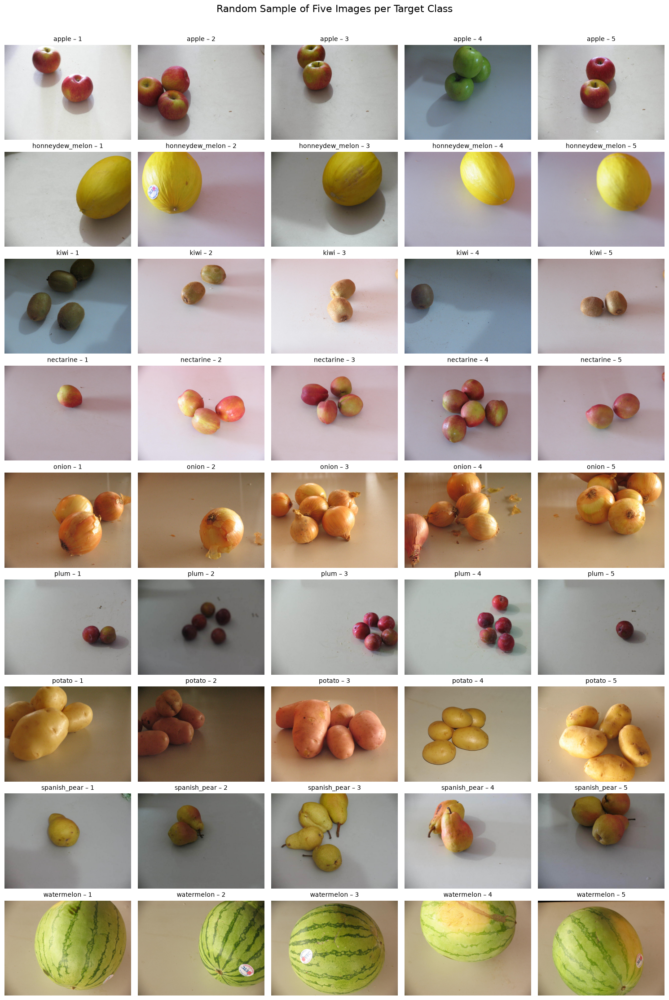

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(9, 5, figsize=(15, 22))

for row_index, (class_name, group) in enumerate(
    color_sample_df.groupby("target_class", sort=True)
):
    for col_index, (_, row) in enumerate(group.iterrows()):

        with Image.open(row["image_path"]) as img:
            axes[row_index, col_index].imshow(img.convert("RGB"))

        axes[row_index, col_index].set_title(
            f"{class_name} – {col_index + 1}",
            fontsize=10
        )
        axes[row_index, col_index].axis("off")

fig.suptitle(
    "Random Sample of Five Images per Target Class",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

#### 3.18.3 Visual Inspection Findings

The sampled images show color variation within classes and overlapping colors between classes, particularly among apples, nectarines, and plums.

These observations suggest that color may help classification but is unlikely to distinguish all nine classes on its own. Shape and texture may provide additional information.

Lighting, shadows, and backgrounds also affect color appearance, motivating the following ROI analysis.

**Limitation:** The observations are based on five images per class and may not represent the full dataset.

#### 3.18.4 Manual Region of Interest (ROI) Selection

Using `cv2.selectROI()`, we manually selected one rectangular ROI per sampled image (45 in total).

The image paths, class labels, and ROI coordinates were saved in `data/fruit_color_rois.csv`. Relative paths allow the annotations to be reused across computers.

The notebook loads these saved coordinates, avoiding the need to repeat the manual selection.

#### 3.18.5 Loading and Validating Saved ROI Annotations

We load `data/fruit_color_rois.csv` and confirm that all 45 ROIs have unique image paths, positive dimensions, and five annotations per class.

**Limitation:** These initial checks do not verify image file existence, ROI boundaries, or whether the selected regions contain only object pixels.

In [ ]:
from pathlib import Path

roi_file = project_root / "data" / "fruit_color_rois.csv"

roi_df = pd.read_csv(roi_file)

print(f"Total number of ROIs: {len(roi_df)}")
print(f"Unique images: {roi_df['image_path'].nunique()}")

print("\nROIs per class:")
display(roi_df["target_class"].value_counts().sort_index())

print("\nInvalid regions:")
display(roi_df[(roi_df["width"] <= 0) | (roi_df["height"] <= 0)])

Total number of ROIs: 45
Unique images: 45

ROIs per class:


target_class
apple              5
honneydew_melon    5
kiwi               5
nectarine          5
onion              5
plum               5
potato             5
spanish_pear       5
watermelon         5
Name: count, dtype: int64


Invalid regions:


,image_path,target_class,x,y,width,height


#### 3.18.6 Calculating Mean RGB Values from Selected ROIs

Using the saved ROI coordinates, we calculate the mean red, green, and blue values (0–255) for each of the 45 selected regions.

The results are stored in `fruit_color_df` for comparing color differences between classes.

**Limitation:** Mean RGB values do not capture complete color distributions or textures and may be affected by lighting and ROI selection.

In [ ]:
from PIL import Image

color_records = []

for _, row in roi_df.iterrows():
    image_path = project_root / row["image_path"]

    with Image.open(image_path) as img:
        image_rgb = np.asarray(img.convert("RGB"))

    x = int(row["x"])
    y = int(row["y"])
    w = int(row["width"])
    h = int(row["height"])

    image_height, image_width = image_rgb.shape[:2]

    # Verify that the ROI is inside the image boundaries
    if not (
        0 <= x < image_width
        and 0 <= y < image_height
        and w > 0
        and h > 0
        and x + w <= image_width
        and y + h <= image_height
    ):
        raise ValueError(f"Invalid ROI coordinates for {image_path}")

    # Extract the selected region
    fruit_region = image_rgb[y:y+h, x:x+w]

    # Calculate mean RGB values
    mean_rgb = fruit_region.mean(axis=(0, 1))

    color_records.append({
        "image_path": row["image_path"],
        "target_class": row["target_class"],
        "mean_red": mean_rgb[0],
        "mean_green": mean_rgb[1],
        "mean_blue": mean_rgb[2]
    })

fruit_color_df = pd.DataFrame(color_records)

display(fruit_color_df.head())

,image_path,target_class,mean_red,mean_green,mean_blue
0,data/raw_images/fuji_apple/fuji_apple_194.jpg,apple,150.029491,61.404175,47.789690
1,data/raw_images/fuji_apple/fuji_apple_034.jpg,apple,103.924461,50.346228,33.325000
2,data/raw_images/fuji_apple/fuji_apple_016.jpg,apple,105.566871,73.187378,23.944971
3,data/raw_images/granny_smith_apple/granny_smit...,apple,80.068980,108.726495,43.436159
4,data/raw_images/fuji_apple/fuji_apple_058.jpg,apple,113.978528,48.132079,39.570788


#### 3.18.7 Mean RGB Calculation Findings

Mean RGB values were calculated for all 45 ROIs, with all regions passing the image-boundary checks.

The apple class illustrates within-class variation: one ROI was predominantly red (150, 61, 48), while another had a stronger green component (80, 109, 43).

These results show that objects within the same class can have different color characteristics.

**Limitation:** The measurements are based on a small sample and do not capture complete object color distributions.

#### 3.18.8 Comparison of Mean RGB Values Across Classes

We calculate mean RGB values for each class using five manually selected ROIs and visualize the results in a grouped bar chart.

This allows us to explore color differences and similarities between classes.

**Limitation:** Class averages may hide within-class variation, and the small sample may not represent the full dataset.

,mean_red,mean_green,mean_blue
target_class,,,
apple,110.71,68.36,37.61
honneydew_melon,175.28,155.19,49.50
kiwi,123.26,101.87,73.22
nectarine,172.87,108.18,74.39
onion,177.44,107.19,54.35
plum,89.22,38.81,39.02
potato,168.30,116.87,61.63
spanish_pear,131.47,94.19,36.16
watermelon,152.42,156.90,67.16


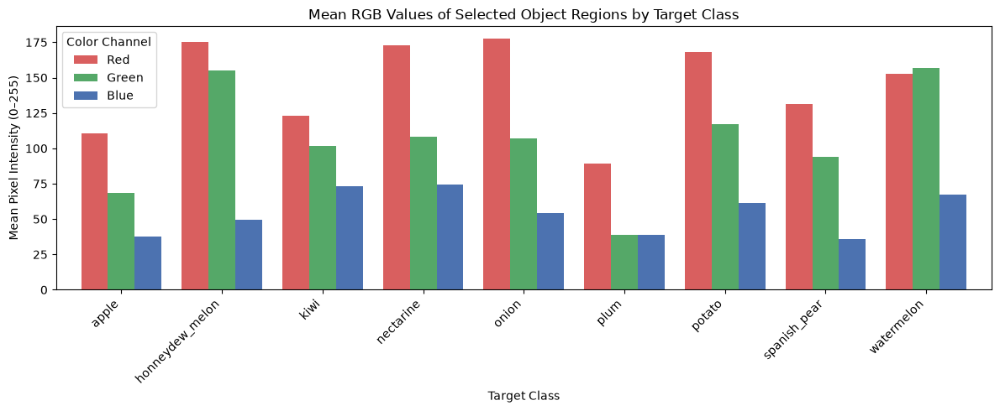

In [ ]:
import matplotlib.pyplot as plt

class_rgb = (
    fruit_color_df
    .groupby("target_class")[["mean_red", "mean_green", "mean_blue"]]
    .mean()
    .sort_index()
)

display(class_rgb.round(2))

ax = class_rgb.plot(
    kind="bar",
    figsize=(12, 5),
    color=["#D95F5F", "#55A868", "#4C72B0"],
    width=0.8
)

ax.set_title("Mean RGB Values of Selected Object Regions by Target Class")
ax.set_xlabel("Target Class")
ax.set_ylabel("Mean Pixel Intensity (0–255)")
ax.legend(["Red", "Green", "Blue"], title="Color Channel")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 3.18.9 Class-Level RGB Comparison Findings

The class-level RGB averages show both color differences and similarities. Honeydew melon has relatively high red and green values, while plum has a darker color profile.

Nectarine and onion have similar mean red (172.87 and 177.44) and green (108.18 and 107.19) values, illustrating color overlap between different classes.

These findings suggest that color can support classification but may not be sufficient on its own. Additional visual features, such as shape and texture, may help distinguish classes.

**Limitation:** The results are based on five ROIs per class, and class averages may hide individual variation.

#### 3.18.10 Red vs Green Intensity Analysis

We visualize mean red and green intensities for all 45 ROIs in a scatter plot, with points colored by class.

Unlike class-level averages, this plot highlights within-class color variation and overlap between classes.

**Limitation:** The plot excludes blue intensities and is based on a small exploratory sample.

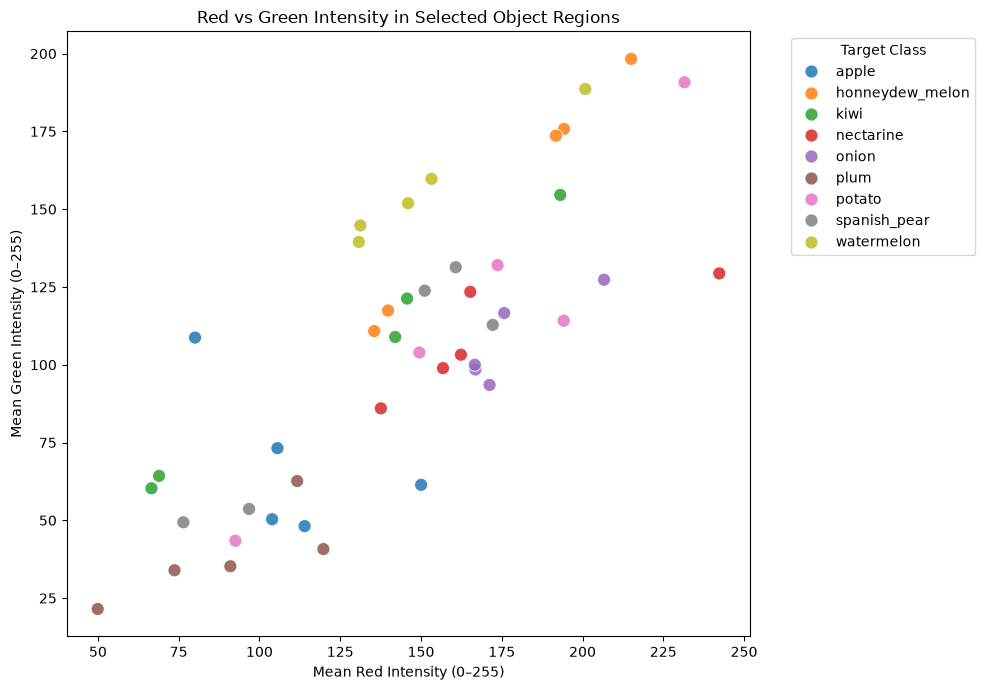

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=fruit_color_df,
    x="mean_red",
    y="mean_green",
    hue="target_class",
    s=90,
    alpha=0.85
)

plt.title("Red vs Green Intensity in Selected Object Regions")
plt.xlabel("Mean Red Intensity (0–255)")
plt.ylabel("Mean Green Intensity (0–255)")
plt.legend(
    title="Target Class",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#### 3.18.11 Red vs Green Intensity Findings

The scatter plot shows substantial within-class color variation, particularly for apples, and overlap between several classes, including nectarine, onion, and potato.

Some watermelon ROIs form a relatively distinct group with higher green intensities, while plum ROIs generally have lower red and green values.

Overall, the classes are not clearly separated by mean red and green intensities alone, suggesting that additional visual features may be useful for classification.

#### 3.18.12 RGB Intensity Distribution Analysis

We calculate normalized RGB histograms with 32 bins per channel for each of the 45 manually selected ROIs.

The histograms are averaged across five images per class and displayed in a 3 × 3 grid to compare color distributions across the nine classes.

Unlike mean RGB values, histograms capture the distribution of color intensities rather than a single average.

**Limitation:** The small ROI sample and class-level averaging may hide individual variation. Histograms also do not preserve spatial information.

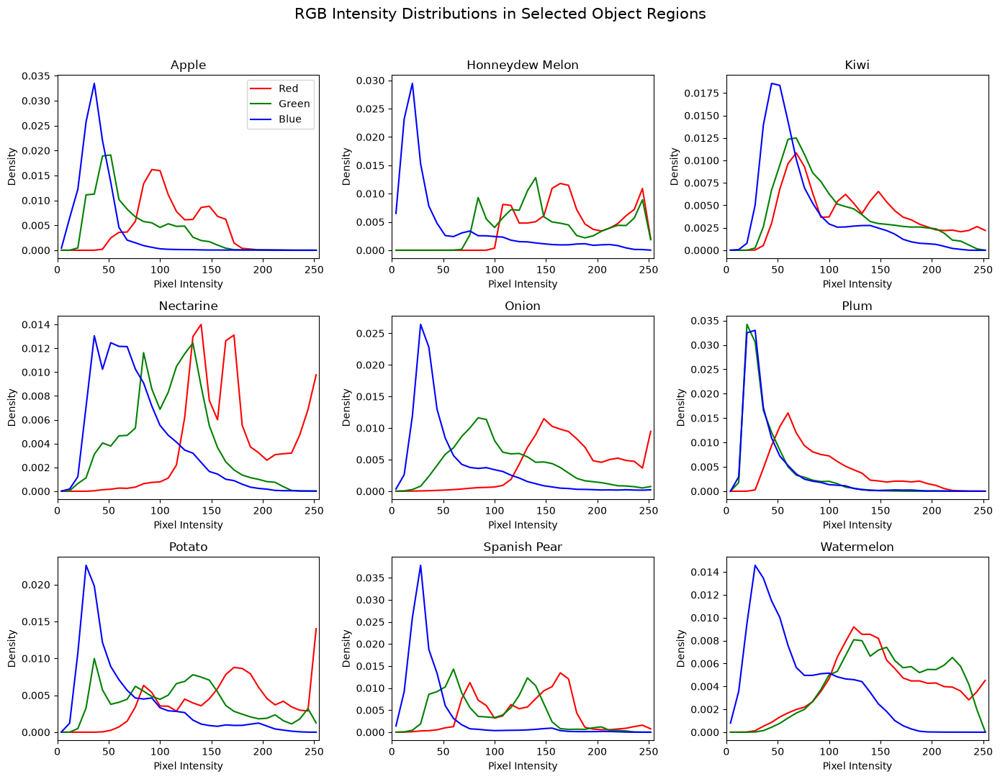

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))

channels = ["Red", "Green", "Blue"]
colors = ["red", "green", "blue"]

# Create 32 equally spaced intensity bins
bins = np.linspace(0, 256, 33)
bin_centers = (bins[:-1] + bins[1:]) / 2

for ax, (class_name, group) in zip(
    axes.flat,
    roi_df.groupby("target_class", sort=True)
):
    histograms = []

    for _, row in group.iterrows():
        image_path = project_root / row["image_path"]

        with Image.open(image_path) as img:
            image = np.asarray(img.convert("RGB"))

        x, y = int(row["x"]), int(row["y"])
        w, h = int(row["width"]), int(row["height"])

        # Extract the manually selected ROI
        region = image[y:y+h, x:x+w]

        # Calculate normalized histograms for each RGB channel
        image_histograms = [
            np.histogram(
                region[:, :, channel],
                bins=bins,
                density=True
            )[0]
            for channel in range(3)
        ]

        histograms.append(image_histograms)

    # Average the five ROI histograms for each class
    mean_histograms = np.mean(histograms, axis=0)

    for channel, color, label in zip(range(3), colors, channels):
        ax.plot(
            bin_centers,
            mean_histograms[channel],
            color=color,
            label=label
        )

    ax.set_title(class_name.replace("_", " ").title())
    ax.set_xlim(0, 255)
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Density")

axes[0, 0].legend()

fig.suptitle(
    "RGB Intensity Distributions in Selected Object Regions",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### 3.18.13 RGB Intensity Distribution Findings

The RGB histograms reveal differences that are not visible in mean RGB values. Apples show a broad red intensity distribution, while honeydew melons generally have higher red and green intensities than blue.

Several classes still have overlapping color distributions, suggesting that RGB histograms may be useful for classification but cannot guarantee clear separation between classes.

**Limitation:** Each class histogram averages only five ROIs. Multiple peaks may reflect variation between images rather than different colors within a single object.

#### 3.18.14 Background Color Masking and RGB Histogram Comparison

The previous color analysis used manually selected ROIs, which are not practical for automated feature extraction.

Here, we test a simpler background masking method. We estimate the background color from the image corners and replace pixels with similar colors using a common value.

We then compare images and RGB histograms before and after masking to explore whether this reduces background influence while preserving useful object colors.

**Objectives**
- Estimate and mask background colors using image corners.
- Compare original and masked images and their RGB histograms.
- Explore whether masking could be useful for automated feature extraction.

This is an exploratory experiment. No models are trained or evaluated in this step.

##### Step 1 – Estimating Background Color from Image Corners

We estimate the background color using the median RGB values from small regions in the four image corners, assuming these mostly contain background pixels.

**Limitation:** Objects extending into the corners may affect the background estimate.

In [ ]:
def estimate_background_color(image_path, corner_fraction=0.10):
    image = np.array(Image.open(image_path).convert("RGB"))

    height, width, _ = image.shape

    corner_height = max(1, int(height * corner_fraction))
    corner_width = max(1, int(width * corner_fraction))

    corners = [
        image[:corner_height, :corner_width],
        image[:corner_height, -corner_width:],
        image[-corner_height:, :corner_width],
        image[-corner_height:, -corner_width:]
    ]

    corner_pixels = np.concatenate(
        [corner.reshape(-1, 3) for corner in corners],
        axis=0
    )

    background_color = np.median(corner_pixels, axis=0)

    return background_color.astype(np.uint8)


# Select one reproducible sample image
sample_image_path = df.iloc[0]["image_path"]

estimated_background = estimate_background_color(sample_image_path)

print("Sample image:", sample_image_path)
print("Estimated background RGB:", estimated_background)

Sample image: c:\Users\JRD\GroupProjectGrupp1BI25\group-project\data\raw_images\agata_potato\agata_potato_001.jpg
Estimated background RGB: [158 152 134]


##### Step 2 – Visual Inspection of the Estimated Background Color

We compare the original image with a solid color patch representing the estimated background RGB value to visually assess whether the estimate is reasonable before masking.

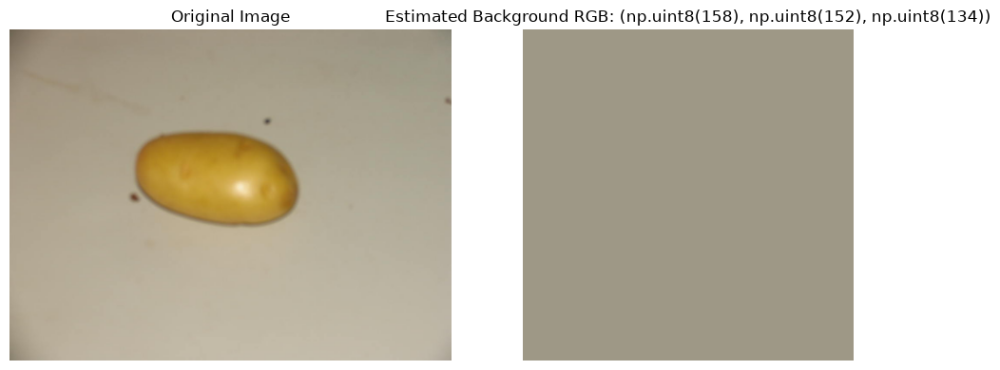

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sample_image = Image.open(sample_image_path).convert("RGB")

axes[0].imshow(sample_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

color_patch = np.full(
    (100, 100, 3),
    estimated_background,
    dtype=np.uint8
)

axes[1].imshow(color_patch)
axes[1].set_title(f"Estimated Background RGB: {tuple(estimated_background)}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

##### Step 3 – Background Color Masking

We calculate the Euclidean RGB distance between each pixel and the estimated background color. Pixels within a chosen threshold are treated as background and replaced with black (RGB 0, 0, 0).

We initially test a threshold of 40 and visually inspect whether background pixels are reduced without removing too much of the object.

Unlike object segmentation methods such as GrabCut, this approach does not identify exact object boundaries. Its purpose is to reduce background influence on RGB histogram features.

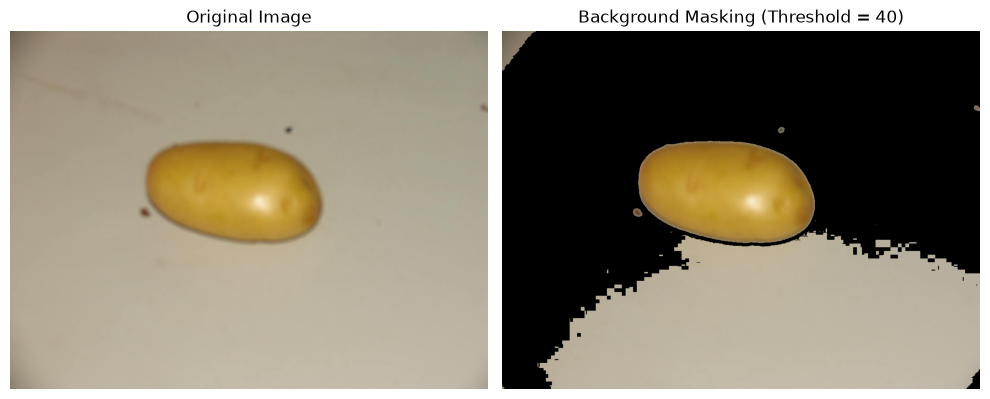

Pixels masked: 59.4%


In [ ]:
def mask_background(image_path, background_color, threshold=40):
    image = np.array(Image.open(image_path).convert("RGB"))

    # Convert to float to avoid uint8 arithmetic issues
    image_float = image.astype(np.float32)
    background_float = background_color.astype(np.float32)

    # Calculate RGB color distance for every pixel
    color_distance = np.linalg.norm(
        image_float - background_float,
        axis=2
    )

    # Identify pixels similar to the estimated background
    background_mask = color_distance <= threshold

    # Replace background-like pixels with black
    masked_image = image.copy()
    masked_image[background_mask] = [0, 0, 0]

    return masked_image, background_mask


masked_image, background_mask = mask_background(
    sample_image_path,
    estimated_background,
    threshold=40
)

masked_percentage = background_mask.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(masked_image)
axes[1].set_title("Background Masking (Threshold = 40)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Pixels masked: {masked_percentage:.1f}%")

##### Step 4 – Comparing Background Masking Thresholds

The initial masking reduced much of the potato's background, although some lighter areas remained.

We compare different RGB distance thresholds to examine the trade-off between retaining background pixels and accidentally removing object pixels.

This visual comparison explores threshold sensitivity rather than identifying an optimal threshold for the full dataset.

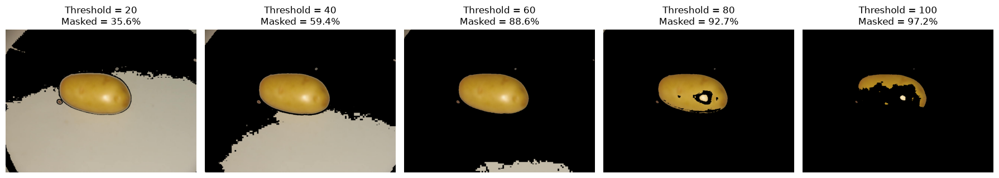

In [ ]:
thresholds = [20, 40, 60, 80, 100]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, threshold in zip(axes, thresholds):
    masked, mask = mask_background(
        sample_image_path,
        estimated_background,
        threshold=threshold
    )

    masked_percentage = mask.mean() * 100

    ax.imshow(masked)
    ax.set_title(
        f"Threshold = {threshold}\n"
        f"Masked = {masked_percentage:.1f}%"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

##### Step 5 – Background Masking Across Fruit and Vegetable Classes

We apply background masking with a fixed RGB distance threshold of 60 to one reproducibly selected image from each of the nine classes.

The background color is estimated separately for each image. We compare original and masked images side by side and report the percentage of masked pixels.

**Limitation:** This visual comparison is based on one image per class and does not establish the optimal threshold or measure classification performance.

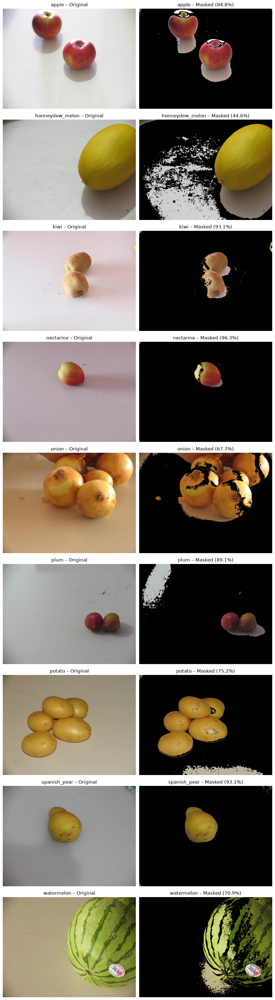

In [ ]:
# Select one reproducible image per target class
class_samples = (
    df.groupby("target_class", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("target_class")
)

threshold = 65

fig, axes = plt.subplots(
    len(class_samples), 2,
    figsize=(10, 4 * len(class_samples))
)

for i, (_, row) in enumerate(class_samples.iterrows()):
    image_path = row["image_path"]
    class_name = row["target_class"]

    original_image = np.array(
        Image.open(image_path).convert("RGB")
    )

    background_color = estimate_background_color(image_path)

    masked_image, background_mask = mask_background(
        image_path,
        background_color,
        threshold=threshold
    )

    masked_percentage = background_mask.mean() * 100

    axes[i, 0].imshow(original_image)
    axes[i, 0].set_title(f"{class_name} – Original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masked_image)
    axes[i, 1].set_title(
        f"{class_name} – Masked ({masked_percentage:.1f}%)"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

##### Step 6 – Comparing RGB Histograms Before and After Background Masking

We compare normalized RGB histograms from one reproducibly selected image per class using three approaches: original images, background masking with threshold 65, and background masking with threshold 80.

Each RGB channel uses 32 bins and is normalized separately. Masked pixels are excluded from the histograms rather than counted as black pixels.

This comparison illustrates how background masking changes color distributions. Its effect on classification performance is evaluated separately during modeling.

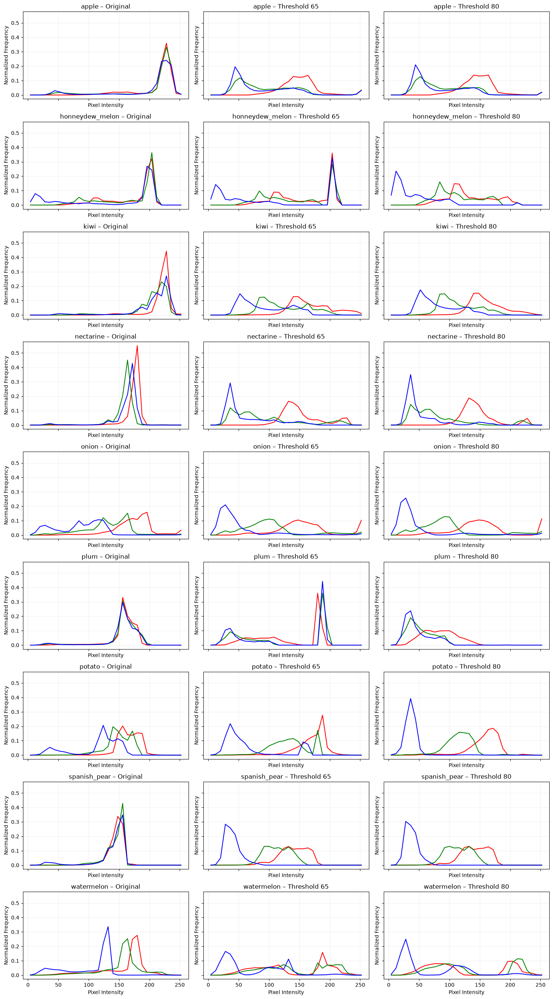

In [ ]:
def calculate_rgb_histograms(image, valid_mask=None, bins=32):
    if valid_mask is None:
        pixels = image.reshape(-1, 3)
    else:
        pixels = image[valid_mask]

    if len(pixels) == 0:
        return None

    histograms = []

    for channel in range(3):
        histogram, _ = np.histogram(
            pixels[:, channel],
            bins=bins,
            range=(0, 256)
        )

        histogram = histogram / histogram.sum()
        histograms.append(histogram)

    return np.array(histograms)


thresholds = [65, 80]
colors = ["red", "green", "blue"]
bin_centers = np.linspace(4, 252, 32)

fig, axes = plt.subplots(
    len(class_samples), 3,
    figsize=(15, 3 * len(class_samples)),
    sharex=True,
    sharey=True
)

for i, (_, row) in enumerate(class_samples.iterrows()):
    image_path = row["image_path"]
    class_name = row["target_class"]

    original_image = np.array(
        Image.open(image_path).convert("RGB")
    )

    background_color = estimate_background_color(image_path)

    # Original histogram: all pixels
    original_hist = calculate_rgb_histograms(original_image)

    for channel, color in enumerate(colors):
        axes[i, 0].plot(
            bin_centers,
            original_hist[channel],
            color=color
        )

    axes[i, 0].set_title(f"{class_name} – Original")

    # Masked histograms: exclude background-like pixels
    for j, threshold in enumerate(thresholds, start=1):
        _, background_mask = mask_background(
            image_path,
            background_color,
            threshold=threshold
        )

        valid_mask = ~background_mask

        masked_hist = calculate_rgb_histograms(
            original_image,
            valid_mask=valid_mask
        )

        if masked_hist is not None:
            for channel, color in enumerate(colors):
                axes[i, j].plot(
                    bin_centers,
                    masked_hist[channel],
                    color=color
                )

        axes[i, j].set_title(
            f"{class_name} – Threshold {threshold}"
        )

    for ax in axes[i]:
        ax.set_xlabel("Pixel Intensity")
        ax.set_ylabel("Normalized Frequency")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

##### RGB Histogram Comparison – Findings

Background masking reduced some background-related peaks in the RGB histograms, making other color intensities more visible.

The effects varied between classes. Apple, kiwi, and nectarine showed clearer color distributions after masking, while potato and watermelon illustrated the risk of removing useful object colors at higher thresholds.

These observations suggest that background masking may reduce background influence, but its effectiveness depends on the image and threshold.

**Limitation:** Only one image per class was examined. Thresholds 65 and 80 remain experimental candidates, and their effect on classification performance must be evaluated separately.

##### Step 7 – Evaluating Background Masking Across Multiple Images

We evaluate background masking at thresholds 65 and 80 on 45 reproducibly selected images (five per class).

For each image, we estimate the background color from its corners and calculate the percentage of masked pixels to compare variation across classes and thresholds.

**Limitation:** The masked pixel percentage measures how much of an image is removed, not whether the removed pixels are actually background.

In [ ]:
# Select five reproducible images per class
multi_class_samples = (
    df.groupby("target_class", group_keys=False)
    .sample(n=5, random_state=42)
    .sort_values(["target_class", "image_path"])
)

masking_results = []

for _, row in multi_class_samples.iterrows():
    image_path = row["image_path"]
    class_name = row["target_class"]

    background_color = estimate_background_color(image_path)

    for threshold in [65, 80]:
        _, background_mask = mask_background(
            image_path,
            background_color,
            threshold=threshold
        )

        masking_results.append({
            "target_class": class_name,
            "image_path": str(image_path),
            "threshold": threshold,
            "masked_percentage": background_mask.mean() * 100
        })

masking_results_df = pd.DataFrame(masking_results)

masking_summary = (
    masking_results_df
    .groupby(["target_class", "threshold"])["masked_percentage"]
    .agg(["mean", "min", "max", "std"])
    .round(1)
)

print(f"Images evaluated: {len(multi_class_samples)}")
print(f"Masking results: {len(masking_results_df)}")

display(masking_summary)

Images evaluated: 45
Masking results: 90


mean   min   max   std
target_class    threshold                        
apple           65         66.0  30.6  85.6  24.9
                80         75.0  49.3  89.1  17.6
honneydew_melon 65         64.8  44.6  79.6  17.0
                80         70.6  52.5  80.4  11.4
kiwi            65         79.1  54.0  93.4  19.4
                80         84.5  64.8  94.3  13.5
nectarine       65         88.1  81.6  96.3   5.7
                80         89.1  83.1  96.9   5.5
onion           65         72.6  63.3  85.2   9.1
                80         84.9  73.6  93.9   8.9
plum            65         89.9  88.8  91.8   1.4
                80         92.6  89.7  97.1   3.2
potato          65         76.3  54.0  98.3  16.2
                80         83.7  65.9  99.3  12.3
spanish_pear    65         84.7  76.1  93.1   6.9
                80         86.2  78.5  93.5   6.2
watermelon      65         61.6  48.6  70.9   8.7
                80         74.2  67.4  81.4   6.1

##### Multi-Image Background Masking Evaluation – Findings

Across 45 images (90 masking evaluations), threshold 80 consistently masked more pixels than threshold 65.

Masking varied substantially between images, even within the same class. At threshold 65, the masked percentage ranged from 30.6% to 85.6% for apples and from 54.0% to 98.3% for potatoes.

These differences may partly reflect object size, image composition, and background colors.

**Limitation:** The percentage of masked pixels does not measure masking accuracy. Without ground-truth segmentation masks, we cannot determine which threshold better preserves object information.

Thresholds 65 and 80 are therefore evaluated further through classification performance.

### 3.19 Image Brightness Analysis

#### 3.19.1 Calculating Image Brightness

We measure the overall brightness of all 2,003 images by converting them to grayscale and calculating the mean pixel intensity.

Values range from 0 (black) to 255 (white), with higher values indicating brighter images.

The results are stored in the `brightness` column of the main DataFrame and summarized using descriptive statistics.

This helps us explore brightness differences that may affect model training and generalization.

**Limitations**

Brightness is measured across the entire image, including the object and background. Therefore, differences may reflect object colors and backgrounds, not just lighting conditions.

In [ ]:
import numpy as np
from PIL import Image

def calculate_brightness(image_path):
    with Image.open(image_path) as img:
        grayscale = img.convert("L")
        return np.asarray(grayscale).mean()

df["brightness"] = df["image_path"].apply(calculate_brightness)

display(
    df[["target_class", "brightness"]].head()
)

print("\nBrightness summary:")
display(df["brightness"].describe())

,target_class,brightness
0,potato,165.216754
1,potato,156.257081
2,potato,159.234755
3,potato,156.787248
4,potato,154.411185



Brightness summary:


count    2003.000000
mean      146.781431
std        36.398434
min        42.909093
25%       117.082619
50%       151.881198
75%       169.322217
max       243.107436
Name: brightness, dtype: float64

#### 3.19.2 Overall Brightness Findings

Brightness was calculated for all 2,003 images.

**Key findings**

- **Mean brightness:** 146.78 (on a scale from 0 to 255).
- **Median brightness:** 151.88.
- **Standard deviation:** 36.40.
- **Range:** 42.91 to 243.11.
- The middle 50% of images have brightness values between 117.08 and 169.32.

These results show considerable variation in overall image brightness.

**Interpretation**

Differences may be caused by lighting, shadows, object colors, or backgrounds. Since brightness is measured across the entire image, we cannot identify the exact cause.

This variation may be relevant for model training and motivates further comparison between classes, as well as consideration of preprocessing or data augmentation.

However, these results do not show whether brightness differences affect classification performance.

#### 3.19.3 Brightness Statistics by Target Class

We calculate brightness statistics for each of the nine classes, including image count, mean, standard deviation, minimum, and maximum values.

This allows us to compare typical brightness and variation between classes.

Class-related brightness differences could become shortcuts for a machine learning model, rather than the model relying only on object features.

**Limitations**

Brightness includes both objects and backgrounds, so differences may reflect colors, lighting, or image composition.

The analysis does not show whether a model actually uses brightness as a shortcut.

In [ ]:
brightness_by_class = (
    df.groupby("target_class")["brightness"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

display(brightness_by_class)

,count,mean,std,min,max
target_class,,,,,
apple,367,167.29,36.28,85.06,221.17
honneydew_melon,145,150.67,26.66,79.90,188.54
kiwi,171,150.63,37.33,83.24,217.92
nectarine,247,176.51,26.89,139.48,243.11
onion,75,135.98,17.64,110.53,168.95
plum,264,137.99,25.45,80.36,190.61
potato,383,118.87,32.59,59.59,193.64
spanish_pear,159,126.46,39.76,42.91,200.76
watermelon,192,151.77,12.43,112.56,235.64


#### 3.19.4 Brightness Differences Between Classes – Findings

The analysis shows clear differences in image brightness between the nine classes.

**Key findings**

- **Nectarine** has the highest mean brightness (176.51), followed by **apple** (167.29).
- **Potato** has the lowest mean brightness (118.87), followed by **Spanish pear** (126.46).
- The difference between the highest and lowest class averages is 57.64 on the 0–255 scale.
- **Spanish pear** has the greatest brightness variation (standard deviation 39.76), while **watermelon** has the lowest (12.43).

**Interpretation**

Brightness differs both between and within classes. These differences may reflect lighting, shadows, object colors, or backgrounds.

Class-related brightness patterns could become shortcuts for a machine learning model, although this analysis does not show whether the model actually uses them.

**Implications for modeling**

Brightness-related data augmentation and testing under different lighting conditions may help evaluate model robustness.

Since brightness was measured across entire images, we cannot determine the exact causes of the differences.

#### 3.19.5 Visualization of Brightness Distribution by Class

To further investigate brightness variation across the nine target classes, a boxplot is created using the mean grayscale intensity of each image.

The boxplot visualizes the distribution of brightness values within each class, including:

- **Median:** The middle brightness value.
- **Interquartile range (IQR):** The middle 50% of brightness values, represented by the box.
- **Whiskers:** The range of values within 1.5 times the IQR from the first and third quartiles.
- **Outliers:** Individual observations beyond the whiskers.

**Purpose**

This visualization allows us to compare the typical brightness and variability of different classes.

It also helps identify classes with particularly wide or narrow brightness distributions and images with unusually high or low brightness.

**Limitations**

The brightness measurements include both objects and backgrounds. Therefore, differences between classes may reflect lighting conditions, object colors, background characteristics, or a combination of these factors.

The boxplot describes the dataset but does not establish whether brightness affects model classification performance.

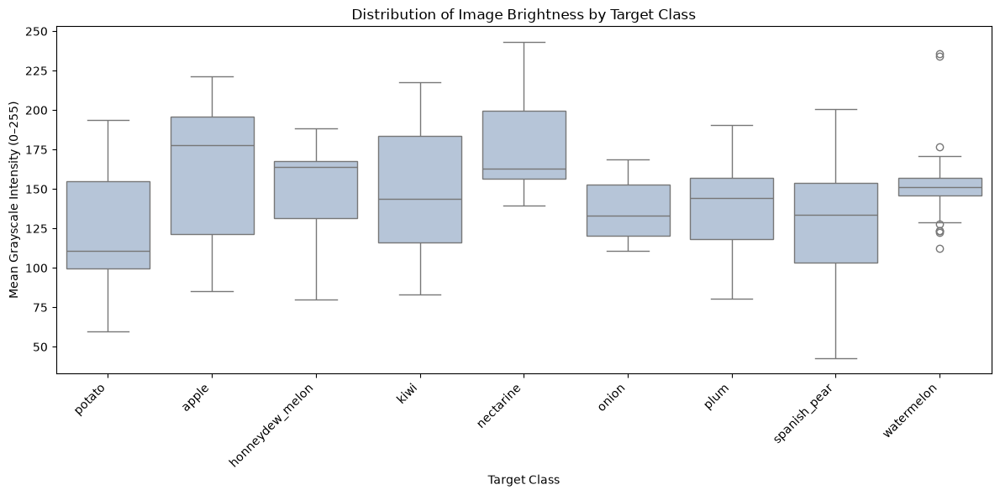

In [ ]:
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="target_class",
    y="brightness",
    color="lightsteelblue"
)

plt.title("Distribution of Image Brightness by Target Class")
plt.xlabel("Target Class")
plt.ylabel("Mean Grayscale Intensity (0–255)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 3.19.6 Brightness Distribution Findings

The boxplot shows differences in median brightness, variation, and outliers across the nine classes.

**Key observations**

- **Apple:** A relatively high median brightness (approximately 177) and a wide spread.
- **Potato:** A low median brightness (approximately 110), with considerable variation.
- **Spanish pear:** A wide distribution, including the lowest brightness value in the dataset (42.91).
- **Onion and watermelon:** Relatively narrow distributions, although watermelon has some outliers.
- **Kiwi, plum, and nectarine:** Noticeable variation in brightness between images.

**Interpretation**

Brightness varies both between and within classes. Some classes have more consistent brightness, while others contain both dark and bright images.

These differences may reflect lighting, object colors, or backgrounds. They could provide unintended cues for classification, but the boxplot does not show whether a model uses them.

#### 3.19.7 Kruskal–Wallis Test and Effect Size for Brightness

We use the Kruskal–Wallis test to examine whether brightness distributions differ significantly between the nine classes.

This non-parametric test compares multiple independent groups without requiring normally distributed data.

**Hypotheses**

- **H₀:** Brightness distributions are identical across all nine classes.
- **H₁:** At least one class has a different brightness distribution.

We use a significance level of α = 0.05. Since both brightness and sharpness are tested, a Bonferroni correction gives an adjusted threshold of **0.025** for each test.

**Effect size**

We also calculate epsilon squared (ε²) to estimate the strength of the differences between classes, since statistical significance alone does not show how large these differences are.

**Limitations**

Images from the same photography sessions may not be independent, which can affect the reliability of the test.

Brightness differences may also reflect lighting, backgrounds, and object appearance rather than class-specific properties alone.

In [ ]:
from scipy.stats import kruskal

# Collect brightness measurements for each target class.
brightness_groups = [
    group["brightness"].dropna().values
    for _, group in df.groupby("target_class")
]

# Perform the Kruskal-Wallis test.
brightness_h, brightness_p = kruskal(*brightness_groups)

# Bonferroni correction for two planned tests.
brightness_adjusted_p = min(brightness_p * 2, 1.0)

print(f"Kruskal-Wallis H statistic: {brightness_h:.3f}")
print(f"p-value: {brightness_p:.6g}")
print(f"Bonferroni-adjusted p-value: {brightness_adjusted_p:.6g}")
print(f"Significant at alpha = 0.05: {brightness_adjusted_p < 0.05}")

# Calculate epsilon squared effect size.
n = sum(len(group) for group in brightness_groups)
k = len(brightness_groups)

brightness_epsilon_squared = max(
    0,
    (brightness_h - k + 1) / (n - k)
)

print(f"Epsilon squared effect size: {brightness_epsilon_squared:.3f}")

Kruskal-Wallis H statistic: 560.648
p-value: 6.70507e-116
Bonferroni-adjusted p-value: 1.34101e-115
Significant at alpha = 0.05: True
Epsilon squared effect size: 0.277


#### 3.19.8 Brightness Statistical Test and Effect Size – Findings

The Kruskal–Wallis test found statistically significant differences in brightness distributions across the nine classes.

**Statistical results**

- **H statistic:** 560.648
- **p-value:** 6.70507 × 10⁻¹¹⁶
- **Bonferroni-adjusted p-value:** 1.34101 × 10⁻¹¹⁵
- **Epsilon squared (ε²):** 0.277

The adjusted p-value is well below the significance threshold of 0.025. We therefore reject the null hypothesis, assuming the test's requirements are met.

The effect size indicates a substantial rank-based difference between classes. However, the test does not identify which specific classes differ, and ε² should not be interpreted as the exact proportion of brightness variance explained by class.

**Implications for modeling**

Brightness differences could provide unintended clues to a classification model, creating a risk of shortcut learning.

However, these differences may reflect lighting, backgrounds, or object appearance. The results do not prove that a model uses brightness as a shortcut or that brightness affects classification performance.

**Limitations**

Images from the same photography sessions may not be independent, making the extremely small p-value less reliable.

The findings describe this dataset and may not generalize to independently captured images.

### 3.20 Image Sharpness Analysis

#### 3.20.1 Calculating Sharpness Using Laplacian Variance

We estimate image sharpness using the **variance of the Laplacian**, which measures variation in edges and fine details in grayscale images.

- **Higher values:** Generally indicate stronger edges and more fine details.
- **Lower values:** May indicate smoother regions or possible blur.

The calculation is applied to all 2,003 images, and the results are stored in the `sharpness` column.

Descriptive statistics are calculated for the full dataset and each of the nine classes to explore differences in edge detail that may be relevant for classification.

**Limitations**

Laplacian variance is not a direct measure of focus quality. It is also affected by object texture, contrast, backgrounds, and visible edges.

Since the entire image is analyzed, differences between classes cannot automatically be interpreted as differences in camera focus or image quality.

**Laplacian Variance**

Laplacian Variance is a measure used to estimate image sharpness by analyzing changes in pixel intensity around edges and details.

Higher values generally indicate more pronounced edges and details, while lower values may indicate blur.

However, the measure is also affected by image texture, contrast, and background, so it should not be interpreted as a perfect measure of image sharpness.

In [ ]:
import cv2
import pandas as pd

def calculate_sharpness(image_path):
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    laplacian = cv2.Laplacian(image, cv2.CV_64F)

    return laplacian.var()

df["sharpness"] = df["image_path"].apply(calculate_sharpness)

print("Sharpness summary:")
display(df["sharpness"].describe())

print("\nSharpness by class:")
sharpness_by_class = (
    df.groupby("target_class")["sharpness"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(sharpness_by_class)

Sharpness summary:


count    2003.000000
mean       32.371523
std        33.178862
min         0.691841
25%         4.602139
50%        26.840736
75%        45.769993
max       310.045912
Name: sharpness, dtype: float64


Sharpness by class:


,count,mean,median,std,min,max
target_class,,,,,,
apple,367,20.21,8.46,23.34,1.54,164.49
honneydew_melon,145,23.97,21.89,22.27,1.01,87.47
kiwi,171,74.12,66.03,35.35,3.89,176.65
nectarine,247,22.65,23.33,11.75,1.63,50.70
onion,75,69.01,70.34,15.59,22.19,113.61
plum,264,3.36,3.31,1.16,0.69,6.78
potato,383,49.35,38.91,34.13,0.77,310.05
spanish_pear,159,2.84,2.74,1.53,0.69,7.31
watermelon,192,53.45,46.63,30.69,1.56,147.22


#### 3.20.2 Sharpness Statistics Findings

Laplacian variance was calculated for all 2,003 images, revealing substantial differences in edge detail across the dataset.

**Overall statistics**

- **Mean:** 32.37
- **Median:** 26.84
- **Standard deviation:** 33.18
- **Range:** 0.69–310.05

The mean is higher than the median, suggesting that some high values influence the average.

**Class-level findings**

- **Kiwi** has the highest mean (74.12), while **onion** has the highest median (70.34).
- **Watermelon and potato** also show relatively high values. Potato contains the highest individual value (310.05).
- **Spanish pear and plum** have the lowest medians (2.74 and 3.31).
- **Apple** has a much higher mean (20.21) than median (8.46), indicating that high-value observations affect its average.

**Interpretation and implications**

The results show considerable differences in edge variation between classes.

However, Laplacian variance is influenced by object texture, contrast, backgrounds, and image composition—not just focus quality.

Therefore, low values do not necessarily indicate blurry images, and high values do not guarantee better image quality.

These differences may be relevant for classification, but images should be visually inspected before using sharpness thresholds to exclude data.

#### 3.20.3 Visual Inspection of Images with Extreme Laplacian Variance

We visually inspect the three images with the lowest and the three with the highest Laplacian variance values.

The six images are displayed in a 2 × 3 grid, labeled with their target class and Laplacian variance.

**Purpose**

This helps us examine whether extreme values reflect actual blur or differences in object texture, contrast, and background details.

**Limitations**

Only six extreme examples are inspected, so they cannot represent the overall image quality of each class.

Visual inspection is also subjective, and Laplacian variance is not a definitive measure of focus quality.

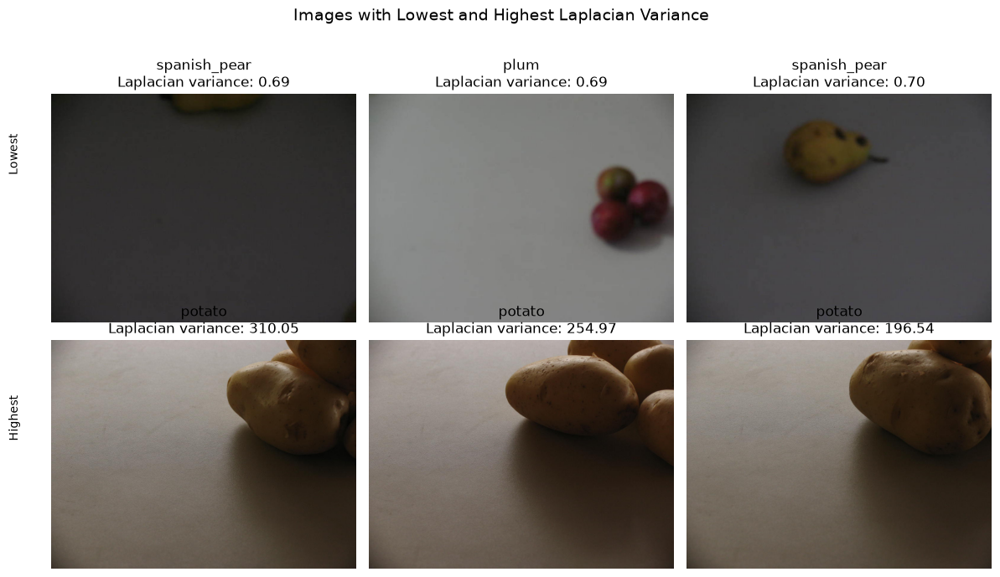

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Select the three lowest and three highest Laplacian variance scores
lowest = df.nsmallest(3, "sharpness")
highest = df.nlargest(3, "sharpness")

examples = pd.concat([lowest, highest])

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"{row['target_class']}\n"
        f"Laplacian variance: {row['sharpness']:.2f}"
    )
    ax.axis("off")

fig.suptitle(
    "Images with Lowest and Highest Laplacian Variance",
    fontsize=14
)

fig.text(0.01, 0.73, "Lowest", rotation=90, va="center")
fig.text(0.01, 0.28, "Highest", rotation=90, va="center")

fig.tight_layout(rect=[0.04, 0, 1, 0.94])
plt.show()

#### 3.20.4 Visual Inspection Findings

Visual inspection of the six images with the most extreme Laplacian variance values shows clear differences in edge detail and image composition.

**Key findings**

- **Lowest values:** Two Spanish pear images (0.69 and 0.70) and one plum image (0.69) show limited visible detail, smooth backgrounds, low contrast, or possible blur.
- **Highest values:** All three images belong to the potato class (310.05, 254.97, and 196.54). They contain visible surface textures, shadows, and strong edges.

**Interpretation**

These examples suggest that Laplacian variance is influenced by object texture, contrast, backgrounds, and image composition—not just camera focus.

Low values do not necessarily indicate blurry images, while high values do not guarantee better image quality.

**Implications for dataset preparation**

Laplacian variance should not be used alone to remove images from the dataset.

Filtering based only on low values could unfairly affect classes with smoother objects or backgrounds. Visual inspection would be needed before applying any sharpness threshold.

#### 3.20.5 Visualization of Laplacian Variance by Target Class

We use a boxplot to compare Laplacian variance across the nine classes.

The plot shows the median, interquartile range (IQR), and spread of values, helping us identify differences and overlaps between classes.

Outlier markers are hidden using `showfliers=False` to make the central distributions easier to compare. This only affects the visualization; no data or statistics are changed.

**Limitations**

Laplacian variance is affected by object texture, contrast, backgrounds, and image composition.

Therefore, differences between classes cannot be interpreted solely as differences in camera focus or image quality.

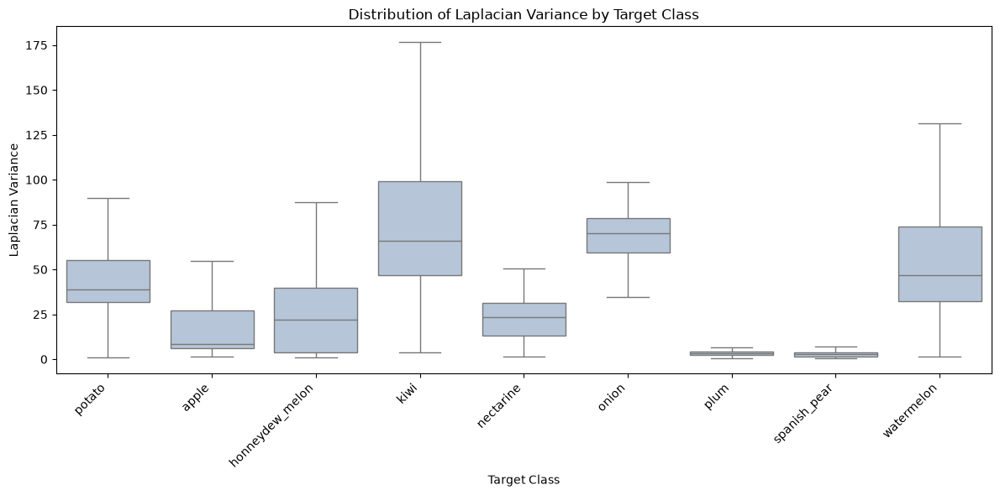

In [ ]:
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="target_class",
    y="sharpness",
    color="lightsteelblue",
    showfliers=False
)

plt.title("Distribution of Laplacian Variance by Target Class")
plt.xlabel("Target Class")
plt.ylabel("Laplacian Variance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 3.20.6 Laplacian Variance Distribution Findings

The boxplot shows substantial differences in Laplacian variance between the nine classes.

**Key findings**

- **Onion** has the highest median (70.34) and a relatively narrow distribution.
- **Kiwi** also has a high median (66.03), but shows greater variation.
- **Watermelon and potato** have intermediate-to-high medians (46.63 and 38.91), with considerable within-class variation.
- **Plum and Spanish pear** have the lowest medians (3.31 and 2.74), with relatively narrow distributions.
- **Apple** has a low median (8.46), although some images have much higher values.

**Interpretation**

These differences may reflect object texture, contrast, backgrounds, and image composition rather than camera focus alone.

The results suggest that edge-related features may be relevant for classification, but they do not establish whether these features improve model performance.

**Implications for dataset preparation**

Using a single Laplacian variance threshold to remove blurry images could disproportionately affect classes with smoother objects or backgrounds.

Therefore, visual inspection is needed before making image-quality decisions based on this metric.

#### 3.20.7 Kruskal–Wallis Test and Effect Size for Sharpness

We use the Kruskal–Wallis test to examine whether Laplacian variance distributions differ significantly between the nine classes.

**Hypotheses**

- **H₀:** Laplacian variance distributions are identical across all nine classes.
- **H₁:** At least one class has a different distribution.

The significance level is α = 0.05. Since both brightness and sharpness are tested, a Bonferroni correction gives an adjusted threshold of **0.025** for each test.

We also calculate epsilon squared (ε²) to estimate the strength of the differences between classes.

**Limitations**

Laplacian variance reflects edge detail and is influenced by texture, contrast, backgrounds, and image noise—not just focus quality.

Images from the same photography sessions may also lack statistical independence.

The results are therefore treated as exploratory evidence of differences in edge variation, rather than definitive differences in image quality.

In [ ]:
from scipy.stats import kruskal

# Collect sharpness measurements for each target class.
sharpness_groups = [
    group["sharpness"].dropna().values
    for _, group in df.groupby("target_class")
]

# Perform the Kruskal-Wallis test.
sharpness_h, sharpness_p = kruskal(*sharpness_groups)

# Bonferroni correction for two planned tests.
sharpness_adjusted_p = min(sharpness_p * 2, 1.0)

# Calculate epsilon squared effect size.
n = sum(len(group) for group in sharpness_groups)
k = len(sharpness_groups)

sharpness_epsilon_squared = max(
    0,
    (sharpness_h - k + 1) / (n - k)
)

print(f"Kruskal-Wallis H statistic: {sharpness_h:.3f}")
print(f"p-value: {sharpness_p:.6g}")
print(f"Bonferroni-adjusted p-value: {sharpness_adjusted_p:.6g}")
print(f"Significant at alpha = 0.05: {sharpness_adjusted_p < 0.05}")
print(f"Epsilon squared effect size: {sharpness_epsilon_squared:.3f}")

Kruskal-Wallis H statistic: 1289.793
p-value: 3.77896e-273
Bonferroni-adjusted p-value: 7.55791e-273
Significant at alpha = 0.05: True
Epsilon squared effect size: 0.643


#### 3.20.8 Sharpness Statistical Test and Effect Size – Findings

The Kruskal–Wallis test found statistically significant differences in Laplacian variance distributions across the nine classes.

**Statistical results**

- **H statistic:** 1289.793
- **p-value:** 3.77896 × 10⁻²⁷³
- **Bonferroni-adjusted p-value:** 7.55791 × 10⁻²⁷³
- **Epsilon squared (ε²):** 0.643

The adjusted p-value is well below the significance threshold of 0.025. We therefore reject the null hypothesis, assuming the test's requirements are met.

The effect size indicates a strong rank-based difference between classes. It is larger than the effect size for brightness (ε² = 0.277), suggesting that Laplacian variance is more strongly associated with class in this dataset.

However, the test does not identify which specific classes differ, and ε² does not directly measure predictive usefulness.

**Implications for modeling**

Class-related differences in edge detail could provide useful information for classification.

However, Laplacian variance is influenced by object texture, backgrounds, contrast, and image noise—not just camera focus. The results do not establish whether these differences improve model performance or generalization.

**Limitations**

Images from the same photography sessions may not be independent, making the extremely small p-value less reliable.

The findings describe the observed dataset and cannot determine whether the differences are caused mainly by object characteristics or photography conditions.

### 3.21 EDA Findings and Implications for Modeling

The exploratory data analysis (EDA) examined the dataset's structure, class distribution, image properties, visual characteristics, potential duplicates, background colors, object colors, brightness, and edge variation.

The purpose was to understand the available data, identify potential limitations, and establish a foundation for preprocessing, dataset splitting, model development, and evaluation.

#### 3.21.1 Dataset Composition and Class Distribution

The original dataset contained 2,633 readable images distributed across 15 original classes.

After excluding four classes and merging related categories, the final dataset contains **2,003 images across nine target classes**.

The target classes are:

- Apple
- Honneydew melon
- Kiwi
- Nectarine
- Onion
- Plum
- Potato
- Spanish pear
- Watermelon

The dataset is moderately imbalanced. Potato (383 images) and apple (367 images) are the largest classes, while onion (75 images) is the smallest.

**Implications for modeling**

Class imbalance should be considered when evaluating model performance. Overall accuracy alone may hide poor performance on smaller classes.

Therefore, macro-averaged F1-score, per-class precision and recall, and confusion matrices should complement accuracy.

A stratified train, validation, and test split should also be considered to preserve class representation across the subsets.

#### 3.21.2 Image Format, Dimensions, and Visual Variation

The image integrity analysis found that all 2,003 selected images could be read successfully.

The images are stored in JPEG format, use RGB color mode, and have consistent dimensions of 1024 × 768 pixels.

Visual inspection revealed differences in object size, position, quantity, color, lighting, shadows, and background appearance.

Some images contain multiple objects, while others show a single object occupying a smaller or larger portion of the image.

**Implications for modeling**

The consistent image dimensions simplify preprocessing, but images will likely need to be resized to a suitable input resolution for model training.

Pixel values should be normalized consistently.

Training data augmentation may help models become more robust to variations in object position, orientation, scale, and lighting. However, augmentation choices should preserve the target class and avoid introducing unrealistic transformations.

The original aspect ratio should be considered when choosing a resizing strategy.

#### 3.21.3 Duplicate Detection and Potential Data Leakage

The exact duplicate analysis did not identify any identical image files using SHA-256 hashing.

However, perceptual hashing (pHash) identified visually similar images.

The analysis found:

- Four groups of images sharing identical perceptual hashes, involving nine images in total.
- 36 within-class image pairs with a perceptual hash distance of five or less.
- 58 unique images involved in these potential near-duplicate pairs, corresponding to approximately 2.90% of the dataset.

Visual inspection confirmed that some of these images contain very similar object arrangements or appearances.

Filename analysis also showed that some visually similar images have nearby numerical filename suffixes. However, consecutive filenames were not consistently associated with visual similarity.

**Implications for modeling**

Potential near-duplicates create a risk of data leakage if highly similar images are distributed across training, validation, and test sets.

Such leakage could produce overly optimistic evaluation results because the model may encounter nearly identical visual content during training and testing.

Before splitting the dataset, the identified near-duplicate relationships should be reviewed and considered when constructing the subsets.

Where appropriate, connected groups of visually similar images should be kept within the same subset.

Perceptual hash similarity is not definitive proof that images depict the same physical object, so automated grouping should be interpreted carefully.

#### 3.21.4 Background Characteristics and Potential Shortcut Learning

The initial background color analysis estimated RGB values using pixels from the four image corners.

The results revealed differences in estimated corner colors between target classes, as well as variation within individual classes. Some classes showed relatively consistent corner colors, while others exhibited greater variation.

However, the corner-based method assumes that the sampled regions mainly contain background pixels. This assumption may not hold for every image, as corners can also contain objects, shadows, or other image details.

**Background Color Masking Experiment**

To further investigate the influence of background colors, a simplified background masking method was evaluated.

Rather than attempting precise object segmentation, the method estimated the background RGB color from the image corners and identified pixels with similar colors using Euclidean RGB distance. These pixels were replaced with black, while the remaining original pixel values were retained for histogram extraction.

Different masking thresholds were explored, with thresholds of 65 and 80 selected for further comparison.

Visual inspection across all nine target classes showed that the method could suppress substantial background regions without requiring precise object boundaries. However, its effectiveness varied between images. Some background regions remained visible, while pixels belonging to the fruits or vegetables were occasionally removed.

RGB histograms were compared before and after masking. The original histograms included all image pixels, whereas the masked histograms were calculated using only the remaining, unmasked pixels. All histograms were normalized to allow comparisons despite differences in the number of retained pixels.

The comparisons showed that masking reduced prominent color intensity peaks associated with light-colored backgrounds in several images, allowing other color distributions to become more visible.

The method was also evaluated on 45 reproducibly selected images, five per target class, using thresholds of 65 and 80.

The results showed considerable variation in masked pixel percentages across images and classes.

Importantly, the proportion of masked pixels depends partly on how much of the image is occupied by the object. For example, a large watermelon occupying most of the image may naturally leave less background to mask than smaller plums occupying a smaller proportion of the image.

Therefore, a higher masked pixel percentage does not necessarily indicate more successful background removal. It may also reflect differences in object size, image composition, illumination, or the removal of object pixels.

**Implications for Modeling**

Class-associated background characteristics could potentially become shortcuts during model training.

Instead of learning only the appearance of fruits and vegetables, a model might also associate particular background colors or lighting conditions with specific labels.

The background masking experiments suggest that simplified color-based masking may help reduce the influence of these background characteristics when extracting RGB histogram features.

However, background masking does not guarantee that only object pixels are retained, and removing background-like colors may also remove useful object information.

The effectiveness of masking should therefore be evaluated during model training by comparing histogram features extracted from original images with features extracted using thresholds of 65 and 80.

The EDA does not establish that shortcut learning occurs or that background masking improves classification performance. These questions require model-based evaluation, including testing on photographs taken outside the original dataset.

No final masking threshold was selected during EDA.

#### 3.21.5 Object Color Analysis

Initial experiments with automatic foreground segmentation, including color-based background removal and GrabCut, did not provide sufficiently reliable object isolation for the exploratory color analysis.

Therefore, rectangular regions of interest (ROIs) were manually selected to examine object colors more directly while reducing background interference.

A total of **45 ROIs were annotated**, representing five images from each of the nine target classes.

The saved ROI annotations were validated, with 45 unique image paths and no invalid region dimensions.

The analysis included:

- Mean RGB intensities for each selected ROI.
- Average RGB intensities by target class.
- A scatter plot comparing red and green intensities.
- Normalized RGB intensity histograms based on the ROI measurements.
- A subsequent comparison of RGB histograms extracted from original and background-masked images.

The manual ROI analysis revealed both differences and overlap in color characteristics between classes.

Some classes displayed recognizable color patterns, while others had similar RGB intensities. Variation was also observed within individual classes.

The subsequent background masking experiment demonstrated that color distributions can also be extracted automatically without manually selecting ROIs.

Unlike the ROI-based analysis, which examined color measurements from selected object regions, the background masking approach calculated RGB histograms from all pixels that remained after applying a color-distance threshold.

This approach is more suitable for automated feature extraction, although the remaining pixels may still include background regions or exclude parts of the object.

**Implications for Modeling**

Color is likely to provide useful information for distinguishing some fruits and vegetables, but simple average RGB values are unlikely to separate all nine classes reliably.

RGB histograms offer a more detailed representation of color distributions than average RGB values alone and may therefore be useful as features for a traditional machine learning baseline, such as logistic regression.

The EDA identified three potential feature extraction approaches for subsequent model evaluation:

- RGB histograms calculated from original images.
- RGB histograms calculated after background masking with threshold 65.
- RGB histograms calculated after background masking with threshold 80.

Comparing these approaches during model training and validation can help determine whether reducing background color variation improves classification performance.

However, RGB histograms do not preserve the spatial arrangement of colors. Models that use additional visual information, including shape, texture, and spatial patterns, may therefore be better suited to distinguishing classes with overlapping color distributions.

The manually selected ROIs were used only for exploratory analysis. Because they cover five images per class, their color distributions should not be treated as representative measurements of the entire dataset.

Similarly, the background masking experiments provide exploratory evidence about changes in color distributions, not proof that the resulting features improve classification accuracy.

#### 3.21.6 Image Brightness

Brightness was calculated as the mean grayscale intensity of each complete image.

Across the 2,003 images, the mean brightness was **146.78**, with a standard deviation of **36.40**.

The measurements ranged from **42.91 to 243.11**.

Class-level comparisons revealed noticeable differences:

- Nectarine had the highest mean brightness (176.51).
- Potato had the lowest mean brightness (118.87).
- Spanish pear showed the highest within-class standard deviation (39.76).
- Watermelon showed the lowest within-class standard deviation (12.43).

The boxplot also revealed differences in medians, interquartile ranges, and outlying observations.

**Implications for modeling**

Brightness variation should be considered when selecting preprocessing and augmentation methods.

Moderate brightness and contrast augmentation may help models generalize to different lighting conditions.

However, brightness was measured across the entire image, so the observed differences may reflect object colors, backgrounds, lighting, or a combination of these factors.

The analysis does not establish that brightness differences will directly affect classification performance.

#### 3.21.7 Laplacian Variance and Edge Detail

Laplacian variance was calculated for all images as an exploratory indicator of edge variation.

The overall mean was **32.37**, and the median was **26.84**, with values ranging from approximately **0.69 to 310.05**.

Substantial differences were observed between classes:

- Onion had the highest median Laplacian variance (70.34).
- Kiwi had the highest mean Laplacian variance (74.12).
- Spanish pear and plum had particularly low median values (2.74 and 3.31, respectively).
- Potato contained the highest individual value (310.05).

Visual inspection of the extreme images showed that low values were associated with limited visible detail, smooth backgrounds, low contrast, or possible blur.

High values were observed in potato images containing visible surface texture and stronger intensity transitions.

**Implications for modeling**

Laplacian variance should not be interpreted as a definitive measure of image focus or quality.

The metric is also influenced by texture, contrast, background details, and image composition.

Automatically excluding images using a single sharpness threshold could disproportionately affect classes with naturally smoother visual characteristics.

Therefore, any image-quality filtering should be supported by visual inspection and a clearly justified methodology.

#### 3.21.8 Recommended Modeling Strategy

Based on the EDA findings, the following approach is recommended for the next project stages.

**1. Dataset splitting**

Create a reproducible training, validation, and test split, targeting approximately 80%, 10%, and 10% of the images, respectively.

Preserve class representation where possible and address potential near-duplicate leakage before assigning images to subsets.

The same split should be used for all models to support fair comparisons.

**2. Image preprocessing**

Resize images to a consistent model input size and apply appropriate pixel normalization.

Choose preprocessing methods that preserve relevant object characteristics.

If data augmentation is used, apply it only to training images, not validation or test images.

**3. Model development**

Develop and compare models with different levels of complexity, including:

- A logistic regression baseline using a suitable image representation.
- A convolutional neural network (CNN) trained from scratch.
- A transfer learning model, if included in the final project scope.

These approaches can help assess whether more advanced visual feature learning improves classification performance.

**4. Model evaluation**

Evaluate all models using consistent metrics:

- Overall accuracy.
- Macro-averaged F1-score.
- Per-class precision and recall.
- Confusion matrix.

Pay particular attention to smaller classes and classes with potentially overlapping visual characteristics.

Use the validation set for model selection and tuning, and reserve the test set for final evaluation.

**5. External image testing**

Evaluate the final model on photographs captured outside the original dataset.

This is particularly important because the EDA identified class-associated differences in background appearance, brightness, and other visual characteristics.

External testing can provide additional evidence about the model's ability to generalize beyond the original image collection.

#### 3.21.9 Overall EDA Conclusion

The EDA identified several characteristics relevant to the classification task.

The dataset contains nine target classes with unequal representation, visually similar images, substantial variation in object appearance, and class-associated differences in background color, brightness, and edge detail.

The object color analysis also showed that RGB information provides useful descriptive characteristics but does not completely separate the target classes.

These findings suggest that successful classification will likely require models capable of combining multiple visual features rather than relying on a single property such as color or brightness.

The most important methodological priorities for the next stage are:

- Preventing potential data leakage from visually similar images.
- Using a consistent and reproducible dataset split.
- Addressing class imbalance during evaluation.
- Applying appropriate preprocessing and training-only augmentation.
- Comparing models using multiple performance metrics.
- Evaluating generalization on external photographs.

The EDA provides a foundation for these decisions, but their effectiveness must be assessed empirically during model training and evaluation.

## 4. Dataset Splitting

The split below is created once and saved to `data/dataset_split.csv`. Every model in this notebook uses that file, so the baseline and the CNN are evaluated on exactly the same photos.

### 4.1 Verify the Selected Dataset

Before dividing the dataset into training, validation, and test sets, we verify that the selected images and target classes match the dataset used in the exploratory data analysis.

The dataset contains 2,003 images across nine target classes.

The objective is to create a reproducible split with approximately 80% training, 10% validation, and 10% test data, while reducing the risk of data leakage from visually similar images.

In [ ]:
# Verify the dataset before splitting

print("Total number of images:", len(df))
print("Number of target classes:", df["target_class"].nunique())

print("\nImages per class:")
print(df["target_class"].value_counts().sort_index())

print("\nMissing values:")
print(df[["image_path", "target_class", "phash"]].isna().sum())

Total number of images: 2003
Number of target classes: 9

Images per class:
target_class
apple              367
honneydew_melon    145
kiwi               171
nectarine          247
onion               75
plum               264
potato             383
spanish_pear       159
watermelon         192
Name: count, dtype: int64

Missing values:
image_path      0
target_class    0
phash           0
dtype: int64


#### Findings – Dataset Verification

The dataset verification confirmed that the selected dataset contains **2,003 images across nine target classes**, consistent with the earlier EDA.

No missing values were found in `image_path`, `target_class`, or `phash`.

The class distribution is imbalanced, ranging from 75 images in the `onion` class to 383 images in the `potato` class.

These findings confirm that the dataset is ready for the splitting procedure. A stratified approach will be used to preserve approximately the same class proportions across the training, validation, and test sets.

### 4.2 Handling Potential Near-Duplicates

The earlier EDA identified 36 potentially near-duplicate image pairs involving 58 unique images, using a perceptual hash Hamming distance threshold of 5.

To reduce the risk of data leakage, these 58 images will be reserved for the training set rather than being distributed across training, validation, and test sets.

Before creating the split, we verify that all identified image paths are present in the selected dataset.

This approach reduces the risk of leakage from the identified pairs but does not guarantee that all visually similar images have been detected.

In [ ]:
# Retrieve image paths identified as potentially similar
near_duplicate_paths = set(similar_images)

# Retrieve all selected dataset image paths
dataset_paths = set(df["image_path"])

# Check that the identified paths belong to the selected dataset
missing_paths = near_duplicate_paths - dataset_paths

print("Identified near-duplicate images:", len(near_duplicate_paths))
print("Images missing from the selected dataset:", len(missing_paths))

# Verify that all identified paths are available
assert len(missing_paths) == 0, (
    "Some near-duplicate image paths are missing from the dataset."
)

Identified near-duplicate images: 58
Images missing from the selected dataset: 0


#### 4.2.1 Cross-Class Perceptual Hash Similarity

The earlier EDA identified potentially near-duplicate image pairs within the same target class using a Hamming distance threshold of 5.

However, visually similar images may also occur across different target classes.

This step compares perceptual hashes between images belonging to different classes to identify any additional potentially similar pairs.

The purpose is to investigate possible cross-class similarities before creating the training, validation, and test splits.

A low Hamming distance indicates similarity between perceptual hashes but does not necessarily mean that the images are duplicates or incorrectly labeled.

In [ ]:
from itertools import combinations

# Use the same Hamming distance threshold as in the EDA
threshold = 5

# Prepare image paths, classes, and perceptual hashes
records = [
    (path, class_name, int(str(phash), 16))
    for path, class_name, phash in zip(
        df["image_path"],
        df["target_class"],
        df["phash"]
    )
]

# Store potentially similar pairs from different classes
cross_class_pairs = []

for (path1, class1, hash1), (path2, class2, hash2) in combinations(records, 2):

    if class1 == class2:
        continue

    # Count differing bits between the two perceptual hashes
    distance = (hash1 ^ hash2).bit_count()

    if distance <= threshold:
        cross_class_pairs.append({
            "image_1": path1,
            "class_1": class1,
            "image_2": path2,
            "class_2": class2,
            "distance": distance
        })

cross_class_pairs_df = pd.DataFrame(
    cross_class_pairs,
    columns=["image_1", "class_1", "image_2", "class_2", "distance"]
)

print("Cross-class similar pairs:", len(cross_class_pairs_df))

if not cross_class_pairs_df.empty:
    display(
        cross_class_pairs_df.sort_values("distance").head(10)
    )
else:
    print("No cross-class pairs found within the threshold.")

Cross-class similar pairs: 9


,image_1,class_1,image_2,class_2,distance
0,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,2
1,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,plum,4
2,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,4
3,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,4
4,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,4
5,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,4
6,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,kiwi,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,plum,4
7,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,plum,4
8,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,nectarine,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,plum,4


#### 4.2.2 Visual Inspection of Cross-Class Similarities

The cross-class perceptual hash comparison identified nine image pairs with a Hamming distance of 5 or less.

These pairs involve images assigned to different target classes, including kiwi, nectarine, and plum.

A low perceptual hash distance does not necessarily indicate that two images contain the same object. Similar backgrounds, lighting, or image composition may also produce similar hashes.

The identified pairs are therefore visually inspected before deciding whether they require special handling during dataset splitting.

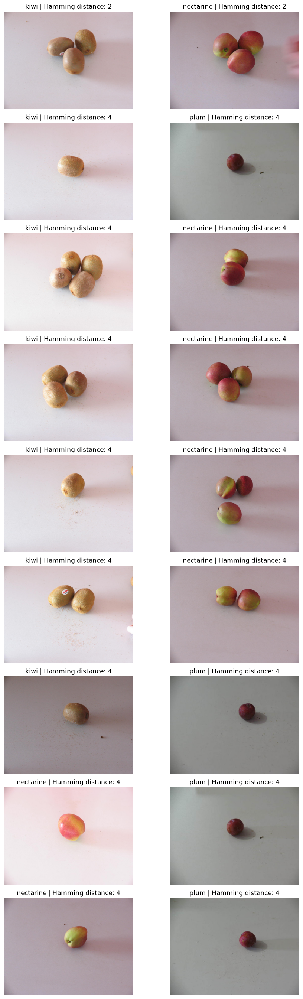

In [ ]:
# Display the cross-class pairs side by side
n_pairs = len(cross_class_pairs_df)

fig, axes = plt.subplots(
    n_pairs, 2,
    figsize=(10, 3 * n_pairs),
    squeeze=False
)

for i, pair in cross_class_pairs_df.iterrows():
    for j, (path_col, class_col) in enumerate([
        ("image_1", "class_1"),
        ("image_2", "class_2")
    ]):
        with Image.open(pair[path_col]) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(
            f"{pair[class_col]} | Hamming distance: {pair['distance']}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

##### Findings – Cross-Class Visual Inspection

The cross-class pHash analysis identified **nine image pairs** with a Hamming distance of 5 or less.

Visual inspection showed that the pairs contained different fruit types, primarily combinations of kiwi, nectarine, and plum.

Although their perceptual hashes were similar, the images did not appear to represent duplicate photographs of the same object.

The similarities were more likely related to shared visual characteristics, such as background, object placement, and overall image composition.

These matches were therefore treated as **false positives for duplicate detection** and do not require special grouping during dataset splitting.

This finding also demonstrates an important limitation of perceptual hashing: a low Hamming distance does not necessarily indicate that two images depict the same object.

### 4.3 Stratified Dataset Splitting

The selected dataset contains 2,003 images across nine target classes.

The objective is to create a reproducible split consisting of:

- **80% training data (1,603 images)**
- **10% validation data (200 images)**
- **10% test data (200 images)**

To reduce the risk of data leakage, the 58 images previously identified as potentially near-duplicates are reserved for the training set.

The remaining images are divided using stratified random sampling to maintain approximately the same class proportions across the three datasets.

A fixed random seed (`random_state=42`) is used to ensure reproducibility.

No image preprocessing or augmentation is performed in this step.

In [ ]:
from sklearn.model_selection import train_test_split

# Create a copy of the selected dataset
split_df = df.copy()

# Identify the 58 images reserved for training
reserved_mask = split_df["image_path"].isin(near_duplicate_paths)

reserved_train_df = split_df[reserved_mask].copy()
remaining_df = split_df[~reserved_mask].copy()

# Target dataset sizes
train_target = 1603
validation_target = 200
test_target = 200

# Calculate how many additional training images are needed
remaining_train_size = train_target - len(reserved_train_df)

# Split remaining images into training and temporary holdout sets
additional_train_df, holdout_df = train_test_split(
    remaining_df,
    train_size=remaining_train_size,
    test_size=validation_target + test_target,
    stratify=remaining_df["target_class"],
    random_state=42
)

# Divide the holdout set equally into validation and test
validation_df, test_df = train_test_split(
    holdout_df,
    train_size=validation_target,
    test_size=test_target,
    stratify=holdout_df["target_class"],
    random_state=42
)

# Combine reserved and additional training images
train_df = pd.concat(
    [reserved_train_df, additional_train_df],
    ignore_index=True
)

# Assign split labels
train_df["split"] = "train"
validation_df = validation_df.copy()
validation_df["split"] = "validation"
test_df = test_df.copy()
test_df["split"] = "test"

# Combine all assignments into one DataFrame
dataset_split_df = pd.concat(
    [train_df, validation_df, test_df],
    ignore_index=True
)

# Display the results
print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))
print("Total images:", len(dataset_split_df))

print("\nReserved near-duplicate images:", len(reserved_train_df))

print("\nSplit distribution:")
print(dataset_split_df["split"].value_counts())

Training images: 1603
Validation images: 200
Test images: 200
Total images: 2003

Reserved near-duplicate images: 58

Split distribution:
split
train         1603
validation     200
test           200
Name: count, dtype: int64


#### Findings – Stratified Dataset Splitting

The dataset was successfully divided into three subsets:

- **Training:** 1,603 images (80.03%)
- **Validation:** 200 images (9.99%)
- **Test:** 200 images (9.99%)

All 2,003 selected images were assigned to a dataset split.

The 58 previously identified potentially near-duplicate images were reserved for the training set before the remaining images were divided using stratified random sampling.

A fixed random seed of 42 was used to make the split reproducible.

Further validation is required to confirm that the subsets do not overlap and that class representation is appropriate.

### 4.4 Validating the Dataset Split

#### 4.4.1 Checking for Overlapping Images

This step verifies that each image appears in exactly one dataset split.

It also confirms that all 58 potentially near-duplicate images reserved for training are present in the training set.

These checks help ensure that the dataset split is consistent and reduce the risk of data leakage.

In [ ]:
# Collect image paths from each dataset split
train_paths = set(train_df["image_path"])
validation_paths = set(validation_df["image_path"])
test_paths = set(test_df["image_path"])

# Check for overlap between splits
train_validation_overlap = train_paths & validation_paths
train_test_overlap = train_paths & test_paths
validation_test_overlap = validation_paths & test_paths

print("Train / validation overlap:", len(train_validation_overlap))
print("Train / test overlap:", len(train_test_overlap))
print("Validation / test overlap:", len(validation_test_overlap))

# Verify that all reserved images are in training
reserved_outside_training = near_duplicate_paths - train_paths

print("\nReserved images outside training:", len(reserved_outside_training))

# Verify that every selected image has exactly one assignment
print("Unique images in final split:", dataset_split_df["image_path"].nunique())

assert len(train_validation_overlap) == 0
assert len(train_test_overlap) == 0
assert len(validation_test_overlap) == 0
assert len(reserved_outside_training) == 0
assert dataset_split_df["image_path"].nunique() == len(df)
assert len(dataset_split_df) == len(df)

Train / validation overlap: 0
Train / test overlap: 0
Validation / test overlap: 0

Reserved images outside training: 0
Unique images in final split: 2003


##### Findings – Split Overlap Verification

The validation confirmed that there is no image overlap between the training, validation, and test sets.

All 2,003 selected images have been assigned exactly once, and all 58 potentially near-duplicate images reserved for training are present in the training set.

These checks confirm that the split assignments are consistent and that the identified within-class near-duplicate images are not distributed across different subsets.

However, this does not guarantee that all possible sources of data leakage have been eliminated.

#### 4.4.2 Class Distribution Across Dataset Splits

This step examines how the nine target classes are distributed across the training, validation, and test sets.

Because the original dataset is imbalanced, stratified sampling was used to preserve approximately the same class proportions.

We compare both the number of images and the percentage distribution of each class across the three subsets.

In [ ]:
# Count images per class in each dataset split
class_counts = pd.crosstab(
    dataset_split_df["target_class"],
    dataset_split_df["split"]
)

# Arrange columns in a consistent order
class_counts = class_counts[["train", "validation", "test"]]

print("Images per class and split:")
display(class_counts)

# Calculate class proportions within each split
class_percentages = class_counts.div(
    class_counts.sum(axis=0),
    axis=1
) * 100

print("\nClass distribution (% within each split):")
display(class_percentages.round(2))

# Check that all nine classes appear in every split
all_classes_present = (class_counts > 0).all().all()

print("\nAll nine classes present in every split:", all_classes_present)

assert all_classes_present

Images per class and split:


split,train,validation,test
target_class,,,
apple,294,37,36
honneydew_melon,117,14,14
kiwi,140,16,15
nectarine,198,24,25
onion,60,7,8
plum,211,26,27
potato,305,39,39
spanish_pear,126,17,16
watermelon,152,20,20



Class distribution (% within each split):


split,train,validation,test
target_class,,,
apple,18.34,18.5,18.0
honneydew_melon,7.30,7.0,7.0
kiwi,8.73,8.0,7.5
nectarine,12.35,12.0,12.5
onion,3.74,3.5,4.0
plum,13.16,13.0,13.5
potato,19.03,19.5,19.5
spanish_pear,7.86,8.5,8.0
watermelon,9.48,10.0,10.0



All nine classes present in every split: True


##### Findings – Class Distribution Validation

The class distribution analysis confirmed that **all nine target classes are represented in the training, validation, and test sets**.

The class proportions are similar across the three subsets, indicating that stratified sampling successfully preserved the overall class distribution.

For example, the `apple` class represents 18.34% of training, 18.5% of validation, and 18.0% of test data.

The smallest class, `onion`, contains 60 training images, 7 validation images, and 8 test images.

Although the original dataset is imbalanced, the resulting split maintains comparable class proportions across all subsets.

These results support using the split for consistent model training and evaluation.

### 4.5 Saving the Dataset Split

The validated dataset split is saved as a CSV file to ensure that all group members use the same training, validation, and test images.

The CSV file contains three columns:

- `image_path`: The image location relative to the project root.
- `target_class`: The selected fruit or vegetable class.
- `split`: The assigned dataset partition (`train`, `validation`, or `test`).

Relative paths are used instead of absolute paths to make the file portable across different computers.

The saved file is read back and validated to confirm that all 2,003 images and their split assignments have been preserved.

No image preprocessing or augmentation is performed in this step.

In [ ]:
from pathlib import Path

# Create a portable CSV containing the final split assignments
export_df = dataset_split_df[
    ["image_path", "target_class", "split"]
].copy()

# Convert absolute image paths to project-relative paths
export_df["image_path"] = export_df["image_path"].apply(
    lambda path: Path(path).relative_to(project_root).as_posix()
)

# Sort rows for a consistent and readable CSV file
export_df = export_df.sort_values(
    ["split", "target_class", "image_path"]
).reset_index(drop=True)

# Save the shared dataset split
output_path = project_root / "data" / "dataset_split.csv"

# The shared split file is only written if it does not exist yet.
# If it exists, we check that the split recreated here is identical,
# so that every model keeps using the same photos.
if output_path.exists():
    existing_split = pd.read_csv(output_path)
    assert existing_split.equals(export_df), (
        "The recreated split differs from data/dataset_split.csv"
    )
    print("The existing split file matches the recreated split.")
else:
    export_df.to_csv(output_path, index=False)

# Read the saved file back
loaded_split_df = pd.read_csv(output_path)

# Verify that the saved file contains the expected data
assert len(loaded_split_df) == len(df)
assert loaded_split_df["image_path"].nunique() == len(df)
assert set(loaded_split_df["split"]) == {
    "train", "validation", "test"
}
assert loaded_split_df.equals(export_df)

# Verify that all relative image paths resolve to existing files
missing_files = sum(
    not (project_root / path).is_file()
    for path in loaded_split_df["image_path"]
)

assert missing_files == 0, "Some image files could not be found."

print("Saved CSV:", output_path)
print("Total images:", len(loaded_split_df))
print("Missing image files:", missing_files)

print("\nSplit distribution:")
print(loaded_split_df["split"].value_counts())

print("\nFirst five rows:")
display(loaded_split_df.head())

Saved CSV: c:\Users\JRD\GroupProjectGrupp1BI25\group-project\data\dataset_split.csv
Total images: 2003
Missing image files: 0

Split distribution:
split
train         1603
test           200
validation     200
Name: count, dtype: int64

First five rows:


,image_path,target_class,split
0,data/raw_images/fuji_apple/fuji_apple_002.jpg,apple,test
1,data/raw_images/fuji_apple/fuji_apple_023.jpg,apple,test
2,data/raw_images/fuji_apple/fuji_apple_046.jpg,apple,test
3,data/raw_images/fuji_apple/fuji_apple_053.jpg,apple,test
4,data/raw_images/fuji_apple/fuji_apple_061.jpg,apple,test


#### Findings – Saved Dataset Split

The final dataset split was successfully saved to `data/dataset_split.csv`.

The CSV file contains **2,003 images** with their corresponding relative image paths, target classes, and split assignments.

The final distribution is:

- **Training:** 1,603 images (80.03%)
- **Validation:** 200 images (9.99%)
- **Test:** 200 images (9.99%)

The saved CSV file was read back successfully, and its contents matched the original split assignments.

All image paths were verified, with **zero missing image files**.

The split also passed the earlier validation checks: no image paths overlap between subsets, all nine target classes are represented, and all 58 identified potentially near-duplicate images are reserved for training.

The dataset split is therefore ready to be shared with the project group and used consistently for preprocessing, model training, and evaluation.

**Limitation:** Reserving identified near-duplicate images for training reduces the risk of data leakage but does not guarantee that all visually similar images or repeated physical objects have been detected.

### 4.6 Investigating Image Capture Dates for Potential Data Leakage

The current dataset split uses stratified random sampling and reserves images identified as potential near-duplicates for the training set.

However, perceptual hashing may not identify photographs of the same physical object taken from different angles or positions.

To investigate whether grouping images by photography session could provide a more independent evaluation, we first examine the availability of image capture dates in the EXIF metadata.

This analysis does not modify the existing dataset split.

In [ ]:
from PIL import Image, ExifTags

def get_capture_date(image_path):
    with Image.open(image_path) as image:
        exif = image.getexif()

        for tag_id, value in exif.items():
            tag_name = ExifTags.TAGS.get(tag_id, tag_id)

            if tag_name == "DateTimeOriginal":
                return str(value)

        # DateTimeOriginal may be stored in the EXIF sub-IFD.
        exif_ifd = exif.get_ifd(0x8769)
        if exif_ifd:
            date_original = exif_ifd.get(36867)
            if date_original:
                return str(date_original)

    return None


exif_dates = df[["image_path", "target_class"]].copy()

exif_dates["capture_date"] = exif_dates["image_path"].apply(
    get_capture_date
)

print(f"Total images: {len(exif_dates)}")
print(f"Images with capture dates: {exif_dates['capture_date'].notna().sum()}")
print(f"Images without capture dates: {exif_dates['capture_date'].isna().sum()}")

display(exif_dates.head(10))

Total images: 2003
Images with capture dates: 2003
Images without capture dates: 0


,image_path,target_class,capture_date
0,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:34:25
1,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:34:33
2,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:34:45
3,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:34:53
4,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:34:56
5,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:35:10
6,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:35:19
7,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:35:35
8,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:35:47
9,c:\Users\JRD\GroupProjectGrupp1BI25\group-proj...,potato,2006:11:18 08:35:56


#### 4.6.1 Capture Date Distribution by Class

All 2,003 selected images contain an EXIF capture date.

The next step is to examine how many distinct capture dates are represented within each target class.

This helps determine whether grouping images by photography date could support a train, validation, and test split without excluding entire classes from any subset.

In [ ]:
# Convert EXIF date strings into datetime values.
exif_dates["capture_datetime"] = pd.to_datetime(
    exif_dates["capture_date"],
    format="%Y:%m:%d %H:%M:%S",
    errors="coerce"
)

# Extract the calendar date.
exif_dates["capture_day"] = exif_dates[
    "capture_datetime"
].dt.date

# Count images and unique capture days per class.
capture_day_summary = (
    exif_dates.groupby("target_class")
    .agg(
        image_count=("image_path", "count"),
        unique_capture_days=("capture_day", "nunique"),
        earliest_capture=("capture_day", "min"),
        latest_capture=("capture_day", "max")
    )
    .sort_values("unique_capture_days")
)

print(
    "Images with invalid capture dates:",
    exif_dates["capture_datetime"].isna().sum()
)

print(
    "Total unique capture days:",
    exif_dates["capture_day"].nunique()
)

display(capture_day_summary)

Images with invalid capture dates: 0
Total unique capture days: 4


,image_count,unique_capture_days,earliest_capture,latest_capture
target_class,,,,
nectarine,247,1,2006-11-16,2006-11-16
spanish_pear,159,1,2006-11-14,2006-11-14
plum,264,1,2006-11-14,2006-11-14
onion,75,1,2006-12-07,2006-12-07
watermelon,192,1,2006-11-18,2006-11-18
kiwi,171,2,2006-11-16,2006-11-18
apple,367,2,2006-11-14,2006-11-18
honneydew_melon,145,2,2006-11-14,2006-11-16
potato,383,2,2006-11-18,2006-12-07


#### 4.6.2 Capture Date Distribution – Findings

All 2,003 selected images contained valid EXIF capture dates.

However, only **four unique capture dates** were identified across the entire dataset.

Five of the nine target classes (nectarine, spanish_pear, plum, onion, and watermelon) were represented by images from only one capture date. The remaining four classes were represented by images from two capture dates.

This finding has important implications for group-based dataset splitting.

A strict split that assigns entire capture dates exclusively to training, validation, or testing would make it impossible to represent all nine classes in each subset. For classes photographed on only one date, all available images would necessarily belong to the same subset.

Although grouping by capture date could reduce overlap between photography sessions, it would not provide a suitable replacement for the current stratified 80/10/10 split under the project's requirement that every class be represented in all three subsets.

**Implications for dataset splitting**

The existing stratified split is retained for now, with identified near-duplicate images reserved for training.

However, the EXIF analysis does not rule out the possibility that photographs of the same physical fruit or vegetable appear in different subsets.

This remains a limitation of the dataset and should be considered when interpreting model performance.

Evaluation on independently captured photographs will be particularly important for assessing generalization beyond the original dataset.

No changes were made to the existing dataset split.

#### 4.6.3 Investigating Photography Sessions by Hour and Five-Minute Intervals

Grouping images by calendar date is not suitable for the current dataset because several target classes were photographed on only one date.

However, the EXIF timestamps also contain hours, minutes, and seconds. This allows us to investigate smaller time-based groups as possible approximations of photography sessions.

Two grouping intervals are examined:

- **Hourly groups:** Images captured within the same calendar hour.
- **Five-minute groups:** Images captured within the same five-minute interval.

The number and distribution of groups are compared across target classes to assess whether either approach could support group-aware dataset splitting.

These time intervals are only approximations of photography sessions and do not guarantee that images contain different physical objects.

In [ ]:
# Create time-based photography groups.
exif_dates["capture_hour"] = (
    exif_dates["capture_datetime"].dt.floor("h")
)

exif_dates["capture_5min"] = (
    exif_dates["capture_datetime"].dt.floor("5min")
)

# Compare group counts and group sizes.
session_summary = (
    exif_dates.groupby("target_class")
    .agg(
        image_count=("image_path", "count"),
        hourly_groups=("capture_hour", "nunique"),
        five_minute_groups=("capture_5min", "nunique")
    )
)

print("Total unique hourly groups:",
      exif_dates["capture_hour"].nunique())

print("Total unique five-minute groups:",
      exif_dates["capture_5min"].nunique())

display(session_summary)

Total unique hourly groups: 13
Total unique five-minute groups: 106


,image_count,hourly_groups,five_minute_groups
target_class,,,
apple,367,4,16
honneydew_melon,145,3,10
kiwi,171,3,9
nectarine,247,1,11
onion,75,1,7
plum,264,2,10
potato,383,5,24
spanish_pear,159,1,7
watermelon,192,2,14


#### 4.6.4 Five-Minute Group Size Analysis

Grouping images by hour still leaves several classes with only one group, making hourly grouping unsuitable for a three-way dataset split.

Five-minute intervals produce more groups across all nine target classes. However, the number of groups alone does not determine whether a balanced split is feasible.

This analysis examines the number of images within each five-minute group to assess whether group sizes could support approximately 80% training, 10% validation, and 10% testing.

The five-minute intervals remain approximate time-based groups rather than verified independent photography sessions.

In [ ]:
# Count images in each five-minute group within each class.
five_minute_group_sizes = (
    exif_dates.groupby(["target_class", "capture_5min"])
    .size()
    .reset_index(name="images_in_group")
)

# Summarize group sizes for each target class.
five_minute_size_summary = (
    five_minute_group_sizes.groupby("target_class")
    ["images_in_group"]
    .agg(["count", "min", "median", "max", "mean"])
    .round(1)
)

five_minute_size_summary = five_minute_size_summary.rename(
    columns={"count": "number_of_groups"}
)

display(five_minute_size_summary)

,number_of_groups,min,median,max,mean
target_class,,,,,
apple,16,3,23.0,39,22.9
honneydew_melon,10,3,16.5,24,14.5
kiwi,9,1,17.0,33,19.0
nectarine,11,1,24.0,37,22.5
onion,7,3,12.0,22,10.7
plum,10,1,28.5,43,26.4
potato,24,2,16.5,33,16.0
spanish_pear,7,6,27.0,33,22.7
watermelon,14,2,15.5,24,13.7


#### 4.6.5 EXIF-Based Grouping – Final Findings and Methodological Decision

The EXIF metadata investigation confirmed that all 2,003 selected images contain valid capture timestamps.

However, the dataset includes only four unique capture dates. Five of the nine target classes were photographed on a single date, making a strict date-based train, validation, and test split unsuitable for maintaining all classes in every subset.

Grouping by hour produced 13 groups, but three classes still had only one hourly group.

Grouping by five-minute intervals produced 106 groups, with at least seven groups per class. Although this provides more flexibility, fixed time intervals do not necessarily correspond to independent photography sessions. The same physical fruit or vegetable may appear in photographs taken across multiple intervals.

A possible alternative would be to separate images from different dataset subsets by several positions in the chronological image sequence. However, a fixed separation of four or five images would not guarantee that the same physical object is absent from different subsets, and this approach was not implemented or validated.

**Final methodological decision**

The existing stratified 80/10/10 split is retained.

The 58 images identified as potential within-class near-duplicates through perceptual hashing remain reserved for training.

The EXIF investigation highlights a limitation of the dataset: photographs may be correlated because they were captured during a small number of photography sessions. Neither perceptual hashing nor the existing split guarantees complete independence between training, validation, and test images.

Consequently, performance on the internal test set should be interpreted with this limitation in mind. Evaluation on independently captured photographs will provide additional evidence of how well the models generalize beyond the original dataset.

No changes were made to the dataset split as a result of the EXIF investigation.

## 5. Baseline: Logistic Regression on Color Histograms

**Project question.** How well can a simple model recognize nine kinds of food using color alone?

EDA identified 2,003 photos across nine target classes. Apple varieties share the label `apple`, and potato varieties share `potato`. Many photos have large areas of background. That gives us our first experiment: does skipping background-colored pixels help the model recognize the food?

**Steps in this section**

1. Start with the shared split and turn each photo into 96 color features.
2. Compare the three masks, check the choice across folds, and look at what the model learned.
3. Test PCA and both crop methods using the original Mask 80 as a reference.
4. Check what the corners and capture times can tell us about the scores.
5. Close with the original baseline's test result.

A **baseline** is the reference model the group compares against. Here it is logistic regression using color histograms.

### 5.1 Use the Shared Split

`data/dataset_split.csv` gives us the image path, the correct food label, and the split. The image paths are relative to the project root.

| Split | Photos | Role |
|---|---:|---|
| Training | 1,603 | Fit the model |
| Validation | 200 | Compare preprocessing choices |
| Test | 200 | Report the selected baseline's final score |

Think of training as practice, validation as a trial exam, and test as the final exam. Using the same photos in each split makes the group's scores comparable.

In [ ]:
import pandas as pd

split_path = project_folder / "data" / "dataset_split.csv"
split_table = pd.read_csv(split_path)

experiment_rows = split_table[split_table["split"].isin(["train", "validation"])]
is_training = experiment_rows["split"].eq("train").to_numpy()
labels = experiment_rows["target_class"].to_numpy()

print("Training photos:", is_training.sum())
print("Validation photos:", (~is_training).sum())
display(experiment_rows.head(3))

Training photos: 1603
Validation photos: 200


,image_path,target_class,split
200,data/raw_images/fuji_apple/fuji_apple_001.jpg,apple,train
201,data/raw_images/fuji_apple/fuji_apple_003.jpg,apple,train
202,data/raw_images/fuji_apple/fuji_apple_004.jpg,apple,train


### 5.2 Turn Each Photo into 96 Color Features

#### 5.2.1 Count Color Intensities

An RGB pixel has three values, one each for red, green, and blue. A histogram sorts pixel values into buckets. For example, the first red bucket counts red values from 0 to 7 and the second counts values from 8 to 15. We divide each count by its total to get the share of pixels in that bucket.

```text
1 photo → 32 red shares + 32 green shares + 32 blue shares → 96 features
```

Each photo becomes one row, with its correct food label alongside it. The histogram keeps the color distribution and loses pixel positions. An apple on the left can have a similar histogram to an apple on the right. We chose histograms for the baseline because they give a compact color description that can still be useful when the food moves within the frame.

#### 5.2.2 Decide Which Pixels to Count

Following the EDA method, we estimate the background color from four patches at the corners of the original photo. **Color distance** measures how different a pixel is from that estimated background, using its RGB values.

| Version | Pixels counted |
|---|---|
| Whole image | Every pixel |
| Mask 65 | Pixels more than 65 color-distance units from the background |
| Mask 80 | Pixels more than 80 color-distance units from the background |

A pixel at distance **70** is counted by Mask 65 and skipped by Mask 80. The higher cutoff skips a wider range of colors, which can include food pixels. When a mask skips every pixel, we count the whole photo so it stays in the comparison.

##### Mask 80 on one training photo

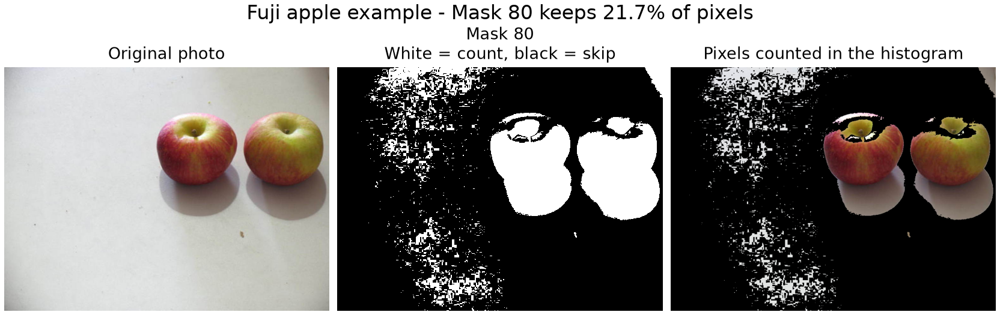

White pixels in the middle panel go into the color counts. Mask 80 kept **21.7%** of this photo's pixels. It kept some table and shadow pixels and skipped some bright areas of the apples. The right panel shows the original colors of the pixels that were counted.

In [ ]:
def rgb_histogram_features(pixels):
    channel_histograms = []

    for channel in range(3):
        counts, _ = np.histogram(pixels[:, channel], bins=32, range=(0, 256))
        channel_histograms.append(counts / counts.sum())

    return np.concatenate(channel_histograms)


def background_color_distance(image):
    height, width, _ = image.shape
    corner_height = max(1, int(height * 0.10))
    corner_width = max(1, int(width * 0.10))

    corners = [
        image[:corner_height, :corner_width],
        image[:corner_height, -corner_width:],
        image[-corner_height:, :corner_width],
        image[-corner_height:, -corner_width:]
    ]
    corner_pixels = np.concatenate([corner.reshape(-1, 3) for corner in corners])
    background_color = np.median(corner_pixels, axis=0).astype(np.uint8)

    pixels = image.reshape(-1, 3).astype(np.float32)
    difference = pixels - background_color.astype(np.float32)
    return np.linalg.norm(difference, axis=1)

In [ ]:
thresholds = {"Whole image": None, "Mask 65": 65, "Mask 80": 80}
feature_rows = {name: [] for name in thresholds}
empty_mask_counts = {name: 0 for name in thresholds if thresholds[name] is not None}

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        image = np.array(source.convert("RGB"))

    pixels = image.reshape(-1, 3)
    whole_image_features = rgb_histogram_features(pixels)
    color_distance = background_color_distance(image)

    for name, threshold in thresholds.items():
        features = whole_image_features
        if threshold is not None:
            selected_pixels = pixels[color_distance > threshold]
            if len(selected_pixels) > 0:
                features = rgb_histogram_features(selected_pixels)
            else:
                empty_mask_counts[name] += 1

        feature_rows[name].append(features)

feature_tables = {name: np.array(rows) for name, rows in feature_rows.items()}
for name, X in feature_tables.items():
    print(name, "- training shape", X[is_training].shape,
          "- validation shape", X[~is_training].shape)

print("Empty masks that used the whole image:", empty_mask_counts)

Whole image - training shape (1603, 96) - validation shape (200, 96)
Mask 65 - training shape (1603, 96) - validation shape (200, 96)
Mask 80 - training shape (1603, 96) - validation shape (200, 96)
Empty masks that used the whole image: {'Mask 65': 9, 'Mask 80': 17}


### 5.3 Choose the Baseline on Validation

#### 5.3.1 Compare the Three Versions

##### Learning note – From two answers to nine

**Binary logistic regression** is like a quiz with two buttons. It could answer “apple” or “not apple.” A kiwi and a potato would both go under “not apple.” Our quiz has nine buttons, one for each food class, and each photo has one correct answer. Scikit-learn's `LogisticRegression` uses **multinomial logistic regression** for this setup.

1. **Read the photo's 96 color features.** They tell the model how common different color intensities are in the photo.
2. **Give each food a score.** During training, the model learns which color features raise or lower each food's score. It uses those weights to calculate nine scores for a new photo.
3. **Turn the scores into probabilities and pick the largest.** This conversion is called **softmax**. The nine probabilities add up to 100%.

Here is a made-up result for one photo:

| Food | Example probability |
|---|---:|
| Apple | **62%** |
| Nectarine | 18% |
| Kiwi | 10% |
| Plum | 3% |
| Potato | 2% |
| Spanish pear | 2% |
| Onion | 1% |
| Honeydew melon | 1% |
| Watermelon | 1% |

The model predicts **apple** because apple has the highest score and therefore the highest probability. When we check the prediction against the photo's actual label, we can count it as a correct guess or a mistake.

The three versions below use the same model settings and split.

**Accuracy** is the share of photos classified correctly. **Macro-F1** gives each food its own score, then averages the scores equally. Each food's F1 balances how many of its photos we find and how often guesses of that food are right. We use macro-F1 as our main selection metric because the app predicts one food and we want all nine classes to count equally.

**ROC-AUC** measures how well the model ranks photos. For example, kiwi's AUC measures how often an actual kiwi photo gets a higher kiwi probability than a photo of another food, with ties counted as half. We repeat that comparison for each food against the other eight, then average all nine scores equally. This is **macro one-vs-rest ROC-AUC**. We report it alongside accuracy and macro-F1. A true onion can get a higher onion probability than most other photos, which helps AUC, while potato still gets the top probability for that photo, which hurts onion F1.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def macro_ovr_auc(model, features, actual_labels):
    """Average one-vs-rest ROC-AUC across the model's food classes."""
    probabilities = model.predict_proba(features)
    return roc_auc_score(
        actual_labels, probabilities, labels=model.classes_,
        multi_class="ovr", average="macro"
    )

validation_results = []
validation_predictions = {}
for name, X in feature_tables.items():
    X_train = X[is_training]
    y_train = labels[is_training]
    X_validation = X[~is_training]
    y_validation = labels[~is_training]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)
    validation_predictions[name] = predictions

    validation_results.append({
        "Image preparation": name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Macro-F1": f1_score(y_validation, predictions, average="macro", zero_division=0),
        "ROC-AUC": macro_ovr_auc(model, X_validation, y_validation)
    })

validation_scores = pd.DataFrame(validation_results)
display(validation_scores.round(4))

,Image preparation,Accuracy,Macro-F1,ROC-AUC
0,Whole image,0.715,0.5795,0.9237
1,Mask 65,0.730,0.6401,0.9392
2,Mask 80,0.720,0.6648,0.9419


#### 5.3.2 See Which Foods the Masks Confuse

A confusion matrix is a tally sheet. Pick the actual food on the left and read across to see the guesses. An onion guessed as potato adds one tally to the onion row and potato column. The diagonal shows correct guesses. The two charts share the same class order and color scale.

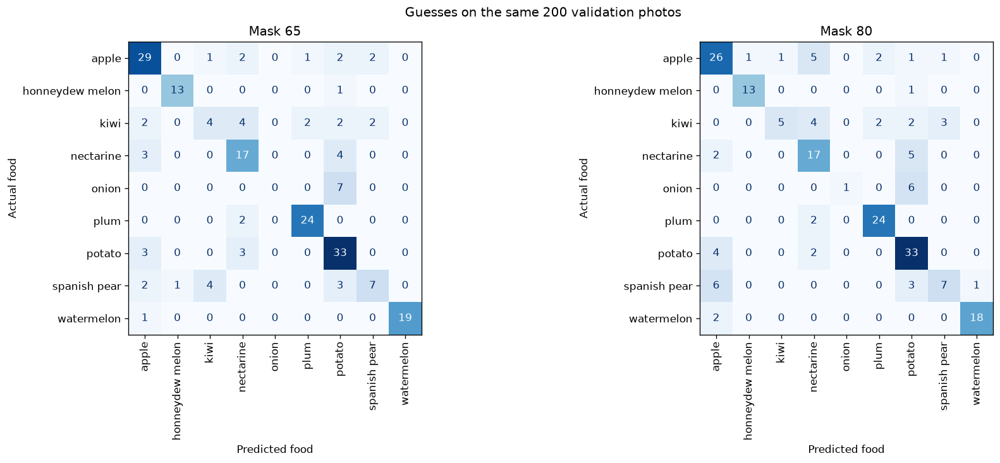

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

mask_names = ["Mask 65", "Mask 80"]
class_names = sorted(set(y_validation))
display_names = [name.replace("_", " ") for name in class_names]
confusion_counts = {}

for name in mask_names:
    confusion_counts[name] = confusion_matrix(
        y_validation, validation_predictions[name], labels=class_names
    )

max_count = max(matrix.max() for matrix in confusion_counts.values())
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

for name, ax in zip(mask_names, axes):
    matrix_plot = ConfusionMatrixDisplay(
        confusion_counts[name], display_labels=display_names
    )
    matrix_plot.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90)
    matrix_plot.im_.set_clim(0, max_count)
    ax.set_title(name)
    ax.set_xlabel("Predicted food")
    ax.set_ylabel("Actual food")

fig.suptitle("Guesses on the same 200 validation photos")
plt.show()
plt.close(fig)

The table shows each food's F1 and how many validation photos it had. The last column gives the change from Mask 65 to Mask 80.

In [ ]:
per_class_scores = pd.DataFrame({
    "Food": display_names,
    "Validation photos": confusion_counts["Mask 65"].sum(axis=1)
})

for name in mask_names:
    per_class_scores[f"F1 {name}"] = f1_score(
        y_validation,
        validation_predictions[name],
        labels=class_names,
        average=None,
        zero_division=0
    )

per_class_scores["F1 change (80 minus 65)"] = (
    per_class_scores["F1 Mask 80"] - per_class_scores["F1 Mask 65"]
)
display(per_class_scores.round(3))

,Food,Validation photos,F1 Mask 65,F1 Mask 80,F1 change (80 minus 65)
0,apple,37,0.753,0.675,-0.078
1,honneydew melon,14,0.929,0.929,0.000
2,kiwi,16,0.320,0.455,0.135
3,nectarine,24,0.654,0.630,-0.024
4,onion,7,0.000,0.250,0.250
5,plum,26,0.906,0.889,-0.017
6,potato,39,0.725,0.733,0.008
7,spanish pear,17,0.500,0.500,0.000
8,watermelon,20,0.974,0.923,-0.051


##### First Choice – Mask 80

Mask 65 got **146 of 200** photos right. Mask 80 got **144** right and had the higher macro-F1, **0.665 versus 0.640**. Its biggest F1 gains were on onion and kiwi. Mask 80 correctly identified one of the seven onion photos, which raised onion's F1 from 0 to 0.250. Apple F1 fell from 0.753 to 0.675.

We selected **Mask 80 with all 96 features and default weights** using validation macro-F1. The difference is small and the onion result rests on seven photos. That gives us a reason to check the comparison across more folds.

Validation ROC-AUC was **0.924** for the whole image, **0.939** for Mask 65, and **0.942** for Mask 80.

#### 5.3.3 Does the Mask Choice Hold Up Across Folds?

##### Learning note – Take turns being the trial exam

We divide the 1,603 training photos into five folds with similar food proportions. We train on four folds and score on the fifth, then rotate. Each photo gets one turn as an unseen example. All six settings use the same folds. The mean macro-F1 summarizes the five scores. The standard deviation shows how much the scores varied between folds.

We compare whole-image, Mask 65, and Mask 80 histograms with default and balanced class weights. Balanced weights give mistakes on rarer foods more influence during fitting. The weights are calculated from the four fitting folds each time. The per-food table combines the held-out guesses from all five folds for Mask 80, so we can see which foods gained or lost F1 when weights changed.

The tables also show mean ROC-AUC and its standard deviation across the five held-out folds. We calculate AUC separately within each fold using its fitted model and held-out probabilities.

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from src.evaluate import evaluate_predictions

review_rows = experiment_rows.loc[is_training]
review_labels = labels[is_training]
review_class_names = sorted(split_table["target_class"].unique())
review_features = {name: table[is_training] for name, table in feature_tables.items()}
review_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
review_folds = list(review_splitter.split(review_features["Mask 80"], review_labels))


def score_review_folds(estimator, features, folds):
    fold_scores = []
    held_out_guesses = np.empty_like(review_labels)

    for fit_indices, score_indices in folds:
        fold_model = clone(estimator)
        fold_model.fit(features[fit_indices], review_labels[fit_indices])
        guesses = fold_model.predict(features[score_indices])
        held_out_guesses[score_indices] = guesses

        scores = evaluate_predictions(review_labels[score_indices], guesses, review_class_names)
        auc = macro_ovr_auc(fold_model, features[score_indices], review_labels[score_indices])
        fold_scores.append([scores["accuracy"], scores["macro_f1"], auc])

    return np.array(fold_scores), held_out_guesses


weight_options = {"Default": None, "Balanced": "balanced"}
review_results = []
review_guesses = {}
for name, features in review_features.items():
    for weight_name, class_weight in weight_options.items():
        review_model = LogisticRegression(max_iter=1000, class_weight=class_weight)
        fold_scores, guesses = score_review_folds(review_model, features, review_folds)
        review_guesses[(name, weight_name)] = guesses
        onion_f1 = f1_score(review_labels, guesses, labels=["onion"], average=None, zero_division=0)[0]
        review_results.append({
            "Image preparation": name,
            "Class weights": weight_name,
            "Mean accuracy": fold_scores[:, 0].mean(),
            "Mean macro-F1": fold_scores[:, 1].mean(),
            "Macro-F1 SD": fold_scores[:, 1].std(ddof=1),
            "Mean ROC-AUC": fold_scores[:, 2].mean(),
            "ROC-AUC SD": fold_scores[:, 2].std(ddof=1),
            "Onion F1 (pooled)": onion_f1
        })

review_comparison = pd.DataFrame(review_results).sort_values("Mean macro-F1", ascending=False)
display(review_comparison.round(3).reset_index(drop=True))

mask_80_class_f1 = pd.DataFrame({"Food": review_class_names})
for weight_name in weight_options:
    mask_80_class_f1[f"F1 {weight_name}"] = f1_score(
        review_labels, review_guesses[("Mask 80", weight_name)],
        labels=review_class_names, average=None, zero_division=0
    )
display(mask_80_class_f1.round(3))

,Image preparation,Class weights,Mean accuracy,Mean macro-F1,Macro-F1 SD,Mean ROC-AUC,ROC-AUC SD,Onion F1 (pooled)
0,Mask 65,Balanced,0.664,0.657,0.010,0.945,0.005,0.502
1,Mask 80,Balanced,0.662,0.654,0.015,0.943,0.003,0.550
2,Mask 80,Default,0.728,0.643,0.024,0.945,0.004,0.125
3,Whole image,Balanced,0.673,0.641,0.037,0.932,0.012,0.546
4,Mask 65,Default,0.725,0.639,0.017,0.947,0.006,0.000
5,Whole image,Default,0.669,0.544,0.031,0.933,0.011,0.000


,Food,F1 Default,F1 Balanced
0,apple,0.742,0.462
1,honneydew_melon,0.832,0.810
2,kiwi,0.385,0.441
3,nectarine,0.671,0.628
4,onion,0.125,0.550
5,plum,0.885,0.868
6,potato,0.755,0.642
7,spanish_pear,0.538,0.595
8,watermelon,0.863,0.887


**What changed across folds.** With default weights, Mask 65 and Mask 80 were close in mean macro-F1 (**0.639** and **0.643**). Balancing weights raised Mask 80's pooled onion F1 from **0.125 to 0.550**. Across all six settings, balanced Mask 65 had the highest mean macro-F1 (**0.657**) and default-weight Mask 65 had the highest mean ROC-AUC (**0.947**). The gap between the two balanced masks was small relative to their variation across folds.

The group comparison keeps the original default-weight Mask 80 baseline from Section 5.3.2. The fold results show how much the choice can depend on weighting and the metric.

#### 5.3.4 Which Colors Drive the Predictions?

##### Learning note – See what pushes each food's score up or down

Each row is a food and each square is one color-intensity bucket. A positive coefficient pushes that food's score up as the bucket's share increases. A negative coefficient pushes it down. For example, a positive weight for a bright green bucket would mean that bucket supports the model's score for the food. The heatmap shows what the model actually learned from these photos.

For the heatmap, we fit Mask 65 with balanced weights on all training photos. It had the highest mean macro-F1 in the fold comparison above. The color buckets work together. A strong coefficient can reflect the food, the background, or the lighting in the training photos.

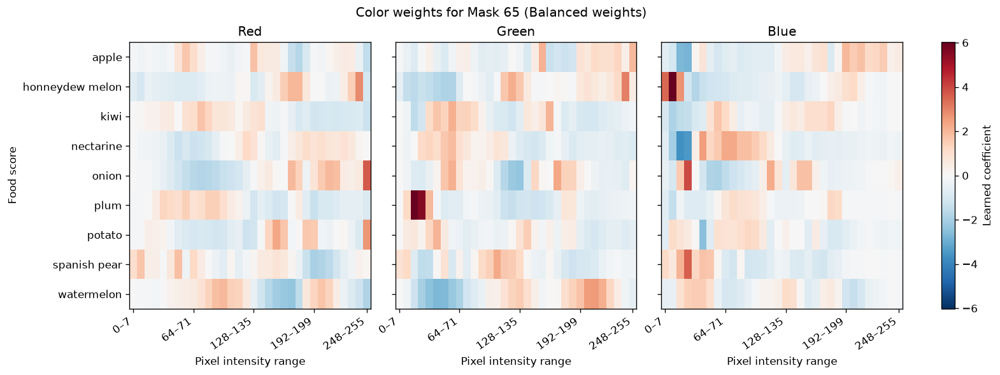

,Food,Strongest positive channel,Intensity range,Coefficient
0,apple,Green,152–159,2.080
1,onion,Blue,24–31,3.968


In [ ]:
import matplotlib.pyplot as plt

best_review = review_comparison.iloc[0]
interpretation_features = review_features[best_review["Image preparation"]]
interpretation_model = LogisticRegression(
    max_iter=1000, class_weight=weight_options[best_review["Class weights"]]
)
interpretation_model.fit(interpretation_features, review_labels)
weights = interpretation_model.coef_
weight_limit = np.abs(weights).max()
channels = ["Red", "Green", "Blue"]
bin_ticks = [0, 8, 16, 24, 31]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True, layout="constrained")

for channel_index, (channel, ax) in enumerate(zip(channels, axes)):
    start = 32 * channel_index
    image = ax.imshow(weights[:, start:start + 32], cmap="RdBu_r", aspect="auto",
                      vmin=-weight_limit, vmax=weight_limit)
    ax.set_title(channel)
    ax.set_xticks(bin_ticks, [f"{8 * b}–{8 * b + 7}" for b in bin_ticks], rotation=35, ha="right")
    ax.set_xlabel("Pixel intensity range")
    ax.set_yticks(range(len(interpretation_model.classes_)),
                  [name.replace("_", " ") for name in interpretation_model.classes_])

axes[0].set_ylabel("Food score")
fig.colorbar(image, ax=axes, label="Learned coefficient")
fig.suptitle(f"Color weights for {best_review['Image preparation']} ({best_review['Class weights']} weights)")
plt.show()
plt.close(fig)

weight_examples = []
for food in ["apple", "onion"]:
    row = list(interpretation_model.classes_).index(food)
    feature = weights[row].argmax()
    channel, color_bin = divmod(feature, 32)
    weight_examples.append({
        "Food": food,
        "Strongest positive channel": channels[channel],
        "Intensity range": f"{8 * color_bin}–{8 * color_bin + 7}",
        "Coefficient": weights[row, feature]
    })
display(pd.DataFrame(weight_examples).round(3))

**Reading the heatmap.** For apple, the strongest positive coefficient was in the **green 152–159** bucket. For onion, it was in the **blue 24–31** bucket. The model learned those patterns from the photos. The corner experiment in Section 5.6 checks whether the photo setup could also be carrying some of the color signal.

### 5.4 Can PCA Shorten the Color Description?

PCA combines the 96 color columns into fewer columns called **principal components**. Imagine several color buckets that tend to rise and fall together. One combined number can capture much of that shared pattern. Each row still represents the same photo.

We fit PCA on training features and keep enough components to explain at least 95% of their variation. Then we apply those same combinations to validation features. The table shows what happened to the rows and columns.

In [ ]:
from sklearn.decomposition import PCA

mask_80_features = feature_tables["Mask 80"]
X_train_mask_80 = mask_80_features[is_training]
X_validation_mask_80 = mask_80_features[~is_training]
y_train_mask_80 = labels[is_training]
y_validation_mask_80 = labels[~is_training]

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_mask_80)
X_validation_pca = pca.transform(X_validation_mask_80)

shape_comparison = pd.DataFrame([
    {
        "Split": "Training",
        "Photos": X_train_mask_80.shape[0],
        "Columns before PCA": X_train_mask_80.shape[1],
        "Columns after PCA": X_train_pca.shape[1]
    },
    {
        "Split": "Validation",
        "Photos": X_validation_mask_80.shape[0],
        "Columns before PCA": X_validation_mask_80.shape[1],
        "Columns after PCA": X_validation_pca.shape[1]
    }
])
display(shape_comparison)
print(f"Training variation explained: {pca.explained_variance_ratio_.sum():.1%}")

Training variation explained: 95.2%


,Split,Photos,Columns before PCA,Columns after PCA
0,Training,1603,96,33
1,Validation,200,96,33


We fit logistic regression with the same settings on the shorter description and compare it with the original Mask 80 validation result.

In [ ]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

pca_model = LogisticRegression(max_iter=1000)
pca_model.fit(X_train_pca, y_train_mask_80)
pca_validation_predictions = pca_model.predict(X_validation_pca)

pca_class_names = sorted(split_table["target_class"].unique())
pca_validation_scores = evaluate_predictions(
    y_validation_mask_80, pca_validation_predictions, pca_class_names
)

mask_80_score = validation_scores.loc[
    validation_scores["Image preparation"].eq("Mask 80")
].iloc[0]

pca_comparison = pd.DataFrame([
    {
        "Version": "Mask 80",
        "Features per photo": X_train_mask_80.shape[1],
        "Validation accuracy": mask_80_score["Accuracy"],
        "Validation macro-F1": mask_80_score["Macro-F1"],
        "Validation ROC-AUC": mask_80_score["ROC-AUC"]
    },
    {
        "Version": "Mask 80 + PCA",
        "Features per photo": X_train_pca.shape[1],
        "Validation accuracy": pca_validation_scores["accuracy"],
        "Validation macro-F1": pca_validation_scores["macro_f1"],
        "Validation ROC-AUC": macro_ovr_auc(pca_model, X_validation_pca, y_validation_mask_80)
    }
])
display(pca_comparison.round(4))

,Version,Features per photo,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Mask 80,96,0.72,0.6648,0.9419
1,Mask 80 + PCA,33,0.69,0.6360,0.9368


**Result.** PCA kept **33 of 96 columns**, explaining **95.2%** of the training feature variation. Validation accuracy fell from **72.0% to 69.0%** and macro-F1 fell from **0.665 to 0.636**. ROC-AUC also fell from **0.9419 to 0.9368**. We kept all 96 features for the baseline.

#### 5.4.1 Explore the Color Histograms in Two Dimensions

Can we see any grouping by food class using color alone? We used the 96 whole-image RGB histogram values from each of the 1,603 training photos. We standardized each histogram column, then used PCA to turn those 96 numbers into two coordinates, PC1 and PC2. Each dot is one photo. We added the actual food class afterward to color the dots.

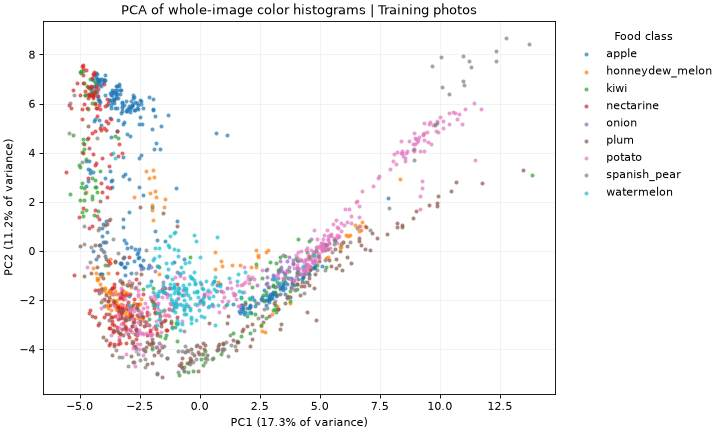

Some apples cluster in the upper left, and many potatoes extend to the right. Several classes overlap in the middle. Together, the two axes capture **28.6%** of the variation in the standardized histograms, so we see only part of how the photos differ. The experiment above uses 33 components to evaluate classification, while this plot uses two components to explore the data.

##### Recreate the plot

Run Sections 5.1 and 5.2 first to load the split and build the histograms. Then run the cell below.

1. **Choose the rows.** `feature_tables["Whole image"][is_training]` selects the histogram rows for the training photos. The food names are kept in a separate list.
2. **Turn 96 numbers into two.** `StandardScaler` puts the histogram columns on a comparable scale. PCA combines them into two coordinates per photo, like an x and y position on a map.
3. **Draw the dots.** The table pairs each photo's coordinates with its food name. The plot uses that name to choose the dot's color. The percentages on the axes show how much of the variation each coordinate captures.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Use the whole-image color histograms already calculated in Section 5.2.
pca_histograms = feature_tables["Whole image"][is_training]
pca_food_labels = labels[is_training]

scaled_histograms = StandardScaler().fit_transform(pca_histograms)
plot_pca = PCA(n_components=2)
coordinates = plot_pca.fit_transform(scaled_histograms)

pca_points = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
pca_points["Food class"] = pca_food_labels

pca_figure, pca_axis = plt.subplots(figsize=(9, 5.4), layout="constrained")
pca_palette = plt.get_cmap("tab20")
color_indices = [0, 2, 4, 6, 8, 10, 12, 14, 18]

for (food, points), color_index in zip(pca_points.groupby("Food class"), color_indices):
    pca_axis.scatter(
        points["PC1"], points["PC2"], color=pca_palette(color_index),
        s=13, alpha=0.7, linewidths=0, label=food
    )

pc1_variation, pc2_variation = plot_pca.explained_variance_ratio_
pca_axis.set_title("PCA of whole-image color histograms | Training photos")
pca_axis.set_xlabel(f"PC1 ({pc1_variation:.1%} of variance)")
pca_axis.set_ylabel(f"PC2 ({pc2_variation:.1%} of variance)")
pca_axis.legend(title="Food class", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
pca_axis.grid(alpha=0.17)
pca_axis.set_axisbelow(True)
plt.show()
plt.close(pca_figure)

### 5.5 Where Does Cropping Help?

#### 5.5.1 Crop First, Then Resize

A crop keeps a rectangle from the photo. We estimate the background from the original corners, find pixels that differ from it, and draw a box around those pixels with a 32-pixel margin. A background speck can make the box too wide, and food close to the background color can be missed.

We compare **whole photo → resize** with **crop → resize**. Both versions fit within **64 × 48 pixels** and keep their proportions. The histogram counts all pixels in the resized result, which gives 96 features even when one crop is narrower than another. The previews show training photos.

In [ ]:
background_threshold = 50
corner_size = 40
crop_margin = 32

def estimate_crop_box(image, threshold, corner_size, margin):
    pixels = np.asarray(image, dtype="float32")

    top_left = pixels[:corner_size, :corner_size]
    top_right = pixels[:corner_size, -corner_size:]
    bottom_left = pixels[-corner_size:, :corner_size]
    bottom_right = pixels[-corner_size:, -corner_size:]

    corner_pixels = np.concatenate([
        top_left.reshape(-1, 3),
        top_right.reshape(-1, 3),
        bottom_left.reshape(-1, 3),
        bottom_right.reshape(-1, 3)
    ])
    background_color = np.median(corner_pixels, axis=0)

    color_difference = np.abs(pixels - background_color)
    largest_difference = color_difference.max(axis=2)
    foreground_mask = largest_difference > threshold

    row_positions, column_positions = np.where(foreground_mask)

    if len(column_positions) == 0:
        crop_box = (0, 0, image.width, image.height)
    else:
        left = max(0, int(column_positions.min()) - margin)
        top = max(0, int(row_positions.min()) - margin)
        right = min(image.width, int(column_positions.max()) + 1 + margin)
        bottom = min(image.height, int(row_positions.max()) + 1 + margin)
        crop_box = (left, top, right, bottom)

    return crop_box, foreground_mask, background_color

data/raw_images/fuji_apple/fuji_apple_001.jpg
data/raw_images/kiwi/kiwi_001.jpg
data/raw_images/plum/plum_002.jpg


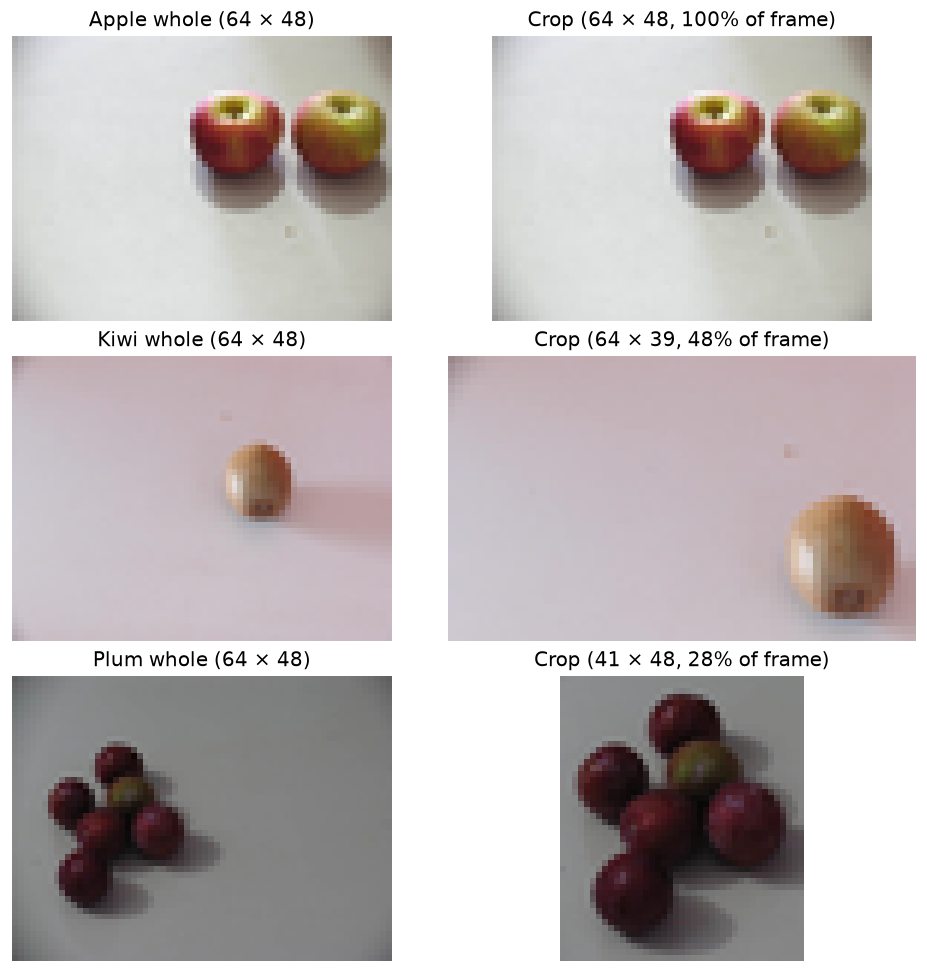

In [ ]:
from PIL import ImageOps
import matplotlib.pyplot as plt

crop_resize_limit = (64, 48)


def resize_for_crop_experiment(photo):
    return ImageOps.contain(photo, crop_resize_limit, Image.Resampling.LANCZOS)


def crop_for_experiment(photo):
    box, _, _ = estimate_crop_box(
        photo, threshold=background_threshold, corner_size=corner_size, margin=crop_margin
    )
    return photo.crop(box), box


training_examples = experiment_rows[experiment_rows["split"].eq("train")]
fig, axes = plt.subplots(3, 2, figsize=(8, 8), layout="constrained")
for row, food in enumerate(["apple", "kiwi", "plum"]):
    crop_preview_path = training_examples.loc[
        training_examples["target_class"].eq(food), "image_path"
    ].iloc[0]
    with Image.open(project_folder / crop_preview_path) as source:
        original_photo = source.convert("RGB")

    crop_preview, _ = crop_for_experiment(original_photo)
    whole_small = resize_for_crop_experiment(original_photo)
    crop_small = resize_for_crop_experiment(crop_preview)
    crop_share = (crop_preview.width * crop_preview.height) / (original_photo.width * original_photo.height)
    for ax, preview in zip(axes[row], [whole_small, crop_small]):
        ax.imshow(preview, interpolation="nearest")
        ax.axis("off")
    axes[row, 0].set_title(f"{food.title()} whole ({whole_small.width} × {whole_small.height})")
    axes[row, 1].set_title(f"Crop ({crop_small.width} × {crop_small.height}, {crop_share:.0%} of frame)")
    print(crop_preview_path)

plt.show()
plt.close(fig)

Both versions use the same training and validation photos. A crop that keeps the full frame gives identical features to the resized whole photo. Compare the first two rows of the score table to see what adding the crop changed. Mask 80 serves as a reference and used original-resolution pixels.

In [ ]:
whole_resize_rows = []
crop_resize_rows = []
full_frame_crops = []

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        photo = source.convert("RGB")

    cropped_photo, box = crop_for_experiment(photo)
    full_frame_crops.append(box == (0, 0, photo.width, photo.height))
    whole_pixels = np.asarray(resize_for_crop_experiment(photo)).reshape(-1, 3)
    crop_pixels = np.asarray(resize_for_crop_experiment(cropped_photo)).reshape(-1, 3)
    whole_resize_rows.append(rgb_histogram_features(whole_pixels))
    crop_resize_rows.append(rgb_histogram_features(crop_pixels))

resize_feature_tables = {
    "Whole image → resize": np.array(whole_resize_rows),
    "Crop → resize": np.array(crop_resize_rows)
}
full_frame_crops = np.array(full_frame_crops)
print("Feature table shape for each version:", resize_feature_tables["Crop → resize"].shape)
print("Full-frame crops in training:", full_frame_crops[is_training].sum(), "of", is_training.sum())
print("Full-frame crops in validation:", full_frame_crops[~is_training].sum(), "of", (~is_training).sum())

Feature table shape for each version: (1803, 96)
Full-frame crops in training: 518 of 1603
Full-frame crops in validation: 71 of 200


In [ ]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

resize_class_names = sorted(split_table["target_class"].unique())
resize_results = []
for name, features in resize_feature_tables.items():
    resize_model = LogisticRegression(max_iter=1000)
    resize_model.fit(features[is_training], labels[is_training])
    resize_predictions = resize_model.predict(features[~is_training])
    resize_scores = evaluate_predictions(labels[~is_training], resize_predictions, resize_class_names)
    resize_results.append({
        "Image preparation": name,
        "Validation accuracy": resize_scores["accuracy"],
        "Validation macro-F1": resize_scores["macro_f1"],
        "Validation ROC-AUC": macro_ovr_auc(resize_model, features[~is_training], labels[~is_training])
    })

mask_reference = validation_scores.loc[validation_scores["Image preparation"].eq("Mask 80")].iloc[0]
resize_results.append({
    "Image preparation": "Mask 80 (reference)",
    "Validation accuracy": mask_reference["Accuracy"],
    "Validation macro-F1": mask_reference["Macro-F1"],
    "Validation ROC-AUC": mask_reference["ROC-AUC"]
})
resize_comparison = pd.DataFrame(resize_results)
display(resize_comparison.round(4))

,Image preparation,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Whole image → resize,0.725,0.6009,0.9240
1,Crop → resize,0.695,0.5704,0.9346
2,Mask 80 (reference),0.720,0.6648,0.9419


**Result.** Adding the crop lowered validation accuracy from **72.5% to 69.5%** and macro-F1 from **0.601 to 0.570**. The crop kept the full frame for **71 of 200** validation photos. ROC-AUC rose from **0.9240 to 0.9346**. The two metrics tell different stories: ranking improved, while the final food guesses scored worse. Mask 80 still had the highest macro-F1 and ROC-AUC in this table.

#### 5.5.2 Mask 80 First, Then Crop and Resize

We start with the Mask 80 rule on the original photo. Then we crop to the smallest rectangle containing every kept pixel. At that point the histogram would stay the same, because the crop keeps every pixel that already counted.

##### Learning note – Shrink the photo and its stencil together

We resize the crop to fit within **64 × 48 pixels** and resize its mask to the exact same dimensions. Nearest-neighbor resizing copies a source pixel and its mask decision together. This keeps the kept and skipped pixels aligned and avoids blending skipped colors into the kept ones. We count only resized pixels marked as kept. Some kept pixels can disappear when the photo is made smaller.

If Mask 80 keeps zero pixels in the original photo, we use the whole-image histogram, as in Section 5.2. If resizing leaves zero kept pixels, we use the original Mask 80 histogram for that photo. The output counts both cases.

Both models use the same 1,603 training photos, 200 validation photos, and logistic regression settings. The Mask 80 row comes from Section 5.3. A crop around the kept pixels retains them all before resizing, so any change in the histogram comes from resizing within that crop.

In [ ]:
from PIL import ImageOps
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

mask_crop_limit = (64, 48)


def mask_crop_resize_features(photo):
    original_pixels = np.asarray(photo)
    kept = background_color_distance(original_pixels).reshape(photo.height, photo.width) > 80
    pixel_mask = Image.fromarray(kept)
    crop_box = pixel_mask.getbbox()
    if crop_box is None:
        return rgb_histogram_features(original_pixels.reshape(-1, 3)), "Empty original mask"

    small_photo = ImageOps.contain(photo.crop(crop_box), mask_crop_limit, Image.Resampling.NEAREST)
    small_mask = pixel_mask.crop(crop_box).resize(small_photo.size, Image.Resampling.NEAREST)
    small_kept = np.asarray(small_mask, dtype=bool)
    selected_pixels = np.asarray(small_photo)[small_kept]
    if len(selected_pixels) == 0:
        return rgb_histogram_features(original_pixels[kept]), "Empty resized mask"

    return rgb_histogram_features(selected_pixels), "No fallback"


mask_crop_rows = []
mask_crop_fallbacks = []
for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        mask_crop_photo = source.convert("RGB")

    features, fallback = mask_crop_resize_features(mask_crop_photo)
    mask_crop_rows.append(features)
    mask_crop_fallbacks.append(fallback)

mask_crop_table = np.array(mask_crop_rows)
mask_crop_fallbacks = np.array(mask_crop_fallbacks)
print("Feature table shape:", mask_crop_table.shape)
for reason in ["Empty original mask", "Empty resized mask"]:
    fallback_rows = mask_crop_fallbacks == reason
    print(reason, "- training:", fallback_rows[is_training].sum(),
          "- validation:", fallback_rows[~is_training].sum())

Feature table shape: (1803, 96)
Empty original mask - training: 15 - validation: 2
Empty resized mask - training: 0 - validation: 0


In [ ]:
mask_crop_model = LogisticRegression(max_iter=1000)
mask_crop_model.fit(mask_crop_table[is_training], labels[is_training])
mask_crop_validation_features = mask_crop_table[~is_training]
mask_crop_labels = labels[~is_training]
mask_crop_guesses = mask_crop_model.predict(mask_crop_validation_features)
mask_crop_class_names = sorted(split_table["target_class"].unique())
mask_crop_scores = evaluate_predictions(mask_crop_labels, mask_crop_guesses, mask_crop_class_names)
mask_crop_auc = macro_ovr_auc(mask_crop_model, mask_crop_validation_features, mask_crop_labels)

original_mask_80 = validation_scores.loc[validation_scores["Image preparation"].eq("Mask 80")].iloc[0]
mask_crop_comparison = pd.DataFrame([
    {
        "Image preparation": "Mask 80",
        "Validation accuracy": original_mask_80["Accuracy"],
        "Validation macro-F1": original_mask_80["Macro-F1"],
        "Validation ROC-AUC": original_mask_80["ROC-AUC"]
    },
    {
        "Image preparation": "Mask 80 → crop → resize",
        "Validation accuracy": mask_crop_scores["accuracy"],
        "Validation macro-F1": mask_crop_scores["macro_f1"],
        "Validation ROC-AUC": mask_crop_auc
    }
])
display(mask_crop_comparison.round(4))

,Image preparation,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Mask 80,0.72,0.6648,0.9419
1,Mask 80 → crop → resize,0.72,0.6658,0.9398


**Result.** Both versions correctly classified **144 of 200** validation photos. Adding crop and resize moved macro-F1 from **0.6648 to 0.6658** and ROC-AUC from **0.9419 to 0.9398**. The differences are small on this split. We keep the original Mask 80 as the baseline.

### 5.6 Check for Background and Capture-Time Shortcuts

The histogram can capture colors from the food or its surroundings. Before reading the test score, we check how much information is in the corners and how much performance changes when nearby capture times stay together.

##### Learning note – Try changing what the model gets to see

**Corners only.** We build a histogram from the four corner patches and compare a classifier with a dummy model that guesses using the training class frequencies. If the corner model does better, the corners contain information about the labels. The patches can contain food as well as background, so this is evidence of a possible shortcut.

**Random folds versus capture-time groups.** We score the same balanced Mask 80 model two ways. The first uses the random stratified folds from Section 5.3.3. The second keeps all photos from each five-minute capture interval in one fold, following the grouping explored in EDA. The intervals approximate photography sessions. A score change shows how sensitive our results are to which photos stay together.

In [ ]:
from datetime import datetime
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold

corner_rows = []
capture_groups = []
for image_path in review_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        exif = source.getexif()
        capture_value = exif.get(36867) or exif.get_ifd(0x8769).get(36867)
        photo = np.asarray(source.convert("RGB"))

    if capture_value is None:
        raise ValueError(f"Missing EXIF capture time for {image_path}")
    capture_time = datetime.strptime(str(capture_value), "%Y:%m:%d %H:%M:%S")
    five_minute_start = capture_time.replace(minute=(capture_time.minute // 5) * 5, second=0)
    capture_groups.append(five_minute_start.isoformat())

    height, width, _ = photo.shape
    corner_height = max(1, int(height * 0.10))
    corner_width = max(1, int(width * 0.10))
    corners = [photo[:corner_height, :corner_width], photo[:corner_height, -corner_width:],
               photo[-corner_height:, :corner_width], photo[-corner_height:, -corner_width:]]
    corner_pixels = np.concatenate([corner.reshape(-1, 3) for corner in corners])
    corner_rows.append(rgb_histogram_features(corner_pixels))

corner_features = np.array(corner_rows)
capture_groups = np.array(capture_groups)
mask_80_training = review_features["Mask 80"]
group_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
group_folds = list(group_splitter.split(mask_80_training, review_labels, capture_groups))

print("Five-minute training groups:", len(set(capture_groups)))
for number, (fit_indices, score_indices) in enumerate(group_folds, start=1):
    shared_groups = set(capture_groups[fit_indices]) & set(capture_groups[score_indices])
    held_out_classes = set(review_labels[score_indices])
    assert not shared_groups
    assert held_out_classes == set(review_class_names)
    print(f"Grouped fold {number}: {len(score_indices)} photos, {len(held_out_classes)} foods")

balanced_model = LogisticRegression(max_iter=1000, class_weight="balanced")
shortcut_checks = [
    ("Guess from class frequencies", DummyClassifier(strategy="stratified", random_state=42), corner_features, review_folds),
    ("Corners only, random folds", balanced_model, corner_features, review_folds),
    ("Mask 80, random folds", balanced_model, mask_80_training, review_folds),
    ("Mask 80, grouped folds", balanced_model, mask_80_training, group_folds)
]
shortcut_results = []
for name, estimator, features, folds in shortcut_checks:
    fold_scores, _ = score_review_folds(estimator, features, folds)
    shortcut_results.append({
        "Check": name,
        "Mean macro-F1": fold_scores[:, 1].mean(),
        "Macro-F1 SD": fold_scores[:, 1].std(ddof=1),
        "Mean ROC-AUC": fold_scores[:, 2].mean(),
        "ROC-AUC SD": fold_scores[:, 2].std(ddof=1)
    })
shortcut_comparison = pd.DataFrame(shortcut_results)
display(shortcut_comparison.round(3))

Five-minute training groups: 104
Grouped fold 1: 313 photos, 9 foods
Grouped fold 2: 323 photos, 9 foods
Grouped fold 3: 321 photos, 9 foods
Grouped fold 4: 323 photos, 9 foods
Grouped fold 5: 323 photos, 9 foods


,Check,Mean macro-F1,Macro-F1 SD,Mean ROC-AUC,ROC-AUC SD
0,Guess from class frequencies,0.130,0.002,0.511,0.001
1,"Corners only, random folds",0.652,0.013,0.928,0.011
2,"Mask 80, random folds",0.654,0.015,0.943,0.003
3,"Mask 80, grouped folds",0.528,0.072,0.857,0.040


**What the shortcut checks showed.** Corners alone scored **0.652 macro-F1** and **0.928 ROC-AUC**, compared with **0.130** and **0.511** for frequency-based guesses. The corners carry substantial label information, and they can contain both food and background.

Balanced Mask 80 went from **0.654 macro-F1 and 0.943 ROC-AUC** in random folds to **0.528 and 0.857** in capture-time grouped folds. The score is sensitive to which photos stay together. The five-minute intervals are approximate sessions and the grouped folds can differ in composition. Keep that limitation in mind when reading the original test result below.

### 5.7 Report the Original Baseline on Test

The test score belongs to the original Mask 80 model with default class weights chosen on validation in Section 5.3. The cross-validation and shortcut scores come from held-out folds of the training photos.

#### 5.7.1 Prepare the Reserved Photos

Each of the 200 test photos gets the same 96-feature Mask 80 preparation. A photo uses the whole-image histogram if the mask skips every pixel, just as in training and validation.

In [ ]:
def mask_80_feature_table(image_paths):
    rows = []
    empty_masks = 0

    for image_path in image_paths:
        with Image.open(project_folder / image_path) as source:
            image = np.array(source.convert("RGB"))

        pixels = image.reshape(-1, 3)
        color_distance = background_color_distance(image)
        selected_pixels = pixels[color_distance > 80]

        if len(selected_pixels) == 0:
            selected_pixels = pixels
            empty_masks += 1

        rows.append(rgb_histogram_features(selected_pixels))

    return np.array(rows), empty_masks


test_rows = split_table[split_table["split"].eq("test")]
X_test, test_empty_masks = mask_80_feature_table(test_rows["image_path"])
y_test = test_rows["target_class"].to_numpy()

print("Test feature table shape:", X_test.shape)
print("Empty test masks that used the whole image:", test_empty_masks)

Test feature table shape: (200, 96)
Empty test masks that used the whole image: 5


#### 5.7.2 Score the Guesses

The classifier fits on the 1,603 training photos and predicts labels for the 200 test photos. `evaluate_predictions()` takes the correct labels, the guesses in matching photo order, and the full class list. It returns accuracy, macro-F1, and a confusion matrix. The group can use the same function for every model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

X_final_train = feature_tables["Mask 80"][is_training]
y_final_train = labels[is_training]

final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_final_train, y_final_train)
test_predictions = final_model.predict(X_test)

test_class_names = sorted(split_table["target_class"].unique())
test_scores = evaluate_predictions(y_test, test_predictions, test_class_names)
test_accuracy = test_scores["accuracy"]
test_macro_f1 = test_scores["macro_f1"]
test_auc = macro_ovr_auc(final_model, X_test, y_test)

print("Training photos:", len(y_final_train))
print("Test photos:", len(y_test))
print("Correct test guesses:", np.count_nonzero(y_test == test_predictions))
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test macro-F1: {test_macro_f1:.3f}")
print(f"Test macro one-vs-rest ROC-AUC: {test_auc:.3f}")

Training photos: 1603
Test photos: 200
Correct test guesses: 148
Test accuracy: 74.0%
Test macro-F1: 0.652
Test macro one-vs-rest ROC-AUC: 0.940


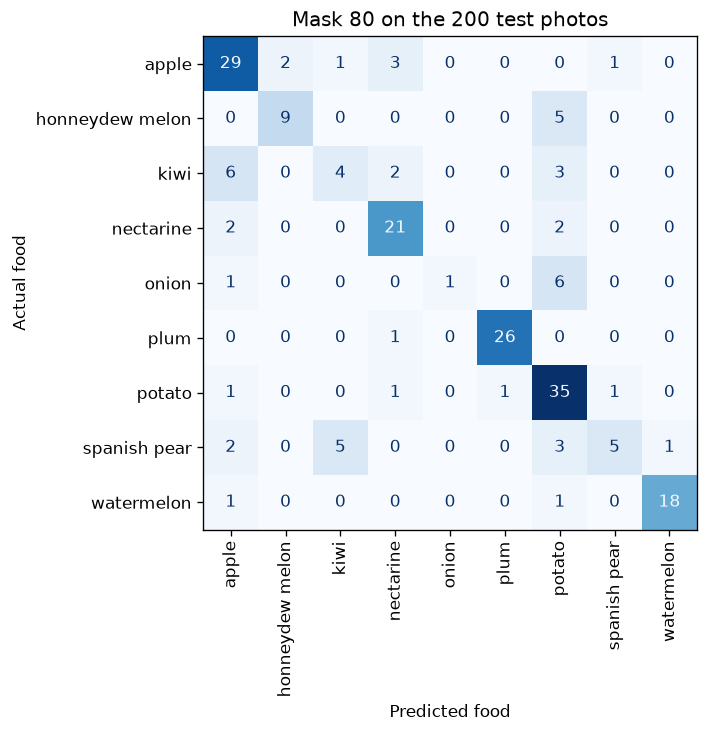

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

test_confusion = test_scores["confusion_matrix"]
test_display_names = [name.replace("_", " ") for name in test_class_names]

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ConfusionMatrixDisplay(test_confusion, display_labels=test_display_names).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90
)
ax.set_title("Mask 80 on the 200 test photos")
ax.set_xlabel("Predicted food")
ax.set_ylabel("Actual food")
plt.show()
plt.close(fig)

**Final baseline.** Mask 80 correctly classified **148 of 200** test photos, with **74.0% accuracy**, **0.652 macro-F1**, and **0.940 macro one-vs-rest ROC-AUC**. The most frequent mistake was predicting apple for **6 of 15 kiwi photos**. The split keeps identified near-duplicates in training, but related photos may still appear across splits. Photos from a different setting would give a separate check of generalization.

### 5.8 Baseline Summary

- **Selected baseline:** logistic regression on 96 color-histogram features (Mask 80, default class weights), chosen on validation macro-F1.
- **Test result:** 74.0% accuracy, 0.652 macro-F1 and 0.940 ROC-AUC on the 200 test photos.
- **What the model learned:** color buckets that push each food's score up or down. Some of that signal comes from the photo setup, since the corners alone reach almost the same macro-F1.
- **Leakage check:** keeping photos from the same capture interval together lowers macro-F1 from 0.654 to 0.528.

The test scores are stored below so that the final comparison can use them.

In [ ]:
# Keep the baseline's test scores for the model comparison later in the notebook
baseline_test_accuracy = test_accuracy
baseline_test_macro_f1 = test_macro_f1

print(f"Baseline test accuracy: {baseline_test_accuracy:.1%}")
print(f"Baseline test macro-F1: {baseline_test_macro_f1:.3f}")

## 6. Convolutional Neural Network (CNN)


#### Purpose

The purpose of this project is to build and train a Convolutional Neural Network (CNN) to classify images of nine different fruits and vegetables.

We aim to evaluate the model's classification performance and compare the results with the group's baseline model, which uses Logistic Regression.

#### Method

We use the group's existing image dataset and predefined training, validation, and test splits to ensure a consistent evaluation.

The CNN learns visual features directly from the images, such as colors, shapes, and textures, rather than relying on manually extracted features.

We train the model on the training set, monitor its performance using the validation set, and evaluate its final performance on the test set using accuracy, macro-F1 score, and a confusion matrix.

### 6.1 Load the existing train, validation and test split

We use the group's existing dataset split so that the CNN and baseline model can be evaluated on the same test images.

The CSV file contains image paths, target classes, and dataset split assignments.

Before loading the images, we inspect the dataset to verify the number of images in each split and examine the class distribution. This helps us identify potential class imbalances that could affect model performance.

In [ ]:

# Load the existing dataset split
csv_path = project_root / "data" / "dataset_split.csv"
df = pd.read_csv(csv_path)

# Display the first five rows
display(df.head())

# Check the number of images in each split
print("\nImages per split:")
print(df["split"].value_counts())

# Check the available classes
print("\nClasses:")
print(sorted(df["target_class"].unique()))

# Check the total number of images
print("\nTotal images:", len(df))

# NEW: Check the class distribution within each split
# This helps identify potential class imbalances in training, validation and test data
print("\nClass distribution per split:")
print(pd.crosstab(df["target_class"], df["split"]))


,image_path,target_class,split
0,data/raw_images/fuji_apple/fuji_apple_002.jpg,apple,test
1,data/raw_images/fuji_apple/fuji_apple_023.jpg,apple,test
2,data/raw_images/fuji_apple/fuji_apple_046.jpg,apple,test
3,data/raw_images/fuji_apple/fuji_apple_053.jpg,apple,test
4,data/raw_images/fuji_apple/fuji_apple_061.jpg,apple,test



Images per split:
split
train         1603
test           200
validation     200
Name: count, dtype: int64

Classes:
['apple', 'honneydew_melon', 'kiwi', 'nectarine', 'onion', 'plum', 'potato', 'spanish_pear', 'watermelon']

Total images: 2003

Class distribution per split:
split            test  train  validation
target_class                            
apple              36    294          37
honneydew_melon    14    117          14
kiwi               15    140          16
nectarine          25    198          24
onion               8     60           7
plum               27    211          26
potato             39    305          39
spanish_pear       16    126          17
watermelon         20    152          20


### 6.2 Load and preprocess images

We use the group's existing `load_image()` function to load and preprocess the images.

Before preparing the dataset for CNN training, we visualize six randomly selected training images to verify that they are loaded correctly and match their assigned labels.

We also inspect the dimensions and pixel value range of one loaded image to check its format.

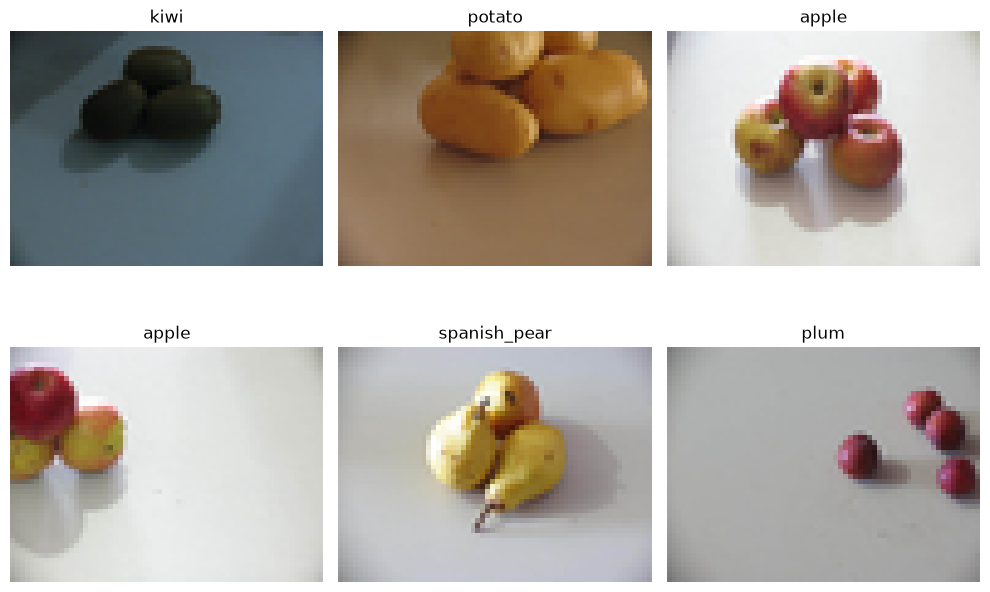

Image shape: (48, 64, 3)
Pixel range: 0.0627451 to 0.8666667


In [ ]:

# Select six images from the training dataset
train_df = df[df["split"] == "train"]
sample = train_df.sample(n=6, random_state=42)

# Display the images in a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = project_root / row["image_path"]
    image = load_image(image_path)

    ax.imshow(image)
    ax.set_title(row["target_class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Check image dimensions and pixel values
print("Image shape:", image.shape)
print("Pixel range:", image.min(), "to", image.max())


#### 6.2.1 Label encoding

We convert the fruit and vegetable class names into numerical labels (0–8), as PyTorch's classification loss function requires integer class labels.

The same class mapping is used for the training, validation, and test datasets to ensure consistent label encoding.

In [ ]:

# Get the unique class names from the training dataset and sort them alphabetically
class_names = sorted(train_df["target_class"].unique())

# Create a dictionary that maps each class name to a numerical label
# enumerate() assigns an index starting from 0 to each class name
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

# Display the number of classes and their numerical labels
print("Number of classes:", len(class_names))
print("Class mapping:", class_to_idx)


Number of classes: 9
Class mapping: {'apple': 0, 'honneydew_melon': 1, 'kiwi': 2, 'nectarine': 3, 'onion': 4, 'plum': 5, 'potato': 6, 'spanish_pear': 7, 'watermelon': 8}


#### 6.2.2 Create a PyTorch Dataset

We create a custom PyTorch Dataset using the group's existing `load_image()` function.

Each image is loaded and converted into a PyTorch tensor with the required dimensions (channels, height, width). The image is then paired with its corresponding numerical class label.

The Dataset class allows images and labels to be accessed individually during training and evaluation.

In [ ]:

# Create a custom PyTorch Dataset class
class FruitDataset(Dataset):

    # Initialize the dataset with image information and class mapping
    def __init__(self, dataframe, project_root, class_to_idx):
        self.dataframe = dataframe.reset_index(drop=True)
        self.project_root = project_root
        self.class_to_idx = class_to_idx

    # Return the total number of images in the dataset
    def __len__(self):
        return len(self.dataframe)

    # Load and return one image and its corresponding label
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        # Load the image using the group's existing function
        image_path = self.project_root / row["image_path"]
        image = load_image(image_path)

        # Convert the NumPy image into a PyTorch tensor
        # Change dimensions from (height, width, channels)
        # to (channels, height, width)
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Convert the class name into its numerical label
        label = self.class_to_idx[row["target_class"]]

        # Convert the label into a tensor of integer type
        label = torch.tensor(label, dtype=torch.long)

        # Return the image tensor and its label
        return image, label


#### 6.2.3 Create DataLoaders

We create training and validation datasets using our custom `FruitDataset` class.

PyTorch DataLoaders divide the images into batches of 32, allowing the model to process multiple images at a time.

The training data is shuffled to vary the order of images between epochs, while the validation data is kept in a fixed order for consistent evaluation.

The test dataset is reserved for the final model evaluation.

In [ ]:

# Select validation images using the group's existing dataset split
val_df = df[df["split"] == "validation"]

# Create training and validation datasets
train_dataset = FruitDataset(train_df, project_root, class_to_idx)
val_dataset = FruitDataset(val_df, project_root, class_to_idx)

# Create DataLoaders that process 32 images per batch
# Shuffle training data to vary the order between epochs
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Keep validation data in a fixed order
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Display the number of images in each dataset
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 1603
Validation images: 200


### 6.3 Build the CNN model

We build a Convolutional Neural Network (CNN) using PyTorch to classify images into nine fruit and vegetable classes.

The model consists of two convolutional layers that extract visual features from the images. Each convolutional layer is followed by a ReLU activation function and max pooling, which reduces the spatial dimensions of the feature maps.

The extracted features are flattened and passed through fully connected layers to produce a prediction score for each class.

The model outputs nine scores (logits), which are used during training to calculate the classification loss.

We also set a fixed random seed before initializing the CNN to make our training results more reproducible and allow fairer comparisons between different model settings.

In [ ]:
# Set a fixed random seed for reproducibility
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Set the seed for CUDA GPUs if available
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

print("Random seed:", seed)

Random seed: 42


In [ ]:

# Define a Convolutional Neural Network for image classification
class FruitCNN(nn.Module):

    # Initialize the model with the number of output classes
    def __init__(self, num_classes=9):
        super().__init__()

        # Extract visual features from the input images
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 3 input channels, 16 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2),                            # Reduce height and width by half

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 input channels, 32 filters
            nn.ReLU(),                                  # Introduce non-linearity
            nn.MaxPool2d(2)                             # Reduce height and width by half
        )

        # Classify the extracted image features
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # Convert feature maps into a one-dimensional vector
            nn.Linear(32 * 12 * 16, 128), # Connect extracted features to 128 neurons
            nn.ReLU(),                     # Introduce non-linearity
            nn.Linear(128, num_classes)    # Output one score for each class
        )

    # Define how data moves through the network
    def forward(self, x):
        x = self.features(x)      # Extract visual features
        x = self.classifier(x)    # Calculate class scores
        return x                 # Return the logits

# Create the CNN model using the number of available classes
model = FruitCNN(num_classes=len(class_names))

# Display the model architecture
print(model)


FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)


#### 6.3.1 Verify Model Input and Output Dimensions

Before training, we verify that the CNN accepts batches of preprocessed images and produces one prediction score per class. This helps detect potential dimension mismatches.

In [ ]:
# Get one batch of images and labels
images, labels = next(iter(train_loader))

# Display the batch dimensions and data type
print("Batch shape:", images.shape)
print("Image dtype:", images.dtype)

# Pass the batch through the CNN without calculating gradients
with torch.no_grad():
    outputs = model(images)

# Check that the model produces one score per class
print("Output shape:", outputs.shape)

Batch shape: torch.Size([32, 3, 48, 64])
Image dtype: torch.float32
Output shape: torch.Size([32, 9])


### 6.4 Configure model training

We use CrossEntropyLoss to measure the difference between the model's predicted class scores and the correct class labels.

The Adam optimizer updates the model's weights during training to minimize the loss. We use a learning rate of 0.001, which controls the size of the optimization steps.

The model automatically selects an available GPU (CUDA for NVIDIA or MPS for Apple Silicon). If GPU acceleration is unavailable, training runs on the CPU.

In [ ]:
# Select the best available device for training
if torch.cuda.is_available():
    device = torch.device("cuda")  # NVIDIA GPU, commonly used on Windows

elif torch.backends.mps.is_available():
    device = torch.device("mps")   # Apple Silicon GPU (Mac)

else:
    device = torch.device("cpu")   # Fallback for computers without supported GPU acceleration

# Move the CNN model to the selected device
model = model.to(device)

# Define the loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Define the Adam optimizer with a learning rate of 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Display the training configuration
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam


### 6.5 Train the CNN model

We train the CNN for 10 epochs using the training dataset. During each epoch, the model updates its weights using the Adam optimizer to minimize the classification loss.

After each epoch, we evaluate the model on the validation dataset without updating its weights.

We record training and validation loss and accuracy to monitor the model's learning progress and identify potential overfitting.

We also save the model with the lowest validation loss to make sure we keep the best-performing model during training.

In [ ]:
# Define the number of training epochs and where the results are saved
num_epochs = 10
best_model_path = project_root / "best_cnn_model.pth"
history_path = results_path / "cnn_history.json"

if TRAIN_CNN or not best_model_path.exists():
    # Create lists to store training and validation metrics
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    # Track the best validation loss and corresponding epoch
    best_val_loss = float("inf")
    best_epoch = 0

    # Repeat training and validation for each epoch
    for epoch in range(num_epochs):

        # --- TRAINING ---
        model.train()  # Set the model to training mode
        running_loss = 0
        correct = 0
        total = 0

        # Process one batch of training images at a time
        for images, labels in train_loader:
            images = images.to(device)  # Move images to GPU or CPU
            labels = labels.to(device)  # Move labels to the same device

            optimizer.zero_grad()  # Clear gradients from the previous batch

            outputs = model(images)  # Calculate prediction scores
            loss = criterion(outputs, labels)  # Calculate classification loss

            loss.backward()  # Calculate gradients
            optimizer.step()  # Update model weights

            # Accumulate loss, weighted by the number of images in the batch
            running_loss += loss.item() * images.size(0)

            # Count correct predictions
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        # Calculate average training loss and accuracy
        train_loss = running_loss / total
        train_accuracy = correct / total

        # --- VALIDATION ---
        model.eval()  # Set the model to evaluation mode
        running_val_loss = 0
        val_correct = 0
        val_total = 0

        # Disable gradient calculations during validation
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                # Accumulate validation loss
                running_val_loss += loss.item() * images.size(0)

                # Count correct validation predictions
                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        # Calculate average validation loss and accuracy
        val_loss = running_val_loss / val_total
        val_accuracy = val_correct / val_total

        # Save metrics for visualization
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        # Save the model if validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), best_model_path)

        # Display results after each epoch
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Train accuracy: {train_accuracy:.2%} | "
            f"Val accuracy: {val_accuracy:.2%}"
        )

    # Display the best model results
    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Best model saved to: {best_model_path}")

    # Save the training history so the plots can be recreated without retraining
    history_path.write_text(json.dumps({
        "train_losses": train_losses, "val_losses": val_losses,
        "train_accuracies": train_accuracies, "val_accuracies": val_accuracies,
        "best_epoch": best_epoch, "best_val_loss": best_val_loss
    }, indent=2))

else:
    # Load the saved model history instead of retraining (see TRAIN_CNN in the setup section)
    history = json.loads(history_path.read_text())
    train_losses = history["train_losses"]
    val_losses = history["val_losses"]
    train_accuracies = history["train_accuracies"]
    val_accuracies = history["val_accuracies"]
    best_epoch = history["best_epoch"]
    best_val_loss = history["best_val_loss"]

    print("TRAIN_CNN = False: using the saved model and training history.")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")


Epoch 1/10 | Train loss: 1.6284 | Val loss: 1.1877 | Train accuracy: 40.36% | Val accuracy: 62.00%
Epoch 2/10 | Train loss: 0.7976 | Val loss: 0.5808 | Train accuracy: 72.24% | Val accuracy: 79.50%
Epoch 3/10 | Train loss: 0.4683 | Val loss: 0.4659 | Train accuracy: 83.97% | Val accuracy: 82.50%
Epoch 4/10 | Train loss: 0.3426 | Val loss: 0.3637 | Train accuracy: 87.71% | Val accuracy: 87.50%
Epoch 5/10 | Train loss: 0.2940 | Val loss: 0.3948 | Train accuracy: 89.46% | Val accuracy: 84.00%
Epoch 6/10 | Train loss: 0.1999 | Val loss: 0.2838 | Train accuracy: 93.51% | Val accuracy: 90.50%
Epoch 7/10 | Train loss: 0.1828 | Val loss: 0.2121 | Train accuracy: 94.45% | Val accuracy: 93.50%
Epoch 8/10 | Train loss: 0.1238 | Val loss: 0.2288 | Train accuracy: 96.38% | Val accuracy: 90.50%
Epoch 9/10 | Train loss: 0.1109 | Val loss: 0.2695 | Train accuracy: 96.57% | Val accuracy: 87.50%
Epoch 10/10 | Train loss: 0.1618 | Val loss: 0.1536 | Train accuracy: 95.63% | Val accuracy: 94.00%

Best epo

### 6.6 Visualize training results

We visualize training and validation loss and accuracy across the 10 epochs.

These plots help us monitor the CNN's learning progress and identify potential signs of overfitting.

By comparing training and validation performance, we can assess how well the model generalizes to unseen validation images.

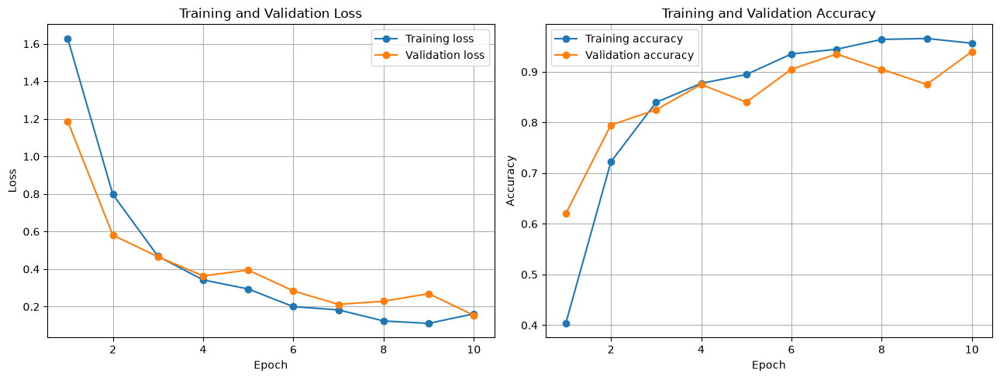

In [ ]:

# Create epoch numbers for the x-axis
epochs = range(1, num_epochs + 1)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot training and validation loss
axes[0].plot(epochs, train_losses, label="Training loss", marker="o")
axes[0].plot(epochs, val_losses, label="Validation loss", marker="o")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation accuracy
axes[1].plot(epochs, train_accuracies, label="Training accuracy", marker="o")
axes[1].plot(epochs, val_accuracies, label="Validation accuracy", marker="o")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# Adjust layout and display the plots
plt.tight_layout()
plt.show()


#### 6.6.1 Analysis of training results

Both training and validation loss decrease overall, showing that the CNN is learning to recognize the different fruit classes.

Training accuracy increases from 40.36% to 95.63%, while validation accuracy improves from 62% to 94%.

The validation curves fluctuate slightly during the later epochs, but there are no clear signs of serious overfitting.

The lowest validation loss (0.1536) is reached at epoch 10, and this model is saved for further evaluation.

Overall, the results show that the CNN performs well on the validation dataset.

### 6.7 Evaluate the CNN on validation data

We evaluate the best saved CNN model using the validation dataset.

We compare the predicted labels with the actual labels to identify which fruit and vegetable classes the model recognizes correctly and which classes it confuses.

The test dataset is reserved for final evaluation.

In [ ]:
# Load the best model saved during training
best_model = FruitCNN(num_classes=len(class_names)).to(device)
best_model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

# Set the model to evaluation mode
best_model.eval()

# Create lists to store actual and predicted labels
y_true = []
y_pred = []

# Evaluate the model without updating its weights
with torch.no_grad():
    for images, labels in val_loader:

        # Move images to the selected device
        images = images.to(device)

        # Predict the fruit and vegetable classes
        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        # Collect actual labels and predictions
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Display the number of evaluated images and correct predictions
correct_predictions = sum(
    actual == predicted for actual, predicted in zip(y_true, y_pred)
)

print("Validation images evaluated:", len(y_true))
print("Correct predictions:", correct_predictions)
print(f"Validation accuracy: {correct_predictions / len(y_true):.2%}")

Validation images evaluated: 200
Correct predictions: 188
Validation accuracy: 94.00%


#### 6.7.1 Confusion Matrix

We use a confusion matrix to visualize how well the CNN classifies each fruit and vegetable class.

The diagonal shows correct predictions, while values outside the diagonal show which classes the model confuses.

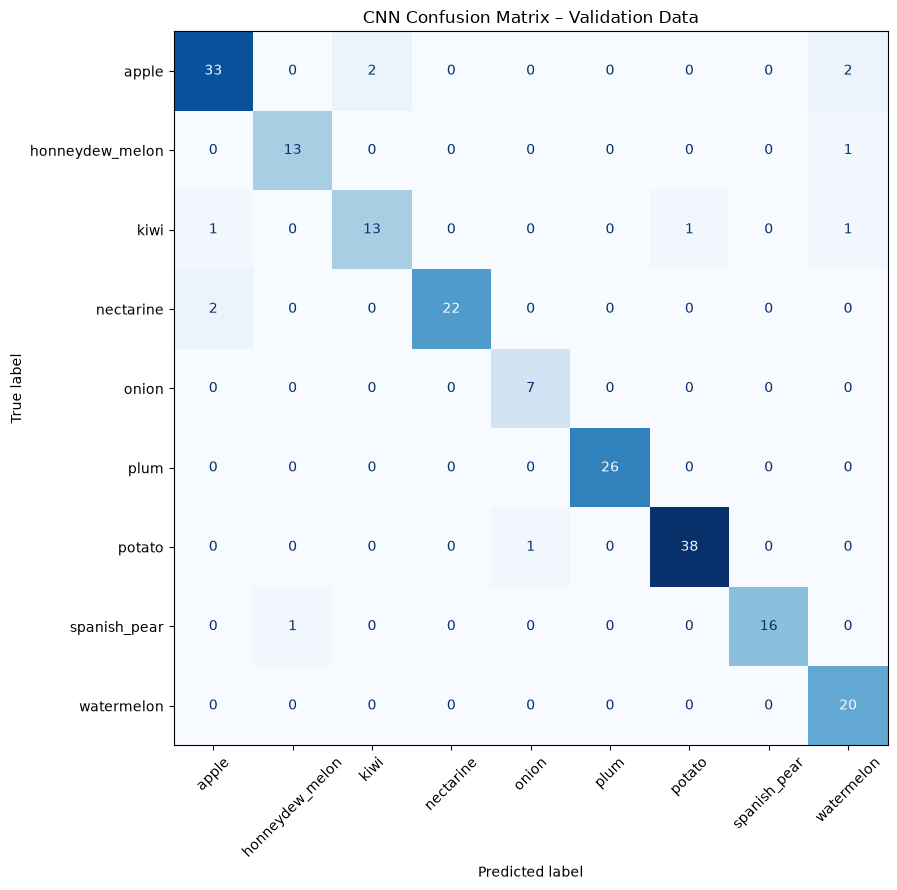

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix using actual and predicted labels
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Visualize the confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))

val_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

val_cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN Confusion Matrix – Validation Data")

plt.tight_layout()
plt.show()

#### 6.7.2 Classification Report

We use a classification report to evaluate precision, recall and F1-score for each class.

This gives us a more detailed understanding of the CNN's performance, especially since the number of images differs between classes.

In [ ]:
from sklearn.metrics import classification_report

# Generate classification metrics for all fruit and vegetable classes
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
)

# Display precision, recall, F1-score and support
print(report)

                 precision    recall  f1-score   support

          apple       0.92      0.89      0.90        37
honneydew_melon       0.93      0.93      0.93        14
           kiwi       0.87      0.81      0.84        16
      nectarine       1.00      0.92      0.96        24
          onion       0.88      1.00      0.93         7
           plum       1.00      1.00      1.00        26
         potato       0.97      0.97      0.97        39
   spanish_pear       1.00      0.94      0.97        17
     watermelon       0.83      1.00      0.91        20

       accuracy                           0.94       200
      macro avg       0.93      0.94      0.93       200
   weighted avg       0.94      0.94      0.94       200



#### 6.7.3 Analysis of validation results

The CNN correctly classifies 188 out of 200 validation images, achieving an accuracy of 94%.

The classification report shows a macro F1-score of 0.93, indicating good performance across the nine classes.

The confusion matrix shows that plum and watermelon are correctly classified in all cases. Kiwi has the lowest F1-score (0.84), making it the most challenging class for the model.

Some apples are confused with kiwi and watermelon, while two nectarines are classified as apples.

Overall, the CNN performs well on the validation dataset, but there is still room for improvement in distinguishing certain classes.

#### 6.7.4 Visualize Misclassified Images

We visualize the validation images that our CNN classified incorrectly.

For each image, we show the actual class and the predicted class. This helps us understand which fruits and vegetables the model has difficulty distinguishing.

By examining these images, we can identify possible reasons for the classification errors and areas for improvement.

Misclassified images: 12


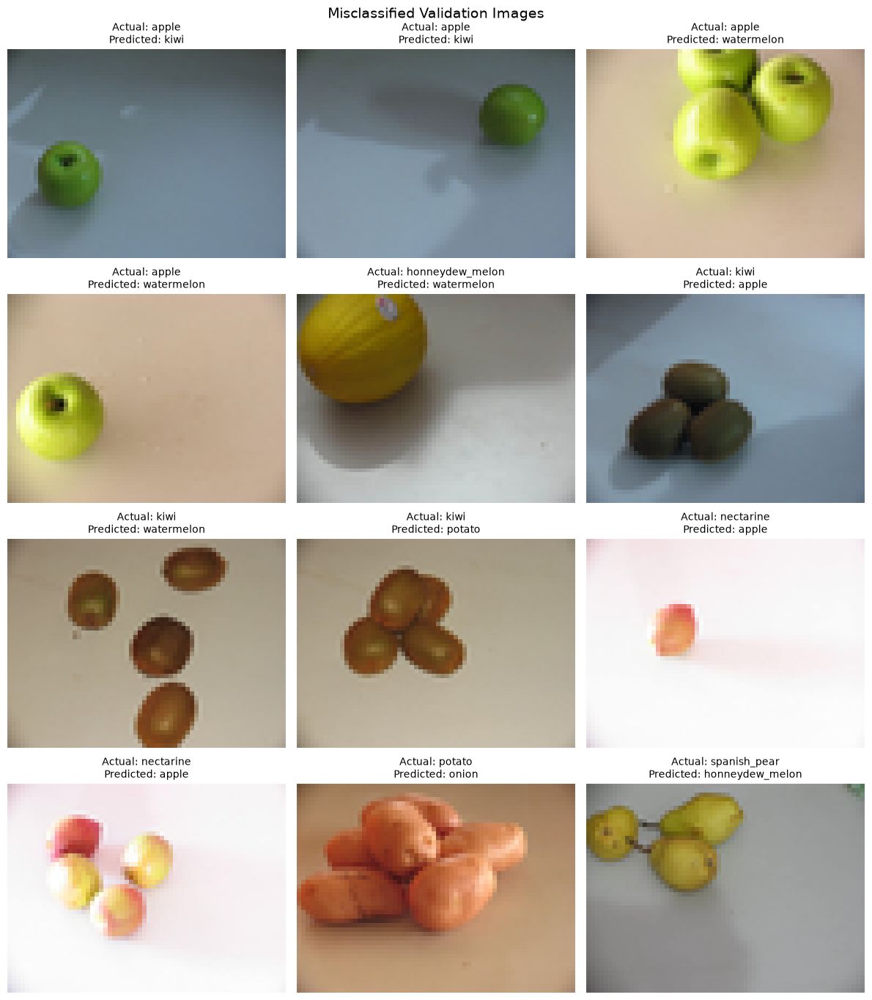

In [ ]:
# Find the validation images that were classified incorrectly
incorrect_indices = [
    i for i, (actual, predicted) in enumerate(zip(y_true, y_pred))
    if actual != predicted
]

# Display the total number of incorrect predictions
print("Misclassified images:", len(incorrect_indices))

# Create a grid to display the misclassified images
num_images = len(incorrect_indices)
num_cols = 3
num_rows = (num_images + num_cols - 1) // num_cols

fig, axes = plt.subplots(
    num_rows, num_cols,
    figsize=(12, num_rows * 3.5)
)

# Flatten the axes to simplify image placement
axes = axes.flatten()

# Display each incorrectly classified image
for ax, idx in zip(axes, incorrect_indices):

    # Get the image path from the validation dataset
    row = val_dataset.dataframe.iloc[idx]
    image_path = project_root / row["image_path"]

    # Load the image using the group's existing function
    image = load_image(image_path)

    # Get the actual and predicted class names
    actual_class = class_names[y_true[idx]]
    predicted_class = class_names[y_pred[idx]]

    # Display the image with its actual and predicted labels
    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual_class}\nPredicted: {predicted_class}",
        fontsize=10
    )
    ax.axis("off")

# Hide any unused positions in the grid
for ax in axes[num_images:]:
    ax.axis("off")

plt.suptitle("Misclassified Validation Images", fontsize=14)
plt.tight_layout()
plt.show()

### 6.8 Improve and Compare CNN Models

We investigate whether adding dropout can improve our CNN model.

Dropout randomly disables some neurons during training, which can help reduce overfitting and improve generalization.

We train a second CNN with dropout and compare its validation results with our original model.

We use the same training and validation datasets to make the comparison fair. The test dataset is reserved for final evaluation.

#### 6.8.1 Create a CNN with Dropout

We create a second CNN with the same architecture as our original model, but add a dropout layer with a rate of 0.3.

This means that 30% of the neurons in this layer are randomly disabled during training. We want to investigate whether this improves the model's performance on the validation dataset.

In [ ]:
# The CNN with dropout is the model used in the app, so its architecture is
# imported from src/cnn_model.py. It is identical to FruitCNN above, with one
# Dropout(0.3) layer added before the last layer.
from src.cnn_model import FruitCNNDropout

# Set the random seed before initializing the new model
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Create the CNN with dropout
dropout_model = FruitCNNDropout(num_classes=len(class_names)).to(device)

# Display the model architecture
print(dropout_model)


FruitCNNDropout(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6144, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)


#### 6.8.2 Train the CNN with Dropout

We train the CNN with dropout for 10 epochs using the same training settings as our original model.

During training, we track training and validation loss and accuracy. We save the model with the lowest validation loss to compare it with our original CNN.

The best dropout model is saved separately to preserve the original model.

In [ ]:
dropout_epochs = 10
best_dropout_model_path = project_root / "best_cnn_dropout_model.pth"
dropout_history_path = results_path / "cnn_dropout_history.json"

if TRAIN_CNN or not best_dropout_model_path.exists():
    # Configure training for the dropout model
    dropout_criterion = nn.CrossEntropyLoss()
    dropout_optimizer = optim.Adam(dropout_model.parameters(), lr=0.001)

    dropout_train_losses = []
    dropout_val_losses = []
    dropout_train_accuracies = []
    dropout_val_accuracies = []

    best_dropout_val_loss = float("inf")
    best_dropout_epoch = 0

    # Train the dropout model
    for epoch in range(dropout_epochs):

        dropout_model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            dropout_optimizer.zero_grad()

            outputs = dropout_model(images)
            loss = dropout_criterion(outputs, labels)

            loss.backward()
            dropout_optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_total += labels.size(0)

        epoch_train_loss = train_loss / train_total
        epoch_train_accuracy = 100 * train_correct / train_total

        # Evaluate on validation data
        dropout_model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = dropout_model(images)
                loss = dropout_criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_accuracy = 100 * val_correct / val_total

        # Store training history
        dropout_train_losses.append(epoch_train_loss)
        dropout_val_losses.append(epoch_val_loss)
        dropout_train_accuracies.append(epoch_train_accuracy)
        dropout_val_accuracies.append(epoch_val_accuracy)

        # Save the model with the lowest validation loss
        if epoch_val_loss < best_dropout_val_loss:
            best_dropout_val_loss = epoch_val_loss
            best_dropout_epoch = epoch + 1

            torch.save(
                dropout_model.state_dict(),
                best_dropout_model_path
            )

        print(
            f"Epoch {epoch + 1}/{dropout_epochs} | "
            f"Train loss: {epoch_train_loss:.4f} | "
            f"Val loss: {epoch_val_loss:.4f} | "
            f"Train accuracy: {epoch_train_accuracy:.2f}% | "
            f"Val accuracy: {epoch_val_accuracy:.2f}%"
        )

    print(f"\nBest epoch: {best_dropout_epoch}")
    print(f"Best validation loss: {best_dropout_val_loss:.4f}")
    print(f"Best dropout model saved to: {best_dropout_model_path}")

    dropout_history_path.write_text(json.dumps({
        "train_losses": dropout_train_losses, "val_losses": dropout_val_losses,
        "train_accuracies": dropout_train_accuracies, "val_accuracies": dropout_val_accuracies,
        "best_epoch": best_dropout_epoch, "best_val_loss": best_dropout_val_loss
    }, indent=2))

else:
    history = json.loads(dropout_history_path.read_text())
    dropout_train_losses = history["train_losses"]
    dropout_val_losses = history["val_losses"]
    dropout_train_accuracies = history["train_accuracies"]
    dropout_val_accuracies = history["val_accuracies"]
    best_dropout_epoch = history["best_epoch"]
    best_dropout_val_loss = history["best_val_loss"]

    print("TRAIN_CNN = False: using the saved dropout model and training history.")
    print(f"Best epoch: {best_dropout_epoch}")
    print(f"Best validation loss: {best_dropout_val_loss:.4f}")


Epoch 1/10 | Train loss: 1.7246 | Val loss: 1.2866 | Train accuracy: 38.18% | Val accuracy: 53.00%
Epoch 2/10 | Train loss: 1.0005 | Val loss: 0.8675 | Train accuracy: 64.88% | Val accuracy: 67.00%
Epoch 3/10 | Train loss: 0.6802 | Val loss: 0.5363 | Train accuracy: 75.05% | Val accuracy: 84.00%
Epoch 4/10 | Train loss: 0.5000 | Val loss: 0.4785 | Train accuracy: 82.84% | Val accuracy: 84.50%
Epoch 5/10 | Train loss: 0.3834 | Val loss: 0.4282 | Train accuracy: 86.03% | Val accuracy: 84.50%
Epoch 6/10 | Train loss: 0.3405 | Val loss: 0.2523 | Train accuracy: 88.90% | Val accuracy: 93.00%
Epoch 7/10 | Train loss: 0.2622 | Val loss: 0.3439 | Train accuracy: 91.33% | Val accuracy: 86.00%
Epoch 8/10 | Train loss: 0.2451 | Val loss: 0.1661 | Train accuracy: 90.89% | Val accuracy: 95.00%
Epoch 9/10 | Train loss: 0.1896 | Val loss: 0.2126 | Train accuracy: 94.01% | Val accuracy: 91.50%
Epoch 10/10 | Train loss: 0.1684 | Val loss: 0.1900 | Train accuracy: 94.88% | Val accuracy: 93.50%

Best epo

#### 6.8.3 Compare CNN Models

We compare the validation loss and validation accuracy of our original CNN and the CNN with dropout.

Both models were trained for 10 epochs using the same dataset and training settings. The comparison helps us evaluate whether adding dropout improves model performance. 

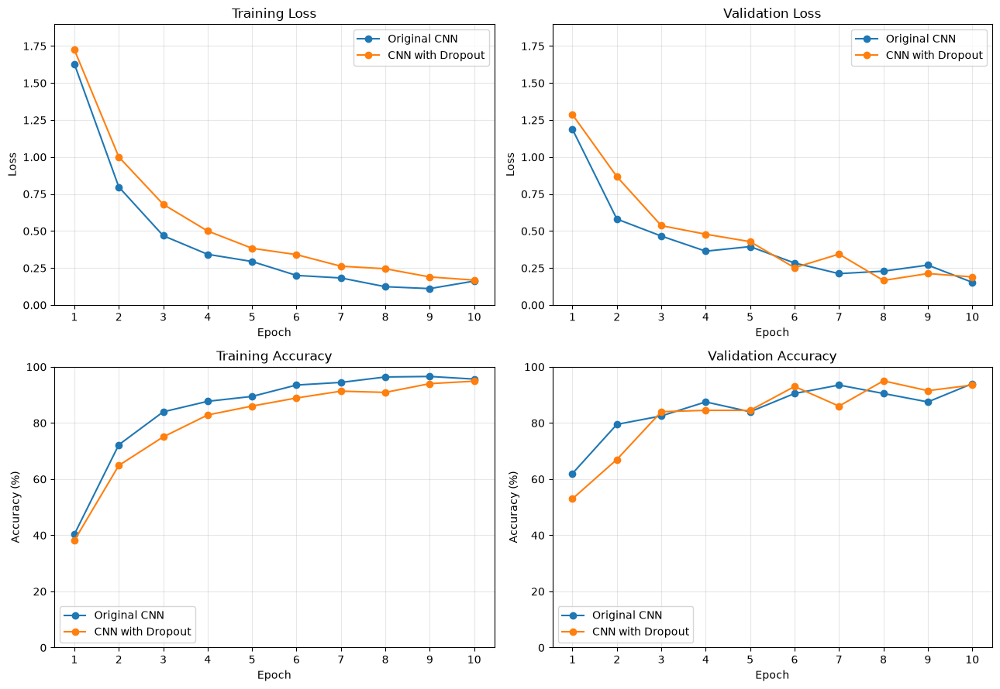

In [ ]:
# Compare training and validation performance of both CNN models
epochs_range = range(1, 11)

# Convert accuracy values to percentages when necessary
def to_percent(values):
    return [v * 100 for v in values] if max(values) <= 1 else values

original_train_acc = to_percent(train_accuracies)
original_val_acc = to_percent(val_accuracies)
dropout_train_acc = to_percent(dropout_train_accuracies)
dropout_val_acc = to_percent(dropout_val_accuracies)

# Create four comparison plots
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Training loss
axes[0, 0].plot(
    epochs_range, train_losses,
    marker="o", label="Original CNN"
)
axes[0, 0].plot(
    epochs_range, dropout_train_losses,
    marker="o", label="CNN with Dropout"
)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_ylabel("Loss")

# 2. Validation loss
axes[0, 1].plot(
    epochs_range, val_losses,
    marker="o", label="Original CNN"
)
axes[0, 1].plot(
    epochs_range, dropout_val_losses,
    marker="o", label="CNN with Dropout"
)
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_ylabel("Loss")

# 3. Training accuracy
axes[1, 0].plot(
    epochs_range, original_train_acc,
    marker="o", label="Original CNN"
)
axes[1, 0].plot(
    epochs_range, dropout_train_acc,
    marker="o", label="CNN with Dropout"
)
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_ylabel("Accuracy (%)")

# 4. Validation accuracy
axes[1, 1].plot(
    epochs_range, original_val_acc,
    marker="o", label="Original CNN"
)
axes[1, 1].plot(
    epochs_range, dropout_val_acc,
    marker="o", label="CNN with Dropout"
)
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_ylabel("Accuracy (%)")

# Use the same Y-axis scale for both loss plots
max_loss = max(
    max(train_losses),
    max(val_losses),
    max(dropout_train_losses),
    max(dropout_val_losses)
)

axes[0, 0].set_ylim(0, max_loss * 1.1)
axes[0, 1].set_ylim(0, max_loss * 1.1)

# Use the same Y-axis scale for both accuracy plots
axes[1, 0].set_ylim(0, 100)
axes[1, 1].set_ylim(0, 100)

# Apply consistent formatting to all plots
for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs_range))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 6.8.4 Analysis of Model Comparison

Both models improve during training. Their loss decreases and their accuracy increases, which means they are learning to recognize the different fruits and vegetables.

**Training results:** The original CNN learns faster and performs slightly better on the training images. This is expected because dropout makes training more difficult.

**Validation results:** Both models also perform well on images they have not trained on. The original CNN has a slightly lower validation loss (0.1536 compared to 0.1661). However, the dropout model has a slightly higher accuracy (95% compared to 94%).

This means that the dropout model correctly classifies 190 out of 200 validation images, compared to 188 for the original CNN.

**Overfitting:** Neither model shows clear signs of serious overfitting, since both perform well on training and validation images.

**Conclusion:** Adding dropout did not make a big difference. The original CNN has lower loss, while the dropout model gets two more images correct. We need to compare precision, recall and F1-score before deciding which model performs best overall.

#### 6.8.5 Compare Precision, Recall and F1-score

We compare precision, recall and F1-score for our original CNN and the CNN with dropout.

These metrics help us understand how well each model recognizes the nine different classes.

We use the same validation images for both models to make the comparison fair.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support
from IPython.display import display as show_table
import pandas as pd

# Load the best saved original CNN
original_model = FruitCNN(num_classes=len(class_names)).to(device)

original_model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

original_model.eval()

# Load the best saved CNN with dropout
dropout_best_model = FruitCNNDropout(
    num_classes=len(class_names)
).to(device)

dropout_best_model.load_state_dict(
    torch.load(best_dropout_model_path, map_location=device, weights_only=True)
)

dropout_best_model.eval()

# Collect predictions from both models
y_true_compare = []
original_predictions = []
dropout_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        original_outputs = original_model(images)
        dropout_outputs = dropout_best_model(images)

        y_true_compare.extend(labels.cpu().numpy())

        original_predictions.extend(
            original_outputs.argmax(dim=1).cpu().numpy()
        )

        dropout_predictions.extend(
            dropout_outputs.argmax(dim=1).cpu().numpy()
        )

# Calculate precision, recall and F1-score for each class
def get_class_metrics(y_true, y_pred, model_name):

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        zero_division=0
    )

    return pd.DataFrame({
        "Class": class_names,
        f"{model_name} Precision": precision,
        f"{model_name} Recall": recall,
        f"{model_name} F1": f1
    })

# Calculate metrics for the original CNN
original_metrics = get_class_metrics(
    y_true_compare,
    original_predictions,
    "Original"
)

# Calculate metrics for the CNN with dropout
dropout_metrics = get_class_metrics(
    y_true_compare,
    dropout_predictions,
    "Dropout"
)

# Combine the results into one comparison table
comparison_df = original_metrics.merge(
    dropout_metrics,
    on="Class"
)

# Display the comparison table
show_table(comparison_df.round(2))

,Class,Original Precision,Original Recall,Original F1,Dropout Precision,Dropout Recall,Dropout F1
0,apple,0.92,0.89,0.90,0.90,0.95,0.92
1,honneydew_melon,0.93,0.93,0.93,1.00,1.00,1.00
2,kiwi,0.87,0.81,0.84,0.82,0.88,0.85
3,nectarine,1.00,0.92,0.96,0.95,0.88,0.91
4,onion,0.88,1.00,0.93,0.86,0.86,0.86
5,plum,1.00,1.00,1.00,1.00,1.00,1.00
6,potato,0.97,0.97,0.97,0.97,0.97,0.97
7,spanish_pear,1.00,0.94,0.97,1.00,0.94,0.97
8,watermelon,0.83,1.00,0.91,1.00,1.00,1.00


#### 6.8.6 Visualize F1-score Comparison

We compare the F1-scores of both CNN models for each fruit and vegetable class.

A higher F1-score means a better balance between precision and recall. This visualization helps us identify which classes improved or became worse after adding dropout.

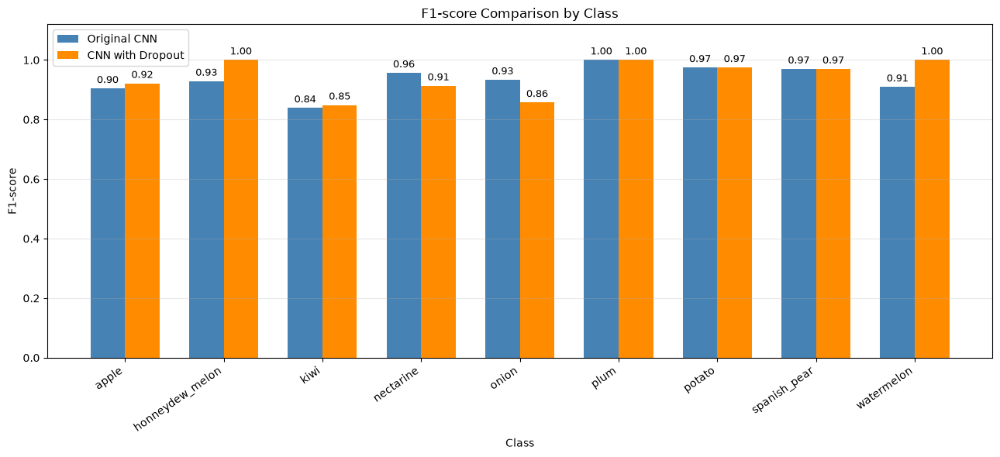

In [ ]:
# Compare F1-scores for each class
x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))

# Original CNN
bars_original = ax.bar(
    x - width / 2,
    comparison_df["Original F1"],
    width,
    label="Original CNN",
    color="steelblue"
)

# CNN with Dropout
bars_dropout = ax.bar(
    x + width / 2,
    comparison_df["Dropout F1"],
    width,
    label="CNN with Dropout",
    color="darkorange"
)

# Display F1-score values above each bar
ax.bar_label(bars_original, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(bars_dropout, fmt="%.2f", padding=3, fontsize=9)

# Format the chart
ax.set_title("F1-score Comparison by Class")
ax.set_xlabel("Class")
ax.set_ylabel("F1-score")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=35, ha="right")
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 6.8.7 Analysis and Model Selection

The F1-score comparison shows that both CNN models perform well, but adding dropout affects the classes differently.

The dropout model performs better on apple, honeydew melon, kiwi and watermelon. The biggest improvement is for watermelon, where the F1-score increases from 0.91 to 1.00.

However, the original CNN performs better on nectarine and onion. Both models achieve the same results for plum, potato and spanish pear.

The dropout model also has slightly higher validation accuracy (95% compared to 94%), but the original CNN has lower validation loss.

**Conclusion:** Dropout improves some classes but makes others worse. The overall difference between the models is small, and neither model is clearly better in every way.

We choose the CNN with dropout for final evaluation because it correctly classifies slightly more validation images. However, the difference is small, so we cannot be certain that it will perform better on new data.

### 6.9 Final Evaluation on the Test Set

#### 6.9.1 Test Evaluation

We evaluate our selected CNN with dropout on the 200 test images.

These images have not been used during training or model selection.

We calculate accuracy, precision, recall and F1-score to measure how well the model performs on unseen images.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Select test images from the shared dataset
test_df = df[df["split"] == "test"].reset_index(drop=True)

# Create the test dataset using the same settings as training
test_dataset = FruitDataset(
    test_df,
    project_root,
    class_to_idx
)

# Create the test DataLoader without shuffling
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Load the best saved CNN with dropout
final_model = FruitCNNDropout(
    num_classes=len(class_names)
).to(device)

final_model.load_state_dict(
    torch.load(
        best_dropout_model_path,
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

# Collect predictions on the test images
test_y_true = []
test_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        test_y_true.extend(labels.cpu().numpy())
        test_y_pred.extend(predictions.cpu().numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(test_y_true, test_y_pred)

correct_predictions = sum(
    actual == predicted
    for actual, predicted in zip(test_y_true, test_y_pred)
)

print(f"Test images: {len(test_y_true)}")
print(f"Correct predictions: {correct_predictions}")
print(f"Test accuracy: {test_accuracy:.2%}")

# Display precision, recall and F1-score for each class
print("\nClassification Report:")

print(
    classification_report(
        test_y_true,
        test_y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

Test images: 200
Correct predictions: 197
Test accuracy: 98.50%

Classification Report:
                 precision    recall  f1-score   support

          apple       0.95      0.97      0.96        36
honneydew_melon       1.00      1.00      1.00        14
           kiwi       0.93      0.93      0.93        15
      nectarine       1.00      0.96      0.98        25
          onion       1.00      1.00      1.00         8
           plum       1.00      1.00      1.00        27
         potato       1.00      1.00      1.00        39
   spanish_pear       1.00      1.00      1.00        16
     watermelon       1.00      1.00      1.00        20

       accuracy                           0.98       200
      macro avg       0.99      0.99      0.99       200
   weighted avg       0.99      0.98      0.99       200



#### 6.9.2 Confusion Matrix

We use a confusion matrix to see which classes our CNN predicts correctly and which classes it confuses.

The rows show the actual classes, and the columns show the predicted classes.

Our model correctly classifies 197 out of 200 test images. The confusion matrix helps us understand the three incorrect predictions.

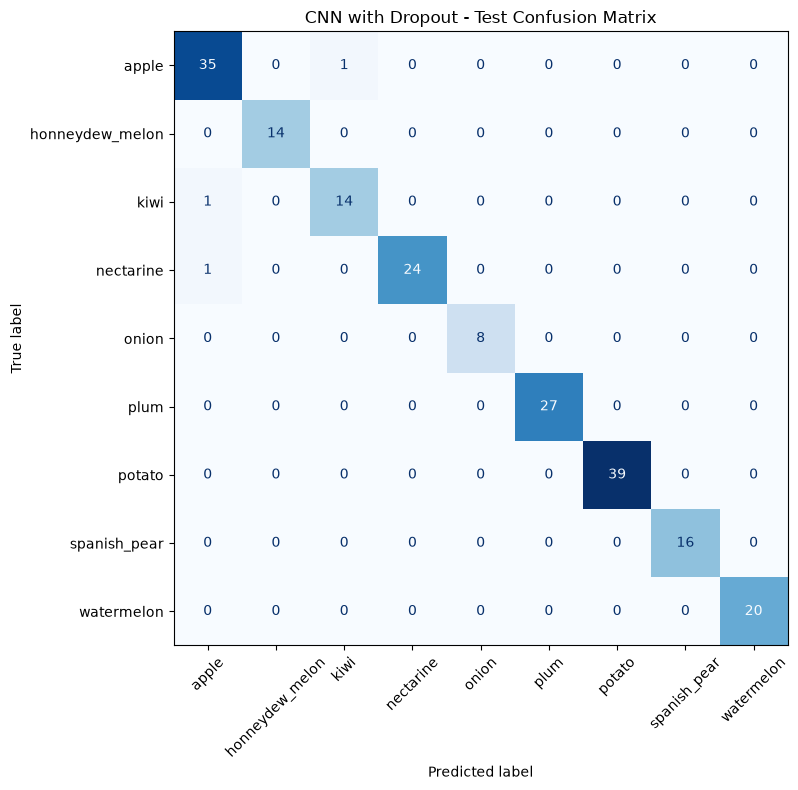

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix for the test dataset
test_cm = confusion_matrix(
    test_y_true,
    test_y_pred,
    labels=range(len(class_names))
)

# Create the confusion matrix visualization
fig, ax = plt.subplots(figsize=(10, 8))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=class_names
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN with Dropout - Test Confusion Matrix")

plt.tight_layout()
plt.show()

#### 6.9.3 Compare CNN with Baseline

We compare our CNN with dropout to the logistic regression baseline using the same 200 test images.

The logistic regression model uses color histograms, while the CNN learns patterns directly from the images.

We compare test accuracy and macro F1-score to see how much the CNN improves classification performance.

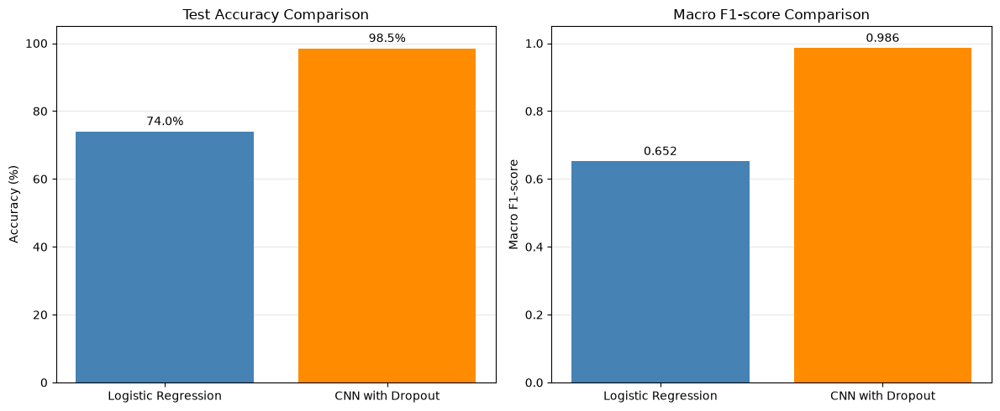

In [ ]:
from sklearn.metrics import f1_score

# Baseline results from the logistic regression section
baseline_accuracy = baseline_test_accuracy
baseline_macro_f1 = baseline_test_macro_f1

# Calculate CNN results on the test dataset
cnn_accuracy = accuracy_score(test_y_true, test_y_pred)
cnn_macro_f1 = f1_score(
    test_y_true,
    test_y_pred,
    average="macro"
)

# Prepare model comparison
models = ["Logistic Regression", "CNN with Dropout"]

accuracy_values = [
    baseline_accuracy * 100,
    cnn_accuracy * 100
]

f1_values = [
    baseline_macro_f1,
    cnn_macro_f1
]

# Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare test accuracy
bars_accuracy = axes[0].bar(
    models,
    accuracy_values,
    color=["steelblue", "darkorange"]
)

axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 105)
axes[0].bar_label(bars_accuracy, fmt="%.1f%%", padding=3)

# Compare macro F1-score
bars_f1 = axes[1].bar(
    models,
    f1_values,
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Macro F1-score Comparison")
axes[1].set_ylabel("Macro F1-score")
axes[1].set_ylim(0, 1.05)
axes[1].bar_label(bars_f1, fmt="%.3f", padding=3)

# Apply consistent formatting
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 6.9.4 Analysis of Test Results

The results show that our CNN with dropout performs much better than the logistic regression baseline.

**Accuracy:** The logistic regression model correctly classifies 74% of the test images, while our CNN achieves 98.5%. This means that our CNN correctly classifies 197 out of 200 images, compared to 148 for logistic regression.

**Macro F1-score:** This measures how well the models perform across all nine classes, giving each class equal importance. The CNN achieves 0.986 compared to 0.652 for logistic regression. This shows that the CNN performs better across the different fruit and vegetable classes.

**Confusion matrix:** Our CNN makes only three mistakes. It confuses one apple with kiwi, one kiwi with apple, and one nectarine with apple. All other test images are classified correctly.

**Conclusion:** The CNN is clearly the better model on our test dataset. It can learn patterns directly from the images, while logistic regression uses simpler color-based features. This may explain why the CNN performs better.

The results are very good, but we have only tested the model on 200 images. We cannot be certain that it will perform equally well on completely new images outside our dataset.

#### 6.9.5 Visualize CNN Feature Maps

To better understand how our CNN processes images, we visualize the feature maps from its first convolutional layer.

The CNN uses learned filters to detect different visual patterns in an image. Each feature map shows which parts of the image activate a particular filter.

This helps us understand how the CNN extracts information from images before making a classification.

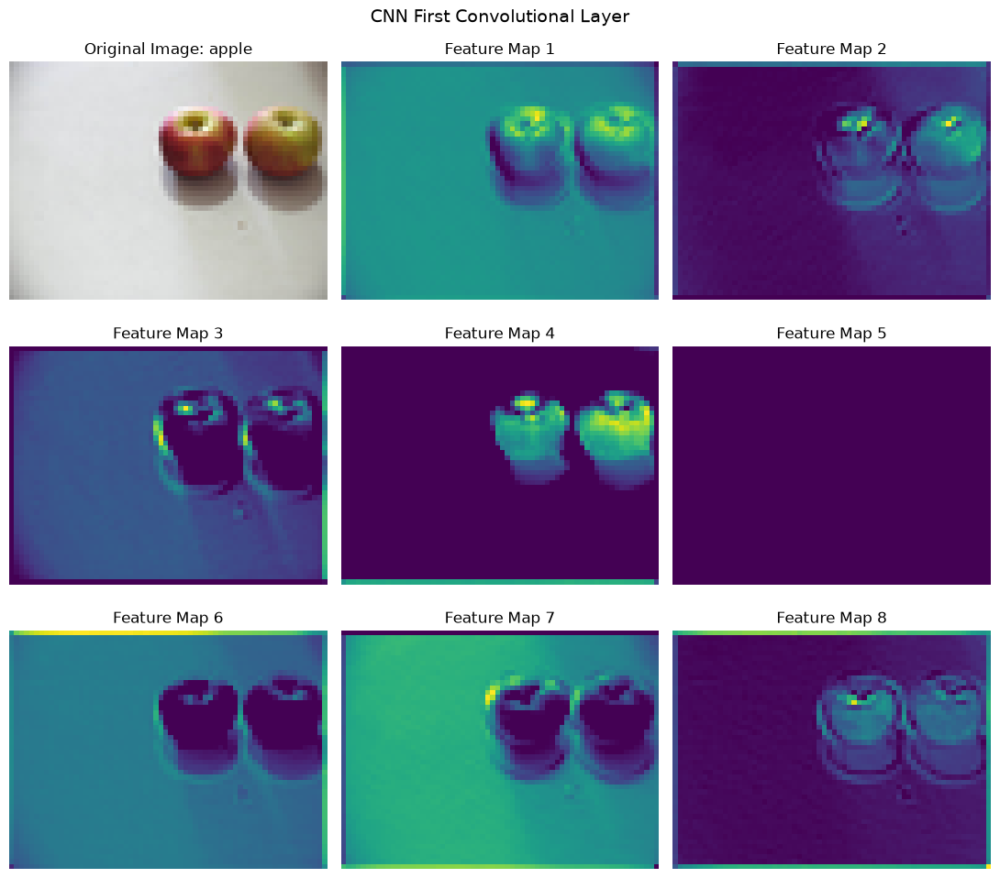

In [ ]:
# Select an image from the training dataset
image, label = train_dataset[0]

# Prepare the image for the CNN
input_image = image.unsqueeze(0).to(device)

# Extract feature maps from the first convolutional layer
final_model.eval()

with torch.no_grad():
    first_conv = final_model.features[0]
    feature_maps = torch.relu(first_conv(input_image))

# Convert feature maps to NumPy
feature_maps = feature_maps.squeeze(0).cpu().numpy()

# Display the original image and eight feature maps
fig, axes = plt.subplots(3, 3, figsize=(11, 10))

axes[0, 0].imshow(image.permute(1, 2, 0).cpu().numpy())
axes[0, 0].set_title(f"Original Image: {class_names[label.item()]}")
axes[0, 0].axis("off")

# Display eight feature maps
for i, ax in enumerate(axes.flat[1:]):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

plt.suptitle("CNN First Convolutional Layer", fontsize=14)
plt.tight_layout()
plt.show()

##### Analysis of CNN Feature Maps

The feature maps show how different filters react to the same image of two apples.

Some filters highlight the edges and shapes of the apples, while others respond to different visual patterns. Some feature maps are almost completely dark, meaning that those filters have little or no activation for this image.

This shows that the CNN extracts different types of information from the image before making its prediction.

Unlike logistic regression, which uses color histograms, our CNN can learn visual patterns directly from the images.

### 6.10 CNN Conclusions

**Model comparison.** Both CNN models performed well on the validation set: 94% accuracy without dropout and 95% with dropout. The difference is two photos, so we selected the dropout model for the final test without being certain that it is better on new data.

**Final test results.** The CNN with dropout classified 197 of 200 test photos correctly, with **98.5% accuracy** and **0.986 macro-F1**. It confused one apple with kiwi, one kiwi with apple and one nectarine with apple.

**Comparison with the baseline.** On the same test photos, logistic regression reached 74.0% accuracy and 0.652 macro-F1. The CNN learns shapes and textures as well as colors, which can explain the large improvement.

**Why the test score is an upper bound.** The test score was *higher* than the validation score (98.5% versus 95%), and all three subsets come from the same few photography sessions. The baseline section showed that the photo corners alone carry most of the color signal, and that scores drop when photos from the same capture interval are kept together. The CNN sees the whole photo, so it could use the same shortcut. The next section tests this directly.

## 7. Does the CNN Look at the Fruit or the Background?

Earlier sections found three warning signs:

1. **Few photography sessions.** Five of the nine classes were photographed on a single day, so each of those classes shares one background and one lighting setup.
2. **Background differs between classes.** Corner colors, brightness and sharpness differ clearly between classes (Kruskal–Wallis tests in the EDA).
3. **The baseline can use the background.** A model that only sees the four corners reaches 0.652 macro-F1, and scores drop when photos from the same capture interval are kept together.

A CNN that has learned "brown table means potato" would still score well on our test set, but fail on photos taken at home. We check this in three ways:

- **Occlusion test:** which parts of each photo does the CNN rely on?
- **Grouped cross-validation:** how much does the CNN's score drop when photos from the same capture interval are kept together?
- **Own photos:** how does the CNN perform on photos taken outside the dataset?

### 7.1 Occlusion Test – Which Pixels Matter?

**Idea.** We cover a small grey square on the photo and measure how much the model's confidence in its answer drops. Then we move the square and repeat until it has covered the whole photo. If covering the fruit lowers the confidence a lot while covering the table does not, the model is looking at the fruit.

**Measure.** For each test photo we use the Mask 80 method from the baseline to mark which pixels are food and which are background. We then compare:

- **Food area:** the share of the photo that is food.
- **Food importance:** the share of the total confidence drop that comes from covering food pixels.

If the food importance is clearly higher than the food area, the model concentrates on the food. If it is similar or lower, the background matters as much as the fruit.

The model sees the photo at 64 × 48 pixels, so the grey square is 8 × 8 pixels and moves 4 pixels at a time.

In [ ]:
def occlusion_map(model, image, target, patch=8, stride=4, fill=0.5):
    """Return, for each pixel, how much the target probability drops when it is covered."""
    _, height, width = image.shape
    positions = [
        (top, left)
        for top in range(0, height - patch + 1, stride)
        for left in range(0, width - patch + 1, stride)
    ]

    # One copy of the photo per position, each with a grey square in a new place
    covered = image.unsqueeze(0).repeat(len(positions), 1, 1, 1)
    for index, (top, left) in enumerate(positions):
        covered[index, :, top:top + patch, left:left + patch] = fill

    with torch.no_grad():
        original_probability = torch.softmax(model(image.unsqueeze(0).to(device)), dim=1)[0, target].item()
        covered_probabilities = torch.softmax(model(covered.to(device)), dim=1)[:, target].cpu().numpy()

    # Spread each drop over the pixels that were covered, then average
    drop = np.zeros((height, width))
    counts = np.zeros((height, width))
    for (top, left), probability in zip(positions, covered_probabilities):
        drop[top:top + patch, left:left + patch] += original_probability - probability
        counts[top:top + patch, left:left + patch] += 1

    return drop / np.maximum(counts, 1), original_probability


def food_mask_small(image_path, size=(64, 48), threshold=80):
    """Mark food pixels with the baseline's Mask 80 method, at the CNN's input size."""
    with Image.open(project_root / image_path) as source:
        pixels = np.asarray(source.convert("RGB"))
    keep = background_color_distance(pixels).reshape(pixels.shape[:2]) > threshold
    small = Image.fromarray(keep).resize(size, Image.Resampling.NEAREST)
    return np.asarray(small, dtype=bool)


# Run the occlusion test on all 200 test photos with the final CNN
occlusion_rows = []
occlusion_maps = []
final_model.eval()

for index in range(len(test_dataset)):
    image, label = test_dataset[index]
    predicted = int(test_y_pred[index])
    importance, confidence = occlusion_map(final_model, image, predicted)
    importance = np.clip(importance, 0, None)  # only count drops in confidence
    food = food_mask_small(test_df.loc[index, "image_path"])

    if food.any() and importance.sum() > 0:
        food_area = food.mean()
        food_importance = importance[food].sum() / importance.sum()
    else:
        food_area, food_importance = np.nan, np.nan

    occlusion_maps.append(importance)
    occlusion_rows.append({
        "image_path": test_df.loc[index, "image_path"],
        "actual": class_names[int(label)],
        "predicted": class_names[predicted],
        "confidence": confidence,
        "food_area": food_area,
        "food_importance": food_importance,
    })

occlusion_df = pd.DataFrame(occlusion_rows)
measured = occlusion_df.dropna(subset=["food_importance"])

print("Test photos measured:", len(measured), "of", len(occlusion_df))
print(f"Average food area:       {measured['food_area'].mean():.1%} of the photo")
print(f"Average food importance: {measured['food_importance'].mean():.1%} of the confidence drop")
print(f"Photos where the background matters more than the food: "
      f"{(measured['food_importance'] < 0.5).sum()} of {len(measured)}")

display(
    measured.groupby("actual")[["food_area", "food_importance"]]
    .mean()
    .rename(columns={"food_area": "Food area", "food_importance": "Food importance"})
    .style.format("{:.1%}")
)

In [ ]:
# Show the occlusion map for the misclassified test photos and a few correct ones
wrong = occlusion_df.index[occlusion_df["actual"] != occlusion_df["predicted"]].tolist()
correct = (
    occlusion_df[occlusion_df["actual"] == occlusion_df["predicted"]]
    .groupby("actual").head(1).index.tolist()
)
examples = (wrong + correct)[:6]

fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 5.2))
axes = np.array(axes).reshape(2, -1)

for column, index in enumerate(examples):
    image, _ = test_dataset[index]
    row = occlusion_df.loc[index]
    photo = image.permute(1, 2, 0).numpy()

    axes[0, column].imshow(photo)
    axes[0, column].set_title(f"Actual: {row['actual']}\nPredicted: {row['predicted']}", fontsize=9)

    axes[1, column].imshow(photo)
    axes[1, column].imshow(occlusion_maps[index], cmap="Reds", alpha=0.6)
    share = row["food_importance"]
    axes[1, column].set_title("Food importance: " + ("n/a" if pd.isna(share) else f"{share:.0%}"), fontsize=9)

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("Where covering the photo lowers the CNN's confidence (darker red = more important)")
plt.tight_layout()
plt.show()

##### How to read the occlusion test

Dark red areas are the parts of the photo the CNN relies on. If they cover the fruit, the model has learned what the fruit looks like. If they spread over the table or the edges, the model also uses the photo setup.

**Result (to be completed after running):** *Describe the average food area compared with the food importance, which classes rely most on the background, and what the misclassified photos show.*

### 7.2 Grouped Cross-Validation for the CNN

The baseline compared two ways of splitting the 1,603 training photos into five folds:

- **Random folds:** photos are spread at random, so photos taken seconds apart can end up on both sides.
- **Grouped folds:** all photos from the same five-minute capture interval stay in the same fold, so the model is always scored on photo sessions it has not seen.

We train the CNN with dropout on exactly the same folds, with the same settings as before (10 epochs, Adam, learning rate 0.001, batch size 32). A large drop from random to grouped folds means that part of the CNN's score comes from recognising the photo session rather than the food.

In [ ]:
cv_results_path = results_path / "cnn_grouped_cv.csv"

if RUN_CNN_GROUPED_CV:
    # Load the training photos once, in the same order as the baseline's folds
    cv_images = torch.stack([
        torch.from_numpy(load_image(project_root / path)).permute(2, 0, 1)
        for path in review_rows["image_path"]
    ])
    cv_targets = torch.tensor([class_to_idx[name] for name in review_labels])

    def train_and_score_cnn(fit_indices, score_indices, epochs=10):
        """Train a fresh CNN with dropout on one fold and return its macro-F1."""
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        fold_model = FruitCNNDropout(num_classes=len(class_names)).to(device)
        fold_optimizer = optim.Adam(fold_model.parameters(), lr=0.001)
        fold_criterion = nn.CrossEntropyLoss()
        fold_loader = DataLoader(
            TensorDataset(cv_images[fit_indices], cv_targets[fit_indices]),
            batch_size=32, shuffle=True
        )

        for _ in range(epochs):
            fold_model.train()
            for images, targets in fold_loader:
                images, targets = images.to(device), targets.to(device)
                fold_optimizer.zero_grad()
                loss = fold_criterion(fold_model(images), targets)
                loss.backward()
                fold_optimizer.step()

        fold_model.eval()
        with torch.no_grad():
            predicted = fold_model(cv_images[score_indices].to(device)).argmax(dim=1).cpu().numpy()

        return f1_score(cv_targets[score_indices].numpy(), predicted,
                        labels=range(len(class_names)), average="macro", zero_division=0)

    cv_rows = []
    for fold_type, folds in [("Random folds", review_folds), ("Grouped folds", group_folds)]:
        for fold_number, (fit_indices, score_indices) in enumerate(folds, start=1):
            score = train_and_score_cnn(fit_indices, score_indices)
            cv_rows.append({"Folds": fold_type, "Fold": fold_number, "Macro-F1": score})
            print(f"{fold_type}, fold {fold_number}: macro-F1 = {score:.3f}")

    cnn_cv_scores = pd.DataFrame(cv_rows)
    cnn_cv_scores.to_csv(cv_results_path, index=False)
else:
    cnn_cv_scores = pd.read_csv(cv_results_path)
    print("RUN_CNN_GROUPED_CV = False: loaded saved results from", cv_results_path.name)

# Compare with the baseline's results on the same folds (balanced Mask 80)
baseline_cv = shortcut_comparison.set_index("Check")
cv_summary = pd.DataFrame({
    "Logistic regression (Mask 80)": [
        baseline_cv.loc["Mask 80, random folds", "Mean macro-F1"],
        baseline_cv.loc["Mask 80, grouped folds", "Mean macro-F1"],
    ],
    "CNN with dropout": [
        cnn_cv_scores.loc[cnn_cv_scores["Folds"] == "Random folds", "Macro-F1"].mean(),
        cnn_cv_scores.loc[cnn_cv_scores["Folds"] == "Grouped folds", "Macro-F1"].mean(),
    ],
}, index=["Random folds", "Grouped folds"])
cv_summary.loc["Drop"] = cv_summary.loc["Random folds"] - cv_summary.loc["Grouped folds"]

display(cv_summary.round(3))

##### How to read the grouped cross-validation

The **Drop** row shows how much each model loses when it is scored on capture intervals it has not seen. The grouped score is the more realistic estimate of how the model performs on new photo sessions.

**Result (to be completed after running):** *Compare the CNN's drop with the baseline's drop, and state which score the group considers the most realistic estimate for new photos.*

### 7.3 Test on Our Own Photos

The project plan includes photos we took ourselves. These come from a completely different setting: other backgrounds, other lighting and other cameras. This is the most direct test of how the app will work for a real user.

**How to add photos:** put them in `data/own_photos/<class>/`, using the same class names as the dataset, for example `data/own_photos/apple/apple_01.jpg`. Phone photos are rotated upright using the orientation stored in the photo file.

In [ ]:
from src.predict import load_cnn_model, predict_image, CLASS_NAMES

own_photos_path = data_path / "own_photos"
app_model = load_cnn_model()

# The app's class names use the spelling "honeydew_melon"; the dataset folder uses "honneydew_melon"
dataset_to_app_name = {name: app for name, app in zip(class_names, CLASS_NAMES)}

own_rows = []
if own_photos_path.is_dir():
    for class_folder in sorted(own_photos_path.iterdir()):
        if not class_folder.is_dir():
            continue
        for photo_path in sorted(class_folder.iterdir()):
            if photo_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            with Image.open(photo_path) as photo:
                photo = ImageOps.exif_transpose(photo).convert("RGB")
            predicted, probabilities = predict_image(photo, app_model)
            own_rows.append({
                "photo": photo_path.name,
                "actual": dataset_to_app_name.get(class_folder.name, class_folder.name),
                "predicted": predicted,
                "confidence (%)": probabilities[predicted],
            })

if own_rows:
    own_df = pd.DataFrame(own_rows)
    own_df["correct"] = own_df["actual"] == own_df["predicted"]
    print(f"Own photos: {len(own_df)}, correct: {own_df['correct'].sum()} ({own_df['correct'].mean():.0%})")
    display(own_df.groupby("actual")["correct"].agg(["count", "sum", "mean"])
            .rename(columns={"count": "Photos", "sum": "Correct", "mean": "Accuracy"}))
    display(own_df)
else:
    print("No own photos found. Add them to data/own_photos/<class>/ and run this cell again.")

**Result (to be completed after running):** *How many of our own photos were classified correctly, which classes worked and which did not, and what the mistakes have in common (background, lighting, number of fruits).*

## 8. Application

The app lets a user upload a photo or take one with the phone camera. It shows:

- the fruit or vegetable the CNN predicts, with a warning when the model is unsure,
- the three most likely classes and the probabilities for all nine classes,
- nutritional information from Livsmedelsverket *(in progress)*.

**Why the app is a separate file.** Streamlit runs as its own small web server, so the app cannot run inside a notebook cell. The app code is kept in `app.py` in the project root and shown below. The app and this notebook use the same functions from `src/predict.py`, so the app classifies photos in exactly the same way as the evaluations above.

**Run the app** from the project root in a terminal:

```bash
streamlit run app.py
```

*Screenshots of the app will be added here.*

### 8.1 The Prediction Function Behind the App

The app calls `predict_image()`, which preprocesses the photo the same way as during training and returns the predicted class and the probability of every class. Here we call it on three test photos to show what the app receives.

In [ ]:
demo_rows = []
for _, row in test_df.groupby("target_class").head(1).head(3).iterrows():
    with Image.open(project_root / row["image_path"]) as photo:
        predicted, probabilities = predict_image(photo.convert("RGB"), app_model)
    top_three = sorted(probabilities.items(), key=lambda item: item[1], reverse=True)[:3]
    demo_rows.append({
        "Actual": row["target_class"],
        "Prediction": predicted,
        "Top three (%)": ", ".join(f"{name} {score:.1f}" for name, score in top_three),
    })

display(pd.DataFrame(demo_rows))

### 8.2 App Code

In [ ]:
from IPython.display import Code

app_file = project_root / "app.py"
Code(filename=str(app_file), language="python") if app_file.exists() else print("app.py not found in", project_root)

## 9. Conclusions and Method Comparison

In [ ]:
comparison = pd.DataFrame({
    "Test accuracy": [baseline_test_accuracy, cnn_accuracy],
    "Test macro-F1": [baseline_test_macro_f1, cnn_macro_f1],
    "CV macro-F1, random folds": cv_summary.loc["Random folds"].values,
    "CV macro-F1, grouped folds": cv_summary.loc["Grouped folds"].values,
}, index=["Logistic regression (color histograms)", "CNN with dropout"])

display(comparison.style.format({
    "Test accuracy": "{:.1%}", "Test macro-F1": "{:.3f}",
    "CV macro-F1, random folds": "{:.3f}", "CV macro-F1, grouped folds": "{:.3f}",
}))

*The test scores use the models selected on validation (the baseline with default class weights). The cross-validation scores use balanced class weights for the baseline and the same folds for both models.*

### 9.1 Which Model Do We Choose, and What Do We Give Up?

We choose the **CNN with dropout** for the app, because it has the highest scores in every comparison above. The trade-offs:

| | Logistic regression | CNN |
|---|---|---|
| Accuracy | Lower | Much higher |
| Interpretability | High: each color bucket has a readable weight | Lower: needs extra methods such as the occlusion test |
| What it uses | Only color | Color, shape and texture |
| Training | Seconds | Minutes, and results vary with the random seed |
| Risk | Relies on colors, including background colors | Can learn the photo setup as well as the fruit |

By choosing the CNN we give up transparency and simplicity, and we need checks like the occlusion test to understand what it has learned.

### 9.2 Answer to the Business Question

*To be completed after running Section 7:* Can the model identify fruits and vegetables reliably enough to give users the right nutritional information? Base the answer on the grouped cross-validation and the own photos, not only on the test score.

### 9.3 Limitations

- All photos come from one dataset with few photography sessions, so the internal test set is not independent of the training set.
- The model can only choose between nine classes. A photo of anything else is still given one of the nine labels.
- The photos are resized to 64 × 48 pixels, which removes fine detail.
- The test set has 200 photos, and only 7–8 per class for the smallest classes, so per-class scores are uncertain.

### 9.4 Possible Improvements

- More varied training photos: other backgrounds, lighting and cameras, including our own photos.
- Data augmentation (random rotation, flipping, color and brightness changes) so the model depends less on one photo setup.
- Transfer learning from a model pre-trained on millions of varied photos.
- An "unknown" answer when the model's confidence is low.